# Analiza międzyplatformowa na HerBERT-cie: Wykop, YouTube, Bluesky

Kopia `notebooks/4_analizy_llm_hate_migrant/cross_platform_hate_analysis.ipynb` (Ola) – **te same sekcje, metody i wykresy**,
ale z etykietą **hejtu z HerBERT-a** (najlepszy klasyfikator na gold standardzie) zamiast etykiet LLM i na **wszystkich 11
wydarzeniach**, które mamy na trzech platformach (`events.json`). Testy hipotez:

| | Hipoteza | Sekcja |
|---|---|---|
| **H1** | Istotne wydarzenia związane z migrantami powodują zmiany poziomu mowy nienawiści w polskojęzycznych mediach społecznościowych. | 1 |
| **H4** | Zależność między wydarzeniami a poziomem mowy nienawiści różni się między YouTube, Wykopem a Bluesky. | 1 |
| **H2** | Siła i kierunek zmian mowy nienawiści zależą od rodzaju wydarzenia. | 7 |
| H1–H4 testami z README + **H3** (trwałość efektu) | analizy dodatkowe | 8 |

**Co się zmienia względem notebooka Oli:**
- etykieta: `hate` = `hate_final` z `data/interim/<platforma>/<wydarzenie>/herbert/comments.csv` (słownik obelg → 1, reszta:
  HerBERT, p ≥ 0,5) – **hejt ogólny**, HerBERT nie rozróżnia, kogo dotyczy,
- komentarze oceniane przez HerBERT-a = **filtr tematyczny** zespołu (`scripts/topic_filter.py`: obelga ze słownika albo słowo
  o migracji w komentarzu lub wpisie); komentarzy spoza filtra **nie traktujemy jako 0**,
- dwie miary (w nawiasie odpowiednik u Oli):
  - **`hate/temat`** (główna, ≈ `hate_migrant/migrant`) – % hejtu wśród komentarzy w temacie migracji,
  - `temat/all` (≈ `migrant/all`) – % komentarzy w temacie migracji wśród wszystkich (filtr działa na każdym komentarzu),
- 11 wydarzeń zamiast 7 – typy 4 nowych wydarzeń przypisane tak samo jak u Oli (komórka konfiguracji, `EVENT_META`).

Bez zmian: okno **−7..+14 dni** (przed = −7..−1, po = 0..+14), poziomy porównujemy w obrębie platformy, platformy łączymy
meta-analizą, YouTube / Smierc_Zolnierza wykluczone, min. 30 komentarzy przed i po w komórce.
Wyjaśnienie technik: [`docs/METODY_ANALIZY.md`](../../docs/METODY_ANALIZY.md).


## 0. Konfiguracja i dane

In [1]:
import json
import re
import sys
from collections import Counter
from itertools import combinations
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import simplemma
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep
from wordcloud import WordCloud

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
sys.path.insert(0, str(ROOT))
from src.lexicon.slurs import find_slurs  # noqa: E402

# ---- konfiguracja ----
PLATFORMS = ["wykop", "youtube", "bluesky"]
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))

# typ (H2) i zasięg wydarzenia – PRZYPISANE RĘCZNIE (docs/ANALIZA_MIEDZYPLATFORMOWA.md, §2.2)
EVENT_META = {
    "Pakt_Azyl_PE":                    ("polityczne",       "zagraniczne"),
    "Atak_Zolnierz_Granica":           ("kryminalne",       "krajowe"),      # nowe (nie było u Oli)
    "Smierc_Zolnierza":                ("kryminalne",       "krajowe"),
    "Bojka_Srem":                      ("kryminalne",       "krajowe"),
    "Strategia_Migracyjna":            ("polityczne",       "krajowe"),
    "Naloty_ICE_Los_Angeles":          ("polityczne",       "zagraniczne"),  # nowe
    "Dezinformacja_Krakow":            ("dezinformacja",    "krajowe"),
    "Pakt_Migracyjny_Wejscie_w_Zycie": ("polityczne",       "zagraniczne"),  # nowe
    "Ceuta_Masowe_Przekroczenie":      ("kryzys graniczny", "zagraniczne"),
    "Atak_Kamienna_Gora":              ("kryminalne",       "krajowe"),
    "Atak_Jaroslaw":                   ("kryminalne",       "krajowe"),      # nowe
}
EXCLUDE = {("youtube", "Smierc_Zolnierza")}  # cały okres "przed" to 99 komentarzy pod jednym filmem

WINDOW = (-7, 14)          # okno główne (relative_day, data komentarza)
POST_FROM_DAY = 0          # dzień 0 należy do "po"
DAYS_PRE = POST_FROM_DAY - WINDOW[0]
DAYS_POST = WINDOW[1] - POST_FROM_DAY + 1
MIN_LABEL_MATCH = 0.95     # min. odsetek id z herbert/, które są w clean/comments.csv (kontrola spójności)
MIN_N_PERIOD = 30          # min. komentarzy w okresie przed/po, żeby liczyć efekt komórki
MIN_K_PRE_TOP = 20         # min. komentarzy z hejtem "przed", żeby komórka weszła do rankingu top 3
TOP_K = 3
MIN_DAILY_N = 10           # min. komentarzy w mianowniku dnia, żeby liczyć dzienny odsetek
ROLL_DAYS = 3
TOP_N_WORDS = 30
ALPHA = 0.05

# miara -> (licznik, warunek mianownika); None = wszystkie komentarze
# miara -> (licznik, warunek mianownika); None = wszystkie komentarze
# kolumny: "temat" = komentarz w filtrze tematycznym (ma predykcję HerBERT-a), "hate" = hate_final HerBERT-a
METRICS = {
    "hate/temat": ("hate", "temat"),
    "temat/all": ("temat", None),
}
MAIN = "hate/temat"
METRIC_NAMES = {
    "hate/temat": "hejt (HerBERT) / komentarze w temacie migracji",
    "temat/all": "komentarze w temacie migracji / wszystkie komentarze",
}

CLEAN_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "text"]

PLATFORM_COLORS = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
TYPE_ORDER = ["kryminalne", "polityczne", "dezinformacja", "kryzys graniczny"]
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#c2410c", "#7c3aed", "#0f766e", "#b45309"]))
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f2f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)


def fmt_p(t, digits=3):
    # kolumny z p-value jako tekst w notacji naukowej (round() zamieniłby małe p na 0)
    t = t.copy()
    for c in t.columns:
        name = c[0] if isinstance(c, tuple) else c
        if name == "p" or str(name).startswith("p ") or str(name).startswith("p("):
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    return t.round(digits)


def holm(p):
    # korekta Holma, która przepuszcza NaN
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.any():
        out[ok] = multipletests(p[ok], method="holm")[1]
    return out


def platform_legend(fig, platforms=None, extra=(), top=0.9, **kw):
    platforms = platforms or PL
    handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=PLATFORM_COLORS[p]) for p in platforms]
    labels = list(platforms)
    for h, l in extra:
        handles.append(h)
        labels.append(l)
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.0), **kw)

### Wczytanie i etykiety

Dla każdej platformy i wydarzenia bazą są **wszystkie komentarze z `clean/comments.csv`**, do których doklejamy predykcje
HerBERT-a z `herbert/comments.csv` (LEFT JOIN po `comment_id`):

| kolumna | znaczenie |
|---|---|
| `temat` | komentarz jest w filtrze tematycznym (ma predykcję HerBERT-a) |
| `hate` | `hate_final` = 1 (słownik obelg albo HerBERT p ≥ 0,5); liczone tylko w obrębie `temat` |

Komentarze spoza filtra mają `temat = 0` i do miary `hate/temat` nie wchodzą (nie są traktowane jako „bez hejtu”).


In [2]:
def to_bool(s):
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def flag(d, cols):
    # OR po wszystkich kolumnach z listy, które istnieją w danych
    out = pd.Series(False, index=d.index)
    for c in cols:
        if c in d.columns:
            out |= to_bool(d[c])
    return out


def load_event(platform, event):
    event_dir = ROOT / "data" / "interim" / platform / f"{EVENTS[event]}_{event}"
    herb_file = event_dir / "herbert" / "comments.csv"
    if not (event_dir / "clean" / "comments.csv").exists():
        return None, "brak clean/comments.csv"
    if not herb_file.exists():
        return None, "brak herbert/comments.csv"
    clean = pd.read_csv(event_dir / "clean" / "comments.csv", encoding="utf-8-sig", usecols=CLEAN_COLS,
                        dtype={"comment_id": str, "thread_id": str, "author_id": str}).drop_duplicates("comment_id")
    herb = pd.read_csv(herb_file, encoding="utf-8-sig", usecols=["comment_id", "hate_final"],
                       dtype={"comment_id": str}).drop_duplicates("comment_id")
    match = herb["comment_id"].isin(clean["comment_id"]).mean()
    if match < MIN_LABEL_MATCH:
        return None, f"tylko {match:.0%} id z herbert/ jest w clean/comments.csv – komórka pominięta"
    h = herb.set_index("comment_id")["hate_final"]
    d = clean.copy()
    d["temat"] = d["comment_id"].isin(h.index)
    d["hate"] = d["temat"] & d["comment_id"].map(h).fillna(0).astype(int).astype(bool)

    # tekst trzymamy tylko tam, gdzie jest potrzebny (słowa, grupy, obelgi) – oszczędza pamięć przy YouTube
    d["text"] = d["text"].fillna("").astype(str).where(d["temat"], "")
    d = d[["comment_id", "relative_day", "thread_id", "author_id", "likes", "text", "temat", "hate"]].copy()
    d["platform"], d["event"] = platform, event
    d["typ"], d["zasieg"] = EVENT_META[event]
    d["cell"] = platform + ":" + event
    d["thread"] = d["cell"] + ":" + d["thread_id"].astype(str)  # wątki rozdzielne między komórkami
    # identyfikator komentarza unikalny w obrębie platformy: na YouTube i Bluesky pseudonimy (K000001…) są nadawane
    # od nowa w każdym wydarzeniu, na Wykopie id jest globalne (ten sam komentarz w dwóch nakładających się oknach)
    d["uid"] = d["comment_id"] if platform == "wykop" else event + ":" + d["comment_id"]
    return d, None


frames, skipped = [], {}
for platform in PLATFORMS:
    for event in EVENT_META:
        if (platform, event) in EXCLUDE:
            continue
        d, why = load_event(platform, event)
        if d is None:
            skipped[f"{platform}:{event}"] = why
        else:
            frames.append(d)
for cell, why in skipped.items():
    if not why.startswith("brak"):
        print(f"POMINIĘTA KOMÓRKA {cell}: {why}")
full = pd.concat(frames, ignore_index=True)

PL = [p for p in PLATFORMS if p in set(full["platform"])]
EVENT_ORDER = [e for e in EVENT_META if e in set(full["event"])]  # chronologicznie
CELLS = [f"{p}:{e}" for p in PL for e in EVENT_ORDER if f"{p}:{e}" in set(full["cell"])]
COMMON_EVENTS = [e for e in EVENT_ORDER if all(f"{p}:{e}" in CELLS for p in PL)]

df = full[full["relative_day"].between(*WINDOW)].copy()
df["po"] = (df["relative_day"] >= POST_FROM_DAY).astype(int)
df["okres"] = np.where(df["po"] == 1, "po", "przed")

print(f"komórek wydarzenie × platforma: {len(CELLS)}  ({', '.join(f'{p}: {sum(c.startswith(p) for c in CELLS)}' for p in PL)})")
print("wydarzenia wspólne dla wszystkich platform:", COMMON_EVENTS)
print(f"komentarze w oknie {WINDOW}: {len(df):,} (z {len(full):,} wczytanych)")

komórek wydarzenie × platforma: 32  (wykop: 11, youtube: 10, bluesky: 11)
wydarzenia wspólne dla wszystkich platform: ['Pakt_Azyl_PE', 'Atak_Zolnierz_Granica', 'Bojka_Srem', 'Strategia_Migracyjna', 'Naloty_ICE_Los_Angeles', 'Dezinformacja_Krakow', 'Pakt_Migracyjny_Wejscie_w_Zycie', 'Ceuta_Masowe_Przekroczenie', 'Atak_Kamienna_Gora', 'Atak_Jaroslaw']
komentarze w oknie (-7, 14): 1,145,347 (z 1,425,825 wczytanych)


In [3]:
overview = (df.groupby(["platform", "event"], sort=False)
            .agg(komentarze=("comment_id", "size"),
                 przed=("po", lambda s: int((s == 0).sum())), po=("po", "sum"),
                 wątki=("thread", "nunique"),
                 temat=("temat", "sum"), hate=("hate", "sum")))
overview.insert(0, "typ", [EVENT_META[e][0] for _, e in overview.index])
overview["temat %"] = 100 * overview["temat"] / overview["komentarze"]
overview["hate %"] = 100 * overview["hate"] / overview["komentarze"]
overview["hate | temat %"] = 100 * (
    df[df["temat"]].groupby(["platform", "event"], sort=False)["hate"].mean().reindex(overview.index))
display(overview.round(2))
print("Poziomy (%) porównujemy tylko w obrębie platformy – różnice między platformami wynikają głównie ze sposobu zbierania.")

typ  komentarze  przed     po  wątki  temat   hate  temat %  hate %  hate | temat %
platform event                                                                                                                            
wykop    Pakt_Azyl_PE                           polityczne       10412   3458   6954    501   7584   2358    72.84   22.65           31.09
         Atak_Zolnierz_Granica                  kryminalne       10815   2862   7953    279   8705   3115    80.49   28.80           35.78
         Smierc_Zolnierza                       kryminalne       10543   2991   7552    234   8752   3157    83.01   29.94           36.07
         Bojka_Srem                             kryminalne       10473   3408   7065    534   8004   2659    76.43   25.39           33.22
         Strategia_Migracyjna                   polityczne        9551   3227   6324    408   7428   2499    77.77   26.16           33.64
         Naloty_ICE_Los_Angeles                 polityczne        9741   3458   6283    417   7302   2095    74.96   21.51           28.69
         Dezinformacja_Krakow                dezinformacja        7559   2468   5091    650   6059   1803    80.16   23.85           29.76
         Pakt_Migracyjny_Wejscie_w_Zycie        polityczne       10188   3552   6636    712   7935   2858    77.89   28.05           36.02
         Ceuta_Masowe_Przekroczenie       kryzys graniczny       10266   3579   6687    708   8414   2969    81.96   28.92           35.29
         Atak_Kamienna_Gora                     kryminalne        9058   2924   6134    733   6684   2328    73.79   25.70           34.83
         Atak_Jaroslaw                          kryminalne       11889   3425   8464   1096   9554   3310    80.36   27.84           34.65
youtube  Pakt_Azyl_PE                           polityczne       87296  35967  51329    509   9123   3134    10.45    3.59           34.35
         Atak_Zolnierz_Granica                  kryminalne       99842  25795  74047    569  25736  11584    25.78   11.60           45.01
         Bojka_Srem                             kryminalne      107271  27959  79312    856   9808   4244     9.14    3.96           43.27
         Strategia_Migracyjna                   polityczne      114604  25699  88905    891  14821   6436    12.93    5.62           43.42
         Naloty_ICE_Los_Angeles                 polityczne      110929  40675  70254    619   5606   2573     5.05    2.32           45.90
         Dezinformacja_Krakow                dezinformacja       54430  17573  36857    662   5853   2684    10.75    4.93           45.86
         Pakt_Migracyjny_Wejscie_w_Zycie        polityczne       86518  18909  67609    617  22051  10036    25.49   11.60           45.51
         Ceuta_Masowe_Przekroczenie       kryzys graniczny       63939  16961  46978    647  16233   7074    25.39   11.06           43.58
         Atak_Kamienna_Gora                     kryminalne      105881  14833  91048   1000  13686   6251    12.93    5.90           45.67
         Atak_Jaroslaw                          kryminalne      133009  34084  98925   1330  22554   9282    16.96    6.98           41.15
bluesky  Pakt_Azyl_PE                           polityczne          74     16     58     26      4      0     5.41    0.00            0.00
         Atak_Zolnierz_Granica                  kryminalne          39     11     28     17      8      0    20.51    0.00            0.00
         Smierc_Zolnierza                       kryminalne          48     16     32     18      7      0    14.58    0.00            0.00
         Bojka_Srem                             kryminalne          64      7     57     25     14      1    21.88    1.56            7.14
         Strategia_Migracyjna                   polityczne         359     27    332    113     32      1     8.91    0.28            3.12
         Naloty_ICE_Los_Angeles                 polityczne       20562   9206  11356   5417   3571    620    17.37    3.02           17.36
         Dezinformacja_K

Poziomy (%) porównujemy tylko w obrębie platformy – różnice między platformami wynikają głównie ze sposobu zbierania.


## 1. Odsetek przed i po, liczba hejtu i komentarzy (H1, H4)

Dla każdej komórki wydarzenie × platforma i każdej miary:
- % przed i % po, **różnica w pp** z 95% CI (Newcombe),
- **RR** (ryzyko względne) z 95% CI,
- **OR z regresji logistycznej `y ~ po` z błędami klastrowanymi po wątku** – na nim opieramy testy i meta-analizę,
- p z **korektą Holma** w obrębie miary (wszystkie komórki),
- liczby jako **średnia dzienna** przed (7 dni) i po (15 dni).

Cztery widoki: (a) wydarzenia osobno na każdej platformie, (b) wydarzenia wspólnie dla platform,
(c) przed / po wspólnie dla wydarzeń, osobno na platformę, (d) przed / po wspólnie dla wydarzeń i platform.

In [4]:
def woolf(k1, n1, k2, n2):
    # log OR z poprawką 0.5 – zapas, gdy regresja się nie da (zera w komórce)
    a, b, c, e = k2 + 0.5, n2 - k2 + 0.5, k1 + 0.5, n1 - k1 + 0.5
    lor, se = np.log(a * e / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / e)
    return lor, se, 2 * stats.norm.sf(abs(lor / se))


def logit_cluster(d, col, formula):
    return smf.logit(formula, data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)


def cell_effect(d, col):
    pre, post = d.loc[d["po"] == 0, col], d.loc[d["po"] == 1, col]
    k1, n1, k2, n2 = int(pre.sum()), len(pre), int(post.sum()), len(post)
    out = {"n przed": n1, "n po": n2, "k przed": k1, "k po": k2,
           "przed %": 100 * k1 / n1 if n1 else np.nan, "po %": 100 * k2 / n2 if n2 else np.nan}
    if min(n1, n2) < MIN_N_PERIOD or k1 + k2 == 0:
        return out
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    if 0 < k1 < n1 and 0 < k2 < n2:
        try:
            m = logit_cluster(d, col, "y ~ po")
            b, se, p = m.params["po"], m.bse["po"], m.pvalues["po"]
        except Exception:
            b, se, p = woolf(k1, n1, k2, n2)
        rr, se_rr = np.log(p2 / p1), np.sqrt(1 / k2 - 1 / n2 + 1 / k1 - 1 / n1)
    else:
        b, se, p = woolf(k1, n1, k2, n2)
        rr, se_rr = np.nan, np.nan
    return {**out, "różnica pp": 100 * (p2 - p1), "CI lo pp": 100 * lo, "CI hi pp": 100 * hi,
            "RR": np.exp(rr), "RR lo": np.exp(rr - 1.96 * se_rr), "RR hi": np.exp(rr + 1.96 * se_rr),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": p}


def subset(d, metric):
    col, cond = METRICS[metric]
    return (d[d[cond]] if cond else d), col


def effects(data, metrics=METRICS):
    rows = []
    for cell, d in data.groupby("cell", sort=False):
        p, e = cell.split(":")
        for metric in metrics:
            dd, col = subset(d, metric)
            rows.append({"miara": metric, "cell": cell, "platform": p, "event": e,
                         "typ": EVENT_META[e][0], "zasieg": EVENT_META[e][1], **cell_effect(dd, col)})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = out.groupby("miara")["p"].transform(holm)
    out["istotne"] = out["p (Holm)"] < ALPHA
    out["kierunek"] = np.select([out["istotne"] & (out["log OR"] > 0), out["istotne"] & (out["log OR"] < 0)],
                                ["↑", "↓"], "–")
    return out


eff = effects(df)
eff["cell"] = pd.Categorical(eff["cell"], CELLS, ordered=True)
eff = eff.sort_values(["miara", "cell"]).reset_index(drop=True)
eff["cell"] = eff["cell"].astype(str)


def E(metric):
    return eff[eff["miara"] == metric]

In [5]:
def meta_random(y, se):
    """Meta-analiza efektów losowych: DerSimonian–Laird + przedział Hartung–Knapp (t, k-1 df)."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan,
                "tau2": np.nan, "I2": np.nan, "Q": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    if k == 1:
        return {"k": 1, "mu": y[0], "se": se[0], "lo": y[0] - 1.96 * se[0], "hi": y[0] + 1.96 * se[0],
                "p": 2 * stats.norm.sf(abs(y[0] / se[0])), "tau2": 0.0, "I2": np.nan, "Q": np.nan, "p Q": np.nan}
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c)
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "mu": mu, "se": se_hk, "lo": mu - t * se_hk, "hi": mu + t * se_hk,
            "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1), "tau2": tau2,
            "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0, "Q": q, "p Q": stats.chi2.sf(q, k - 1)}


def meta_fixed(y, se):
    """Meta-analiza efektów stałych (wagi 1/se²) – używana per wydarzenie, gdy są 2–3 platformy."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan, "I2": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    s = np.sqrt(1 / w.sum())
    q = (w * (y - mu) ** 2).sum()
    return {"k": k, "mu": mu, "se": s, "lo": mu - 1.96 * s, "hi": mu + 1.96 * s,
            "p": 2 * stats.norm.sf(abs(mu / s)),
            "I2": max(0.0, (q - (k - 1)) / q) if k > 1 and q > 0 else np.nan,
            "p Q": stats.chi2.sf(q, k - 1) if k > 1 else np.nan}


def q_test(y, se):
    # test Q: czy efekty (np. łączne efekty platform) różnią się bardziej niż przez przypadek
    y, se = np.asarray(y, float), np.asarray(se, float)
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    q = (w * (y - mu) ** 2).sum()
    return q, stats.chi2.sf(q, len(y) - 1)


def or_row(m):
    return {"OR": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p": m["p"]}


def dia(m, color):
    # romb na wykresie lasu z wyniku meta-analizy
    return {"OR": np.exp(m["mu"]), "lo": np.exp(m["lo"]), "hi": np.exp(m["hi"]), "color": color}


def forest(ax, groups, title="", xlabel="OR po vs przed (skala log)"):
    """Wykres lasu. groups = [{"label", "items": [{"label", "OR", "lo", "hi", "color"}], "diamond": {...} | None}]"""
    y, ticks, labels, bold, xs = 0.0, [], [], [], [1.0]
    for g in groups:
        for it in g["items"]:
            if pd.isna(it["OR"]):
                continue
            ax.hlines(y, it["lo"], it["hi"], color=it["color"], lw=1.6)
            ax.scatter(it["OR"], y, s=44, color=it["color"], edgecolor="white", linewidth=1.1, zorder=3)
            ticks.append(y)
            labels.append(it["label"])
            bold.append(False)
            xs += [it["lo"], it["hi"]]
            y -= 1
        m = g.get("diamond")
        if m is not None and not pd.isna(m["OR"]):
            ax.fill([m["lo"], m["OR"], m["hi"], m["OR"]], [y, y + 0.32, y, y - 0.32], color=m.get("color", INK), zorder=3)
            ax.text(m["hi"], y, f"  {m['OR']:.2f} [{m['lo']:.2f}; {m['hi']:.2f}]", va="center", fontsize=8, color=INK2)
            ticks.append(y)
            labels.append(g["label"])
            bold.append(True)
            xs += [m["lo"], m["hi"]]
            y -= 1
        y -= 0.6
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    xmin, xmax = np.nanmin(xs) * 0.85, np.nanmax(xs) * 1.9
    ax.set_xlim(xmin, xmax)
    log_ticks(ax, "x")
    ax.set_yticks(ticks, labels, fontsize=8.5)
    for lab, b in zip(ax.get_yticklabels(), bold):
        if b:
            lab.set_fontweight("bold")
    ax.set_ylim(y + 0.4, 0.8)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11)


def log_ticks(ax, axis="x"):
    # czytelne podziałki na osi logarytmicznej (bez nakładających się etykiet)
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    tk = [t for t in [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10, 20] if lo <= t <= hi]
    if len(tk) < 3:
        tk = [t for t in [0.05, 0.1, 0.2, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 5, 10, 20] if lo <= t <= hi]
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xticks if axis == "x" else ax.set_yticks)(tk, [f"{t:g}" for t in tk])
    a.set_minor_locator(mticker.NullLocator())


def items_from(e, label_col, color_fn):
    return [{"label": r[label_col], "OR": r["OR"], "lo": r["OR lo"], "hi": r["OR hi"], "color": color_fn(r)}
            for _, r in e.iterrows()]

### 1a. Wydarzenia osobno, na każdej platformie

Tabela wszystkich komórek. `kierunek`: ↑ / ↓ = istotna zmiana po korekcie Holma, – = brak istotnej zmiany.

In [6]:
show = ["typ", "przed %", "po %", "różnica pp", "CI lo pp", "CI hi pp", "RR", "RR lo", "RR hi",
        "OR", "OR lo", "OR hi", "p (Holm)", "kierunek"]
for metric in METRICS:
    print(f"\n=== {metric}: {METRIC_NAMES[metric]} ===")
    display(fmt_p(E(metric).set_index(["platform", "event"])[show], 2))


=== hate/temat: hejt (HerBERT) / komentarze w temacie migracji ===


typ  przed %   po %  różnica pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi  p (Holm) kierunek
platform event                                                                                                                                                       
wykop    Pakt_Azyl_PE                           polityczne    27.58  32.30        4.72      2.36      7.02  1.17   1.08   1.27  1.25   1.01   1.55     0.832        –
         Atak_Zolnierz_Granica                  kryminalne    32.21  36.86        4.65      2.28      6.97  1.14   1.07   1.23  1.23   1.01   1.49     0.832        –
         Smierc_Zolnierza                       kryminalne    36.80  35.78       -1.03     -3.26      1.18  0.97   0.91   1.03  0.96   0.83   1.11         1        –
         Bojka_Srem                             kryminalne    34.20  32.81       -1.38     -3.67      0.87  0.96   0.90   1.03  0.94   0.77   1.14         1        –
         Strategia_Migracyjna                   polityczne    33.99  33.47       -0.52     -2.81      1.74  0.98   0.92   1.05  0.98   0.80   1.19         1        –
         Naloty_ICE_Los_Angeles                 polityczne    24.32  31.74        7.42      5.34      9.48  1.31   1.21   1.41  1.45   1.22   1.72  0.000572        ↑
         Dezinformacja_Krakow                dezinformacja    26.11  31.44        5.33      2.88      7.73  1.20   1.10   1.31  1.30   1.05   1.61     0.414        –
         Pakt_Migracyjny_Wejscie_w_Zycie        polityczne    34.97  36.60        1.63     -0.58      3.81  1.05   0.98   1.11  1.07   0.94   1.23         1        –
         Ceuta_Masowe_Przekroczenie       kryzys graniczny    35.20  35.34        0.14     -1.98      2.25  1.00   0.95   1.07  1.01   0.87   1.17         1        –
         Atak_Kamienna_Gora                     kryminalne    36.77  33.75       -3.02     -5.42     -0.64  0.92   0.86   0.98  0.88   0.76   1.02         1        –
         Atak_Jaroslaw                          kryminalne    35.40  34.32       -1.08     -3.17      0.99  0.97   0.91   1.03  0.95   0.82   1.11         1        –
youtube  Pakt_Azyl_PE                           polityczne    39.58  33.17       -6.42     -9.00     -3.87  0.84   0.78   0.90  0.76   0.44   1.30         1        –
         Atak_Zolnierz_Granica                  kryminalne    41.36  45.27        3.91      1.49      6.29  1.09   1.03   1.16  1.17   0.73   1.87         1        –
         Bojka_Srem                             kryminalne    45.01  42.68       -2.33     -4.59     -0.08  0.95   0.90   1.00  0.91   0.59   1.39         1        –
         Strategia_Migracyjna                   polityczne    40.39  44.29        3.90      1.98      5.79  1.10   1.05   1.15  1.17   0.90   1.52         1        –
         Naloty_ICE_Los_Angeles                 polityczne    39.19  52.54       13.35     10.75     15.92  1.34   1.27   1.42  1.72   1.20   2.45    0.0741        –
         Dezinformacja_Krakow                dezinformacja    47.57  44.64       -2.93     -5.52     -0.34  0.94   0.89   0.99  0.89   0.64   1.24         1        –
         Pakt_Migracyjny_Wejscie_w_Zycie        polityczne    49.36  44.32       -5.04     -6.59     -3.49  0.90   0.87   0.93  0.82   0.58   1.14         1        –
         Ceuta_Masowe_Przekroczenie       kryzys graniczny    45.88  42.29       -3.59     -5.18     -2.00  0.92   0.89   0.96  0.86   0.71   1.05         1        –
         Atak_Kamienna_Gora                     kryminalne    45.59  45.68        0.09     -2.75      2.91  1.00   0.94   1.07  1.00   0.73   1.37         1        –
         Atak_Jaroslaw                          kryminalne    43.39  39.78       -3.61     -4.94     -2.29  0.92   0.89   0.95  0.86   0.66   1.13         1        –
bluesky  Pakt_Azyl_PE                           polityczne      NaN   0.00         NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                  –
         Atak_Zolnierz_Granica                  kryminalne     0.00   0


=== temat/all: komentarze w temacie migracji / wszystkie komentarze ===


typ  przed %   po %  różnica pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi  p (Holm) kierunek
platform event                                                                                                                                                       
wykop    Pakt_Azyl_PE                           polityczne    56.10  81.16       25.06     23.17     26.95  1.45   1.40   1.49  3.37   1.62   7.02    0.0302        ↑
         Atak_Zolnierz_Granica                  kryminalne    70.41  84.12       13.71     11.88     15.59  1.19   1.16   1.23  2.23   0.93   5.34         1        –
         Smierc_Zolnierza                       kryminalne    84.49  82.43       -2.06     -3.59     -0.47  0.98   0.96   0.99  0.86   0.33   2.25         1        –
         Bojka_Srem                             kryminalne    69.07  79.97       10.90      9.10     12.72  1.16   1.13   1.19  1.79   0.90   3.55         1        –
         Strategia_Migracyjna                   polityczne    77.04  78.15        1.11     -0.65      2.90  1.01   0.99   1.04  1.07   0.45   2.52         1        –
         Naloty_ICE_Los_Angeles                 polityczne    86.70  68.50      -18.20    -19.79    -16.56  0.79   0.77   0.81  0.33   0.15   0.74     0.171        –
         Dezinformacja_Krakow                dezinformacja    77.59  81.40        3.81      1.87      5.79  1.05   1.02   1.08  1.26   0.62   2.58         1        –
         Pakt_Migracyjny_Wejscie_w_Zycie        polityczne    79.62  76.96       -2.66     -4.31     -0.97  0.97   0.95   0.99  0.86   0.39   1.85         1        –
         Ceuta_Masowe_Przekroczenie       kryzys graniczny    87.01  79.26       -7.75     -9.20     -6.26  0.91   0.90   0.93  0.57   0.30   1.10         1        –
         Atak_Kamienna_Gora                     kryminalne    82.05  69.86      -12.19    -13.97    -10.36  0.85   0.83   0.87  0.51   0.26   0.97     0.863        –
         Atak_Jaroslaw                          kryminalne    84.38  78.73       -5.65     -7.12     -4.13  0.93   0.92   0.95  0.69   0.39   1.21         1        –
youtube  Pakt_Azyl_PE                           polityczne     4.68  14.49        9.81      9.43     10.18  3.09   2.94   3.26  3.45   1.62   7.32    0.0317        ↑
         Atak_Zolnierz_Granica                  kryminalne     6.71  32.42       25.71     25.25     26.16  4.83   4.61   5.06  6.67   2.78  15.98  0.000561        ↑
         Bojka_Srem                             kryminalne     8.96   9.21        0.25     -0.14      0.64  1.03   0.98   1.07  1.03   0.51   2.07         1        –
         Strategia_Migracyjna                   polityczne    12.76  12.98        0.23     -0.24      0.69  1.02   0.98   1.06  1.02   0.50   2.07         1        –
         Naloty_ICE_Los_Angeles                 polityczne     6.86   4.01       -2.85     -3.13     -2.56  0.58   0.56   0.62  0.57   0.18   1.76         1        –
         Dezinformacja_Krakow                dezinformacja    13.82   9.29       -4.52     -5.12     -3.94  0.67   0.64   0.71  0.64   0.28   1.47         1        –
         Pakt_Migracyjny_Wejscie_w_Zycie        polityczne    27.64  24.88       -2.76     -3.48     -2.05  0.90   0.88   0.92  0.87   0.43   1.74         1        –
         Ceuta_Masowe_Przekroczenie       kryzys graniczny    34.39  22.14      -12.25    -13.06    -11.45  0.64   0.63   0.66  0.54   0.18   1.62         1        –
         Atak_Kamienna_Gora                     kryminalne     8.87  13.59        4.71      4.20      5.21  1.53   1.45   1.62  1.61   0.83   3.13         1        –
         Atak_Jaroslaw                          kryminalne    25.14  14.14      -11.00    -11.51    -10.49  0.56   0.55   0.58  0.49   0.18   1.33         1        –
bluesky  Pakt_Azyl_PE                           polityczne     0.00   6.90         NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                  –
         Atak_Zolnierz_Granica                  kryminalne     9.09  25

**Wykres dumbbell:** kółko puste = odsetek **przed**, pełne = **po**. Jeden panel na platformę, bo poziomy platform są
nieporównywalne. Kolor kreski: czerwony = istotny wzrost, niebieski = istotny spadek, szary = brak istotnej zmiany.

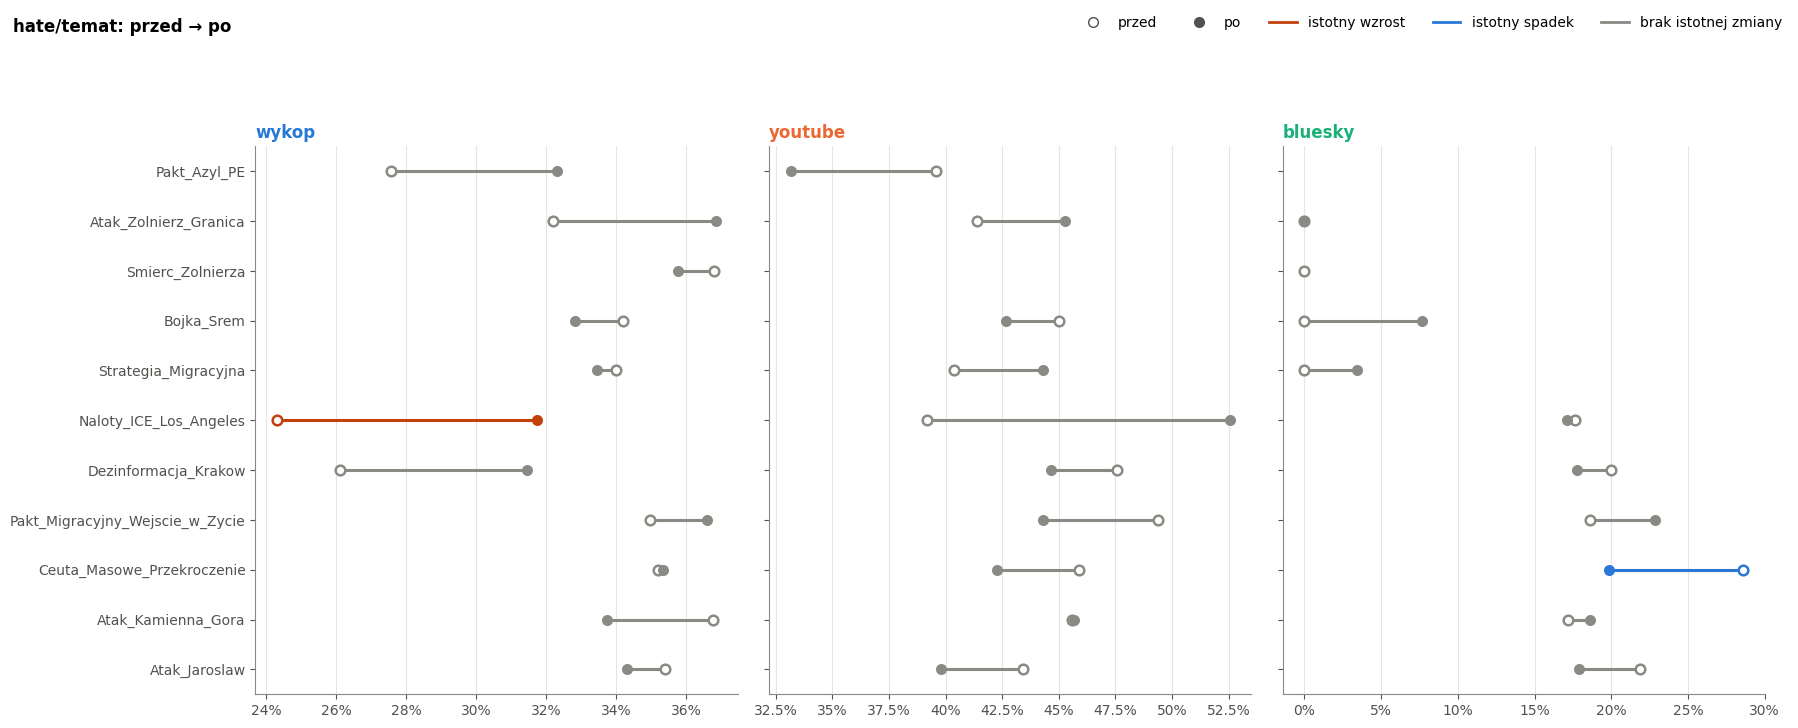

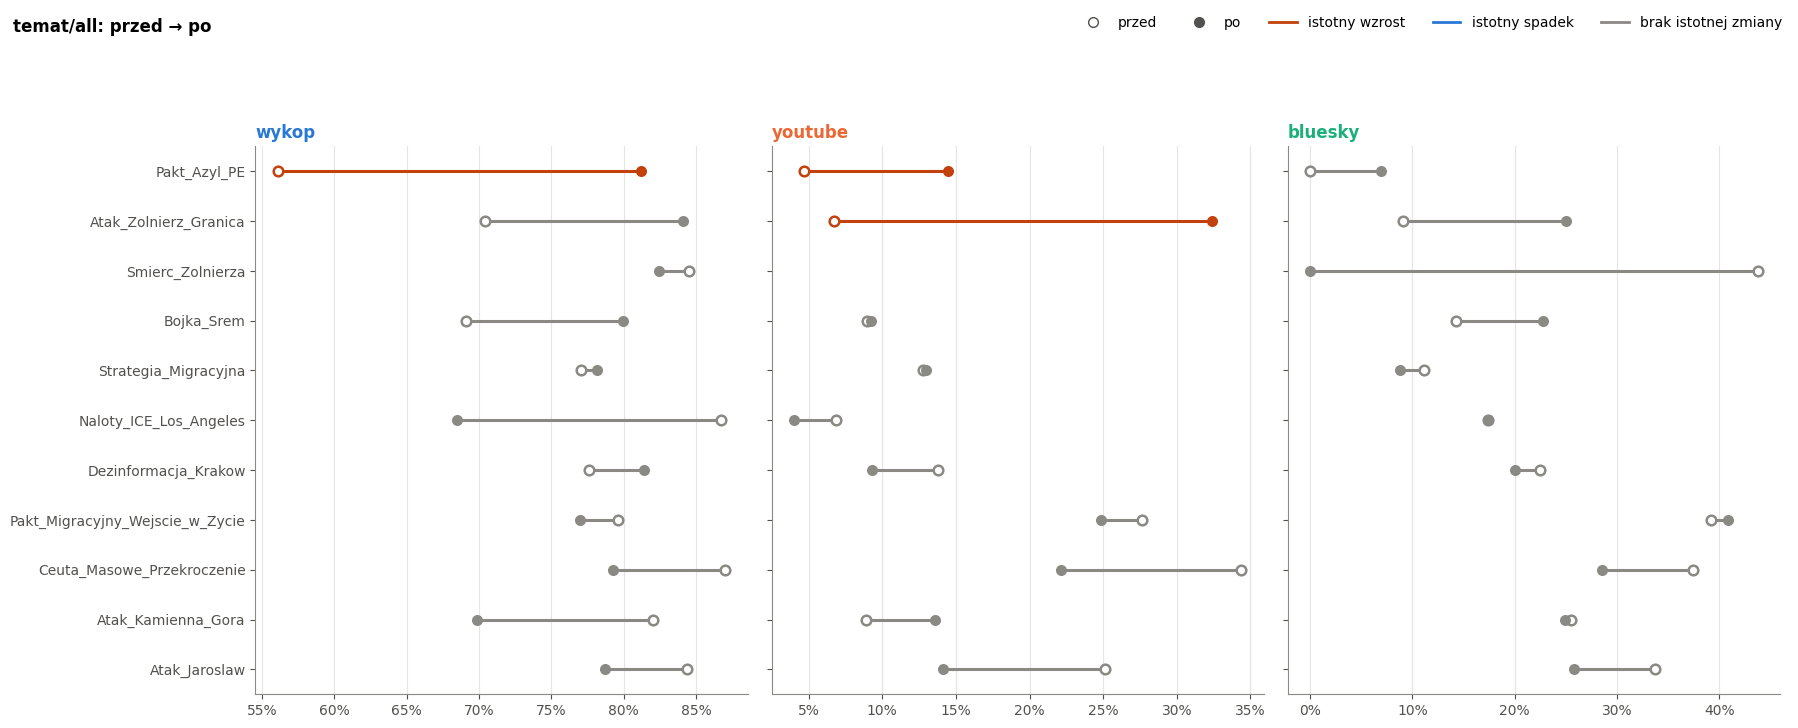

In [7]:
DIR_COLORS = {"↑": "#c2410c", "↓": "#2a78d6", "–": MUTED}
for metric in METRICS:
    fig, axes = plt.subplots(1, len(PL), figsize=(6 * len(PL), 0.5 * len(EVENT_ORDER) + 1.8), sharey=True)
    for ax, p in zip(axes, PL):
        e = E(metric)[E(metric)["platform"] == p].set_index("event").reindex(EVENT_ORDER)
        yy = np.arange(len(EVENT_ORDER))
        for yi, (ev, r) in zip(yy, e.iterrows()):
            if pd.isna(r["przed %"]):
                continue
            c = DIR_COLORS[r["kierunek"]] if isinstance(r["kierunek"], str) else MUTED
            ax.plot([r["przed %"], r["po %"]], [yi, yi], color=c, lw=2.2)
            ax.scatter(r["przed %"], yi, s=48, facecolor="white", edgecolor=c, linewidth=1.8, zorder=3)
            ax.scatter(r["po %"], yi, s=48, color=c, zorder=3)
        ax.set_yticks(yy, EVENT_ORDER)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
        ax.grid(axis="x", visible=True)
        ax.grid(axis="y", visible=False)
        ax.set_title(p, color=PLATFORM_COLORS[p])
    fig.suptitle(f"{metric}: przed → po", x=0.01, ha="left", fontweight="bold")
    fig.legend([plt.Line2D([], [], marker="o", ls="", ms=7, mfc="white", mec=INK2),
                plt.Line2D([], [], marker="o", ls="", ms=7, color=INK2),
                plt.Line2D([], [], color=DIR_COLORS["↑"]), plt.Line2D([], [], color=DIR_COLORS["↓"]),
                plt.Line2D([], [], color=MUTED)],
               ["przed", "po", "istotny wzrost", "istotny spadek", "brak istotnej zmiany"],
               loc="upper right", ncol=5, bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

**Liczby bezwzględne (średnia dzienna).** Komentarze i komentarze z hejtem na dzień, przed i po.
Słupki dla wydarzenia są **skumulowane po platformach** – wysokość całego słupka to suma platform, kolory pokazują,
skąd pochodzą komentarze. Odsetków z tej sumy nie liczymy (YouTube dominuje wolumenem).

komentarze/dzień przed  komentarze/dzień po  komentarze ×  temat/dzień przed  temat/dzień po  temat ×  hate/dzień przed  hate/dzień po  hate ×
wykop   Pakt_Azyl_PE                                      494.0                463.6           0.9              277.1           376.3      1.4              76.4          121.5     1.6
        Atak_Zolnierz_Granica                             408.9                530.2           1.3              287.9           446.0      1.5              92.7          164.4     1.8
        Smierc_Zolnierza                                  427.3                503.5           1.2              361.0           415.0      1.1             132.9          148.5     1.1
        Bojka_Srem                                        486.9                471.0           1.0              336.3           376.7      1.1             115.0          123.6     1.1
        Strategia_Migracyjna                              461.0                421.6           0.9              355.1           329.5      0.9             120.7          110.3     0.9
        Naloty_ICE_Los_Angeles                            494.0                418.9           0.8              428.3           286.9      0.7             104.1           91.1     0.9
        Dezinformacja_Krakow                              352.6                339.4           1.0              273.6           276.3      1.0              71.4           86.9     1.2
        Pakt_Migracyjny_Wejscie_w_Zycie                   507.4                442.4           0.9              404.0           340.5      0.8             141.3          124.6     0.9
        Ceuta_Masowe_Przekroczenie                        511.3                445.8           0.9              444.9           353.3      0.8             156.6          124.9     0.8
        Atak_Kamienna_Gora                                417.7                408.9           1.0              342.7           285.7      0.8             126.0           96.4     0.8
        Atak_Jaroslaw                                     489.3                564.3           1.2              412.9           444.3      1.1             146.1          152.5     1.0
youtube Pakt_Azyl_PE                                     5138.1               3421.9           0.7              240.7           495.9      2.1              95.3          164.5     1.7
        Atak_Zolnierz_Granica                            3685.0               4936.5           1.3              247.3          1600.3      6.5             102.3          724.5     7.1
        Bojka_Srem                                       3994.1               5287.5           1.3              357.7           486.9      1.4             161.0          207.8     1.3
        Strategia_Migracyjna                             3671.3               5927.0           1.6              468.3           769.5      1.6             189.1          340.8     1.8
        Naloty_ICE_Los_Angeles                           5810.7               4683.6           0.8              398.4           187.8      0.5             156.1           98.7     0.6
        Dezinformacja_Krakow                             2510.4               2457.1           1.0              346.9           228.3      0.7             165.0          101.9     0.6
        Pakt_Migracyjny_Wejscie_w_Zycie                  2701.3               4507.3           1.7              746.7          1121.6      1.5             368.6          497.1     1.3
        Ceuta_Masowe_Przekroczenie                       2423.0               3131.9           1.3              833.3           693.3      0.8             382.3          293.2     0.8
        Atak_Kamienna_Gora                               2119.0               6069.9           2.9              188.0           824.7      4.4              85.7          376.7     4.4
        Atak_Jaroslaw                                    4869.1               6595.0           1.4             1224.0           932.4      0.8             531.1          370.9  

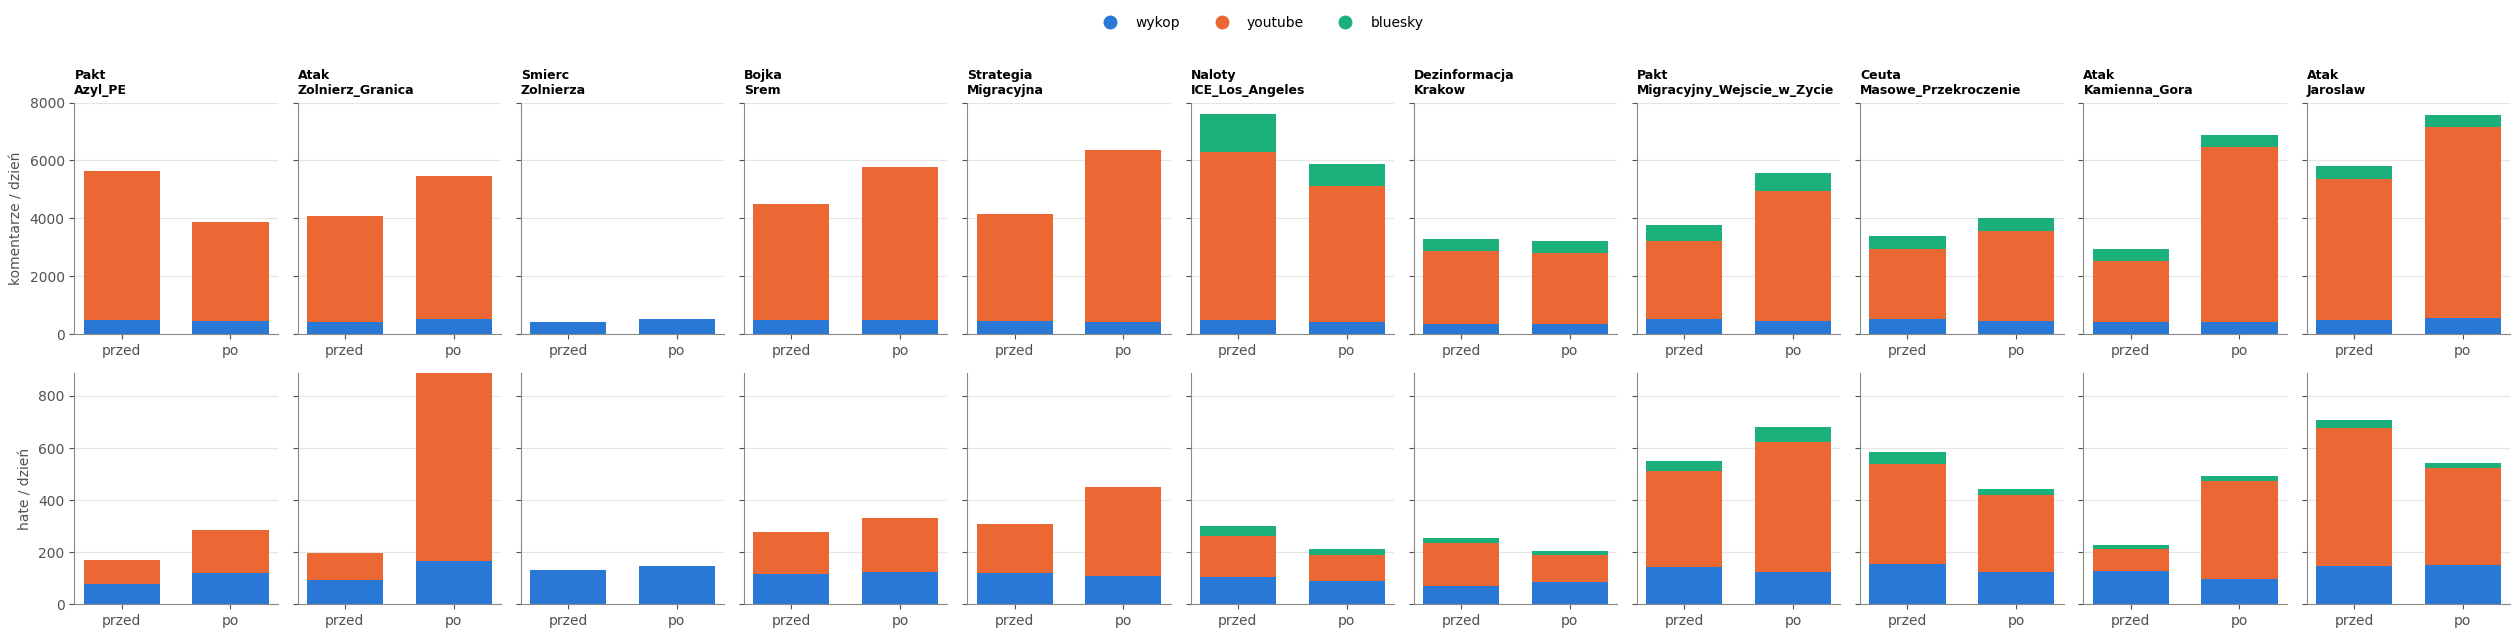

In [8]:
act = (df.groupby(["platform", "event", "okres"], sort=False)
       .agg(komentarze=("comment_id", "size"), hate=("hate", "sum"), temat=("temat", "sum")))
days = pd.Series({"przed": DAYS_PRE, "po": DAYS_POST})
per_day = act.div(act.index.get_level_values("okres").map(days).values, axis=0).unstack("okres")
counts_tab = pd.DataFrame(index=per_day.index)
for c in ["komentarze", "temat", "hate"]:
    counts_tab[f"{c}/dzień przed"] = per_day[(c, "przed")]
    counts_tab[f"{c}/dzień po"] = per_day[(c, "po")]
    counts_tab[f"{c} ×"] = per_day[(c, "po")] / per_day[(c, "przed")]
counts_tab = counts_tab.reindex(pd.MultiIndex.from_tuples([tuple(c.split(":")) for c in CELLS]))
display(counts_tab.round(1))

fig, axes = plt.subplots(2, len(EVENT_ORDER), figsize=(2.3 * len(EVENT_ORDER), 6.4), sharey="row")
for j, ev in enumerate(EVENT_ORDER):
    for i, (c, lab) in enumerate([("komentarze", "komentarze / dzień"), ("hate", "hate / dzień")]):
        ax = axes[i, j]
        bottom = np.zeros(2)
        for p in PL:
            if (p, ev) not in counts_tab.index:
                continue
            v = counts_tab.loc[(p, ev), [f"{c}/dzień przed", f"{c}/dzień po"]].values.astype(float)
            ax.bar([0, 1], v, bottom=bottom, color=PLATFORM_COLORS[p], width=0.7)
            bottom += v
        ax.set_xticks([0, 1], ["przed", "po"])
        if j == 0:
            ax.set_ylabel(lab)
        if i == 0:
            ax.set_title(ev.replace("_", "\n", 1), fontsize=9)
platform_legend(fig, top=0.92)
plt.show()

Dolny rząd to średnia dzienna liczba komentarzy z hejtem przed i po wydarzeniu, a górny rząd to średnia dzienna liczba wszystkich komentarzy.

### 1b. Wydarzenia wspólnie dla wszystkich platform

Dla każdego wydarzenia łączymy efekty platform **meta-analizą efektów stałych** (przy 2–3 platformach model efektów
losowych jest niestabilny). Romb = łączny OR wydarzenia, kropki = poszczególne platformy.
`p Q` mówi, czy platformy w tym wydarzeniu reagowały różnie.


=== hate/temat ===


,typ,platformy,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
Pakt_Azyl_PE,polityczne,"wykop, youtube",2,1.17,0.96,1.43,0.12,0.65,0.0906,0.747
Atak_Zolnierz_Granica,kryminalne,"wykop, youtube",2,1.22,1.02,1.46,0.0297,0.00,0.857,0.297
Smierc_Zolnierza,kryminalne,wykop,1,0.96,0.83,1.11,0.554,NaN,,1
Bojka_Srem,kryminalne,"wykop, youtube",2,0.93,0.78,1.11,0.45,0.00,0.891,1
Strategia_Migracyjna,polityczne,"wykop, youtube",2,1.04,0.89,1.22,0.585,0.17,0.273,1
Naloty_ICE_Los_Angeles,polityczne,"wykop, youtube, bluesky",3,1.30,1.15,1.48,4.85e-05,0.81,0.00521,0.000534
Dezinformacja_Krakow,dezinformacja,"wykop, youtube, bluesky",3,1.07,0.92,1.25,0.376,0.68,0.0431,1
Pakt_Migracyjny_Wejscie_w_Zycie,polityczne,"wykop, youtube, bluesky",3,1.09,0.98,1.22,0.107,0.63,0.0669,0.747
Ceuta_Masowe_Przekroczenie,kryzys graniczny,"wykop, youtube, bluesky",3,0.89,0.80,0.99,0.0364,0.79,0.00938,0.328



=== temat/all ===


,typ,platformy,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
Pakt_Azyl_PE,polityczne,"wykop, youtube",2,3.41,2.02,5.76,4.75e-06,0.00,0.967,5.23e-05
Atak_Zolnierz_Granica,kryminalne,"wykop, youtube",2,3.86,2.08,7.16,1.88e-05,0.67,0.0822,0.000188
Smierc_Zolnierza,kryminalne,wykop,1,0.86,0.33,2.25,0.761,NaN,,1
Bojka_Srem,kryminalne,"wykop, youtube",2,1.36,0.84,2.22,0.213,0.18,0.27,1
Strategia_Migracyjna,polityczne,"wykop, youtube",2,1.04,0.60,1.79,0.892,0.00,0.939,1
Naloty_ICE_Los_Angeles,polityczne,"wykop, youtube, bluesky",3,0.90,0.73,1.12,0.351,0.73,0.0255,1
Dezinformacja_Krakow,dezinformacja,"wykop, youtube, bluesky",3,0.88,0.67,1.17,0.395,0.00,0.459,1
Pakt_Migracyjny_Wejscie_w_Zycie,polityczne,"wykop, youtube, bluesky",3,1.02,0.79,1.31,0.909,0.00,0.776,1
Ceuta_Masowe_Przekroczenie,kryzys graniczny,"wykop, youtube, bluesky",3,0.64,0.49,0.84,0.0011,0.00,0.872,0.00986


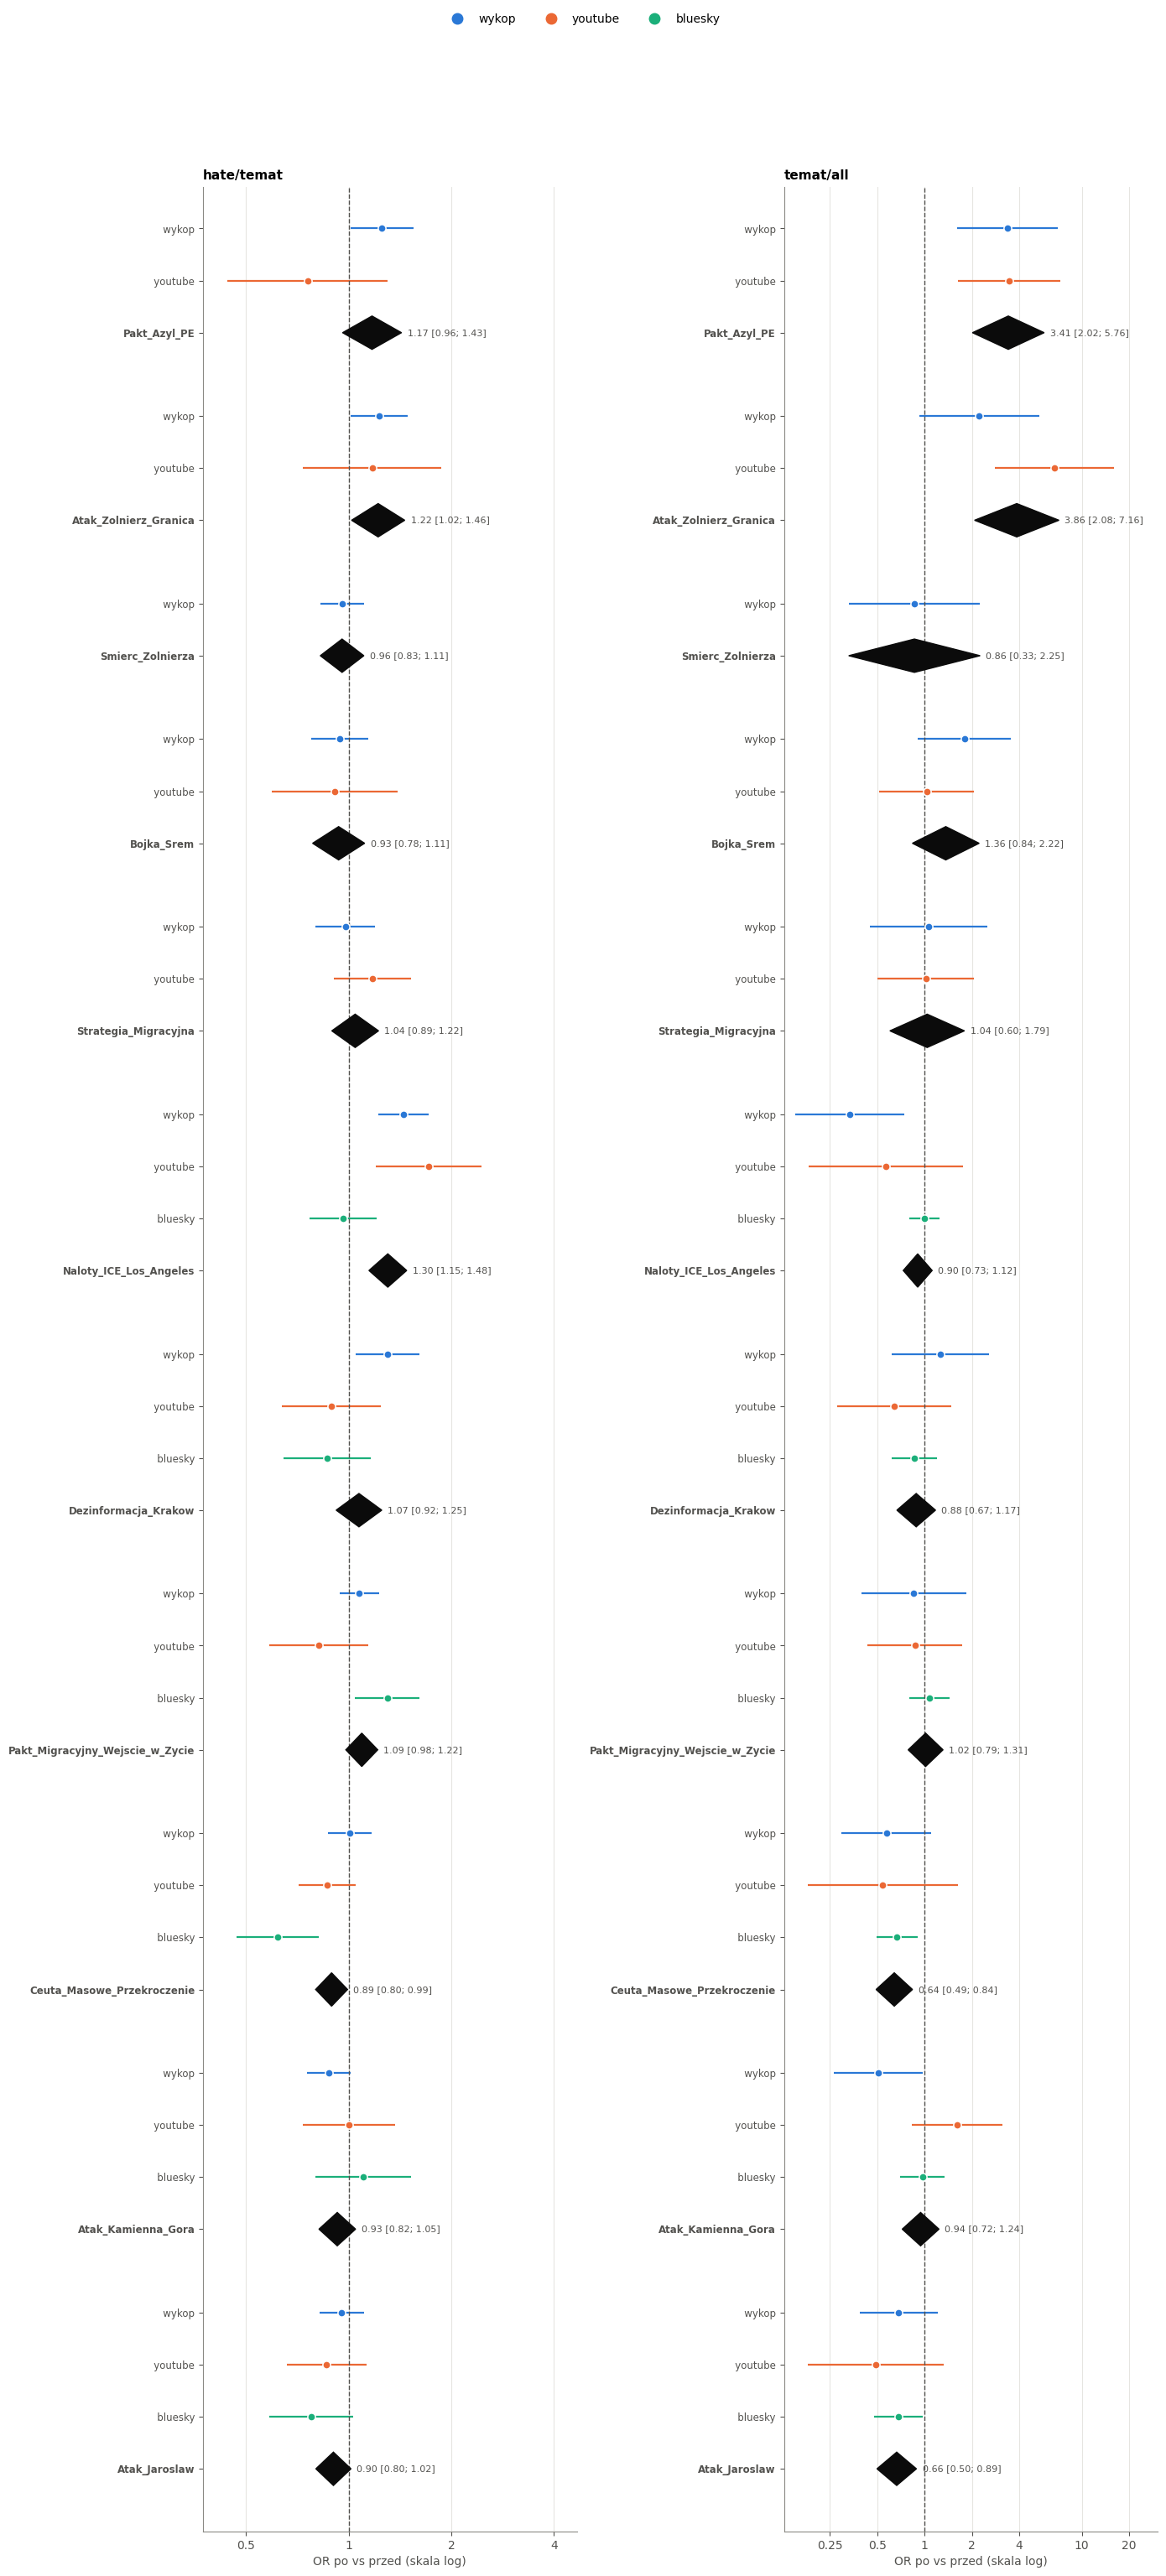

In [9]:
ev_rows = []
for metric in METRICS:
    for ev in EVENT_ORDER:
        e = E(metric)[E(metric)["event"] == ev].dropna(subset=["log OR"])
        m = meta_fixed(e["log OR"], e["se"])
        ev_rows.append({"miara": metric, "event": ev, "typ": EVENT_META[ev][0], "platformy": ", ".join(e["platform"]),
                        "k": m["k"], **or_row(m), "I²": m["I2"], "p Q": m["p Q"],
                        "mu": m["mu"], "se_mu": m["se"]})
ev_pool = pd.DataFrame(ev_rows)
ev_pool["p (Holm)"] = ev_pool.groupby("miara")["p"].transform(holm)
for metric in METRICS:
    print(f"\n=== {metric} ===")
    display(fmt_p(ev_pool[ev_pool["miara"] == metric].drop(columns=["miara", "mu", "se_mu"]).set_index("event"), 2))

fig, axes = plt.subplots(1, len(METRICS), figsize=(7 * len(METRICS), 0.62 * len(CELLS) + 0.9 * len(EVENT_ORDER) + 1))
for ax, metric in zip(axes, METRICS):
    groups = []
    for ev in EVENT_ORDER:
        e = E(metric)[E(metric)["event"] == ev].dropna(subset=["log OR"])
        r = ev_pool[(ev_pool["miara"] == metric) & (ev_pool["event"] == ev)].iloc[0]
        groups.append({"label": f"{ev}", "items": items_from(e.assign(lab="   " + e["platform"]), "lab",
                                                             lambda r_: PLATFORM_COLORS[r_["platform"]]),
                       "diamond": {"OR": r["OR"], "lo": r["OR lo"], "hi": r["OR hi"], "color": INK}})
    forest(ax, groups, title=metric)
platform_legend(fig, top=0.94)
plt.show()

Jak to czytać:

- Środek rombu (najszerszy punkt w pionie) to łączny OR wydarzenia, jego wartość jest wypisana obok.
- Lewy i prawy wierzchołek to granice 95% przedziału ufności.
- Przerywana linia przy 1 oznacza brak zmiany. Jeśli cały romb leży po jednej stronie tej linii, zmiana jest istotna;
  romb, który przecina 1, oznacza brak istotnej zmiany.

### 1c. Przed / po wspólnie dla wydarzeń, osobno na platformę (→ H4)

Dla każdej platformy łączymy jej wydarzenia **meta-analizą efektów losowych** (DerSimonian–Laird + Hartung–Knapp).
I² i `p Q` mówią, czy wydarzenia na tej platformie działają podobnie.

In [10]:
plat_rows = []
for metric in METRICS:
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        m = meta_random(e["log OR"], e["se"])
        plat_rows.append({"miara": metric, "platform": p, "wydarzeń": m["k"],
                          "wzrost w": f"{int((e['log OR'] > 0).sum())}/{len(e)}",
                          "istotnie ↑ / ↓": f"{int((e['kierunek'] == '↑').sum())} / {int((e['kierunek'] == '↓').sum())}",
                          "śr. zmiana pp": e["różnica pp"].mean(), **or_row(m), "I²": m["I2"], "p Q": m["p Q"],
                          "mu": m["mu"], "se_mu": m["se"]})
plat = pd.DataFrame(plat_rows)
display(fmt_p(plat.drop(columns=["mu", "se_mu"]).set_index(["miara", "platform"]), 2))

# poziomy dzienne pre/po (średnia z wydarzeń platformy) – tylko w obrębie platformy
lvl = (counts_tab.groupby(level=0).mean()
       [["komentarze/dzień przed", "komentarze/dzień po", "hate/dzień przed", "hate/dzień po"]]
       .reindex(PL))
print("Średnia dzienna na wydarzenie (średnia z wydarzeń platformy):")
display(lvl.round(1))

wydarzeń wzrost w istotnie ↑ / ↓  śr. zmiana pp    OR  OR lo  OR hi      p    I²       p Q
miara      platform                                                                                            
hate/temat wykop           11     6/11          1 / 0           1.53  1.07   0.96   1.19  0.195  0.70   0.00022
           youtube         10     4/10          0 / 0          -0.27  0.99   0.84   1.16  0.852  0.47    0.0507
           bluesky          6      2/6          0 / 1          -1.63  0.92   0.69   1.22  0.471  0.75   0.00116
temat/all  wykop           11     5/11          1 / 0           0.55  0.98   0.62   1.55  0.916  0.70  0.000284
           youtube         10     5/10          2 / 0           0.73  1.17   0.64   2.14  0.576  0.73  0.000119
           bluesky          6      1/6          0 / 0          -3.07  0.87   0.71   1.08  0.157  0.40     0.137

Średnia dzienna na wydarzenie (średnia z wydarzeń platformy):


,komentarze/dzień przed,komentarze/dzień po,hate/dzień przed,hate/dzień po
wykop,459.1,455.4,116.7,122.2
youtube,3692.2,4701.8,223.7,317.6
bluesky,325.6,279.2,17.9,14.3


### 1d. Przed / po wspólnie dla wydarzeń i platform (→ H1)

**Test główny H1:** meta-analiza efektów losowych ze **wszystkich komórek** (H0: łączny log-OR = 0).
**Potwierdzenie:** jeden model `y ~ po + C(komórka)` na wszystkich komentarzach z błędami klastrowanymi po wątku
(porównanie przed / po *w obrębie* komórki, ale duże komórki – YouTube – mają większą wagę).

In [11]:
all_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])
    m = meta_random(e["log OR"], e["se"])
    d, col = subset(df, metric)
    mod = logit_cluster(d, col, "y ~ po + C(cell)")
    b, s = mod.params["po"], mod.bse["po"]
    sign = stats.binomtest(int((e["log OR"] > 0).sum()), len(e), 0.5)
    all_rows.append({"miara": metric, "komórek": m["k"],
                     "istotnie ↑ / ↓ / –": f"{int((e['kierunek'] == '↑').sum())} / {int((e['kierunek'] == '↓').sum())} / "
                                           f"{int((e['kierunek'] == '–').sum())}",
                     "OR meta": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p meta": m["p"],
                     "I²": m["I2"], "τ²": m["tau2"],
                     "wzrost w": f"{int((e['log OR'] > 0).sum())}/{len(e)}", "p test znaków": sign.pvalue,
                     "OR model": np.exp(b), "OR model lo": np.exp(b - 1.96 * s), "OR model hi": np.exp(b + 1.96 * s),
                     "p model": mod.pvalues["po"], "mu": m["mu"], "se_mu": m["se"]})
pooled = pd.DataFrame(all_rows).set_index("miara")
display(fmt_p(pooled.drop(columns=["mu", "se_mu"]), 3))

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,komórek,istotnie ↑ / ↓ / –,OR meta,OR lo,OR hi,p meta,I²,τ²,wzrost w,p test znaków,OR model,OR model lo,OR model hi,p model
miara,,,,,,,,,,,,,,
hate/temat,27,1 / 1 / 25,1.015,0.935,1.102,0.715,0.655,0.023,12/27,0.701,0.987,0.925,1.054,0.693
temat/all,27,3 / 0 / 24,0.993,0.778,1.267,0.954,0.675,0.147,11/27,0.442,1.052,0.793,1.394,0.727


**Wykres lasu H1:** wszystkie komórki (kolor = platforma) pogrupowane po platformie, z rombem każdej platformy
i rombem łącznym dla wszystkich komórek na dole (czarny).

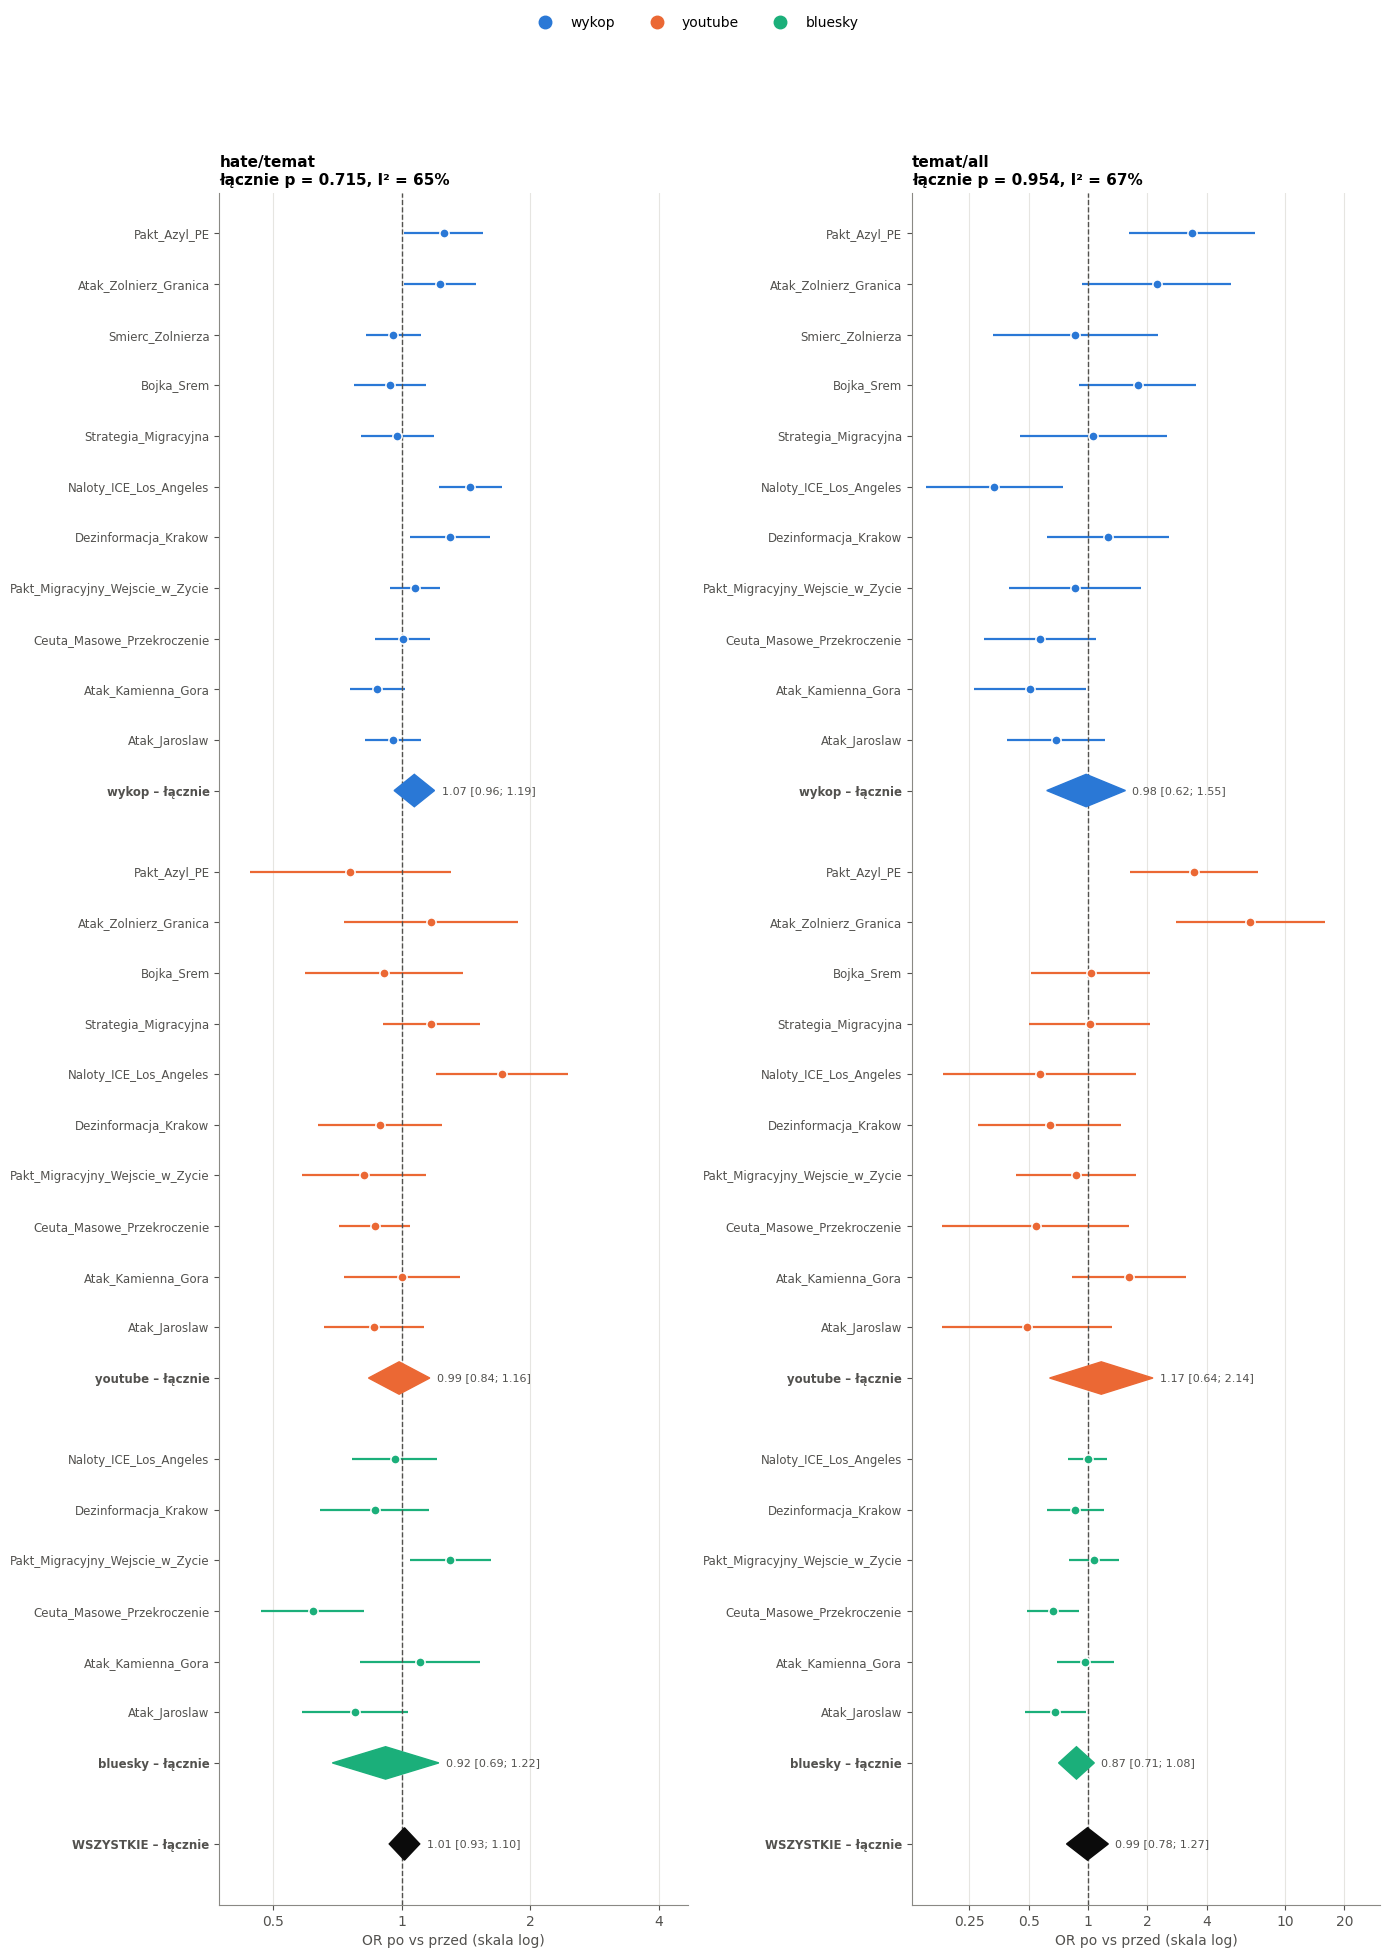

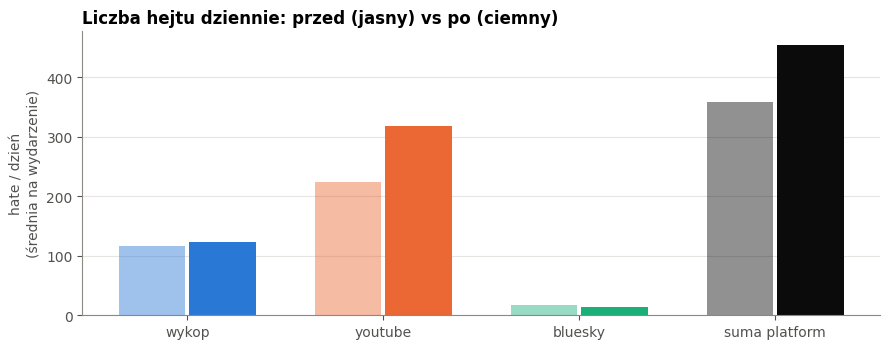

In [12]:
def platform_groups(metric, cells_filter=None):
    groups = []
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        if cells_filter is not None:
            e = e[e["event"].isin(cells_filter)]
        m = meta_random(e["log OR"], e["se"])
        groups.append({"label": f"{p} – łącznie", "items": items_from(e, "event", lambda r_: PLATFORM_COLORS[r_["platform"]]),
                       "diamond": dia(m, PLATFORM_COLORS[p])})
    return groups


fig, axes = plt.subplots(1, len(METRICS), figsize=(7 * len(METRICS), 0.5 * len(CELLS) + 3.6))
for ax, metric in zip(axes, METRICS):
    r = pooled.loc[metric]
    groups = platform_groups(metric)
    groups.append({"label": "WSZYSTKIE – łącznie", "items": [],
                   "diamond": {"OR": r["OR meta"], "lo": r["OR lo"], "hi": r["OR hi"], "color": INK}})
    forest(ax, groups, title=f"{metric}\nłącznie p = {r['p meta']:.3g}, I² = {r['I²']:.0%}")
platform_legend(fig, top=0.93)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(PL) + 1)
ax.bar(x[:-1] - 0.18, lvl["hate/dzień przed"], width=0.34, color=[PLATFORM_COLORS[p] for p in PL], alpha=0.45, label="przed")
ax.bar(x[:-1] + 0.18, lvl["hate/dzień po"], width=0.34, color=[PLATFORM_COLORS[p] for p in PL], label="po")
tot = lvl[["hate/dzień przed", "hate/dzień po"]].sum()
ax.bar(x[-1] - 0.18, tot.iloc[0], width=0.34, color=INK, alpha=0.45)
ax.bar(x[-1] + 0.18, tot.iloc[1], width=0.34, color=INK)
ax.set_xticks(x, [*PL, "suma platform"])
ax.set_ylabel("hate / dzień\n(średnia na wydarzenie)")
ax.set_title("Liczba hejtu dziennie: przed (jasny) vs po (ciemny)")
plt.tight_layout()
plt.show()

Słupki platform to średnia dzienna liczba komentarzy z hejtem uśredniona po wydarzeniach danej platformy. Dla każdego wydarzenia liczymy hejt na dzień (przed: liczba / 7, po: liczba / 15), a potem bierzemy średnią z wydarzeń.

### Wniosek ogólny: czy wydarzenia podnoszą hejt?

Wszystkie wydarzenia i platformy razem. Komórka niżej zbiera wyniki z 1d (meta-analiza i model na komentarzach)
oraz liczby bezwzględne z 1a i drukuje werdykt dla każdej miary.

**Jak czytać wykres:** jeden panel na miarę.
- **kropki** – OR „po vs przed” poszczególnych komórek (kolor = platforma) – pokazują, jak różne są wydarzenia,
- **romb** – łączny OR z meta-analizy efektów losowych (szerokość = 95% CI) – test główny,
- **kwadrat** – OR z jednego modelu na wszystkich komentarzach (duże komórki YouTube ważą tu więcej) – potwierdzenie.

Romb / kwadrat przecinający przerywaną linię 1 = brak systematycznej zmiany.

,werdykt,komórek,OR meta,OR lo,OR hi,p meta,I²,wzrost w,istotnie ↑ / ↓ / –,OR model,OR model lo,OR model hi,p model
miara,,,,,,,,,,,,,
hate/temat,BRAK systematycznej zmiany,27,1.015,0.935,1.102,0.715,0.655,12/27,1 / 1 / 25,0.987,0.925,1.054,0.693
temat/all,BRAK systematycznej zmiany,27,0.993,0.778,1.267,0.954,0.675,11/27,3 / 0 / 24,1.052,0.793,1.394,0.727


hate/temat (hejt (HerBERT) / komentarze w temacie migracji): BRAK systematycznej zmiany
    łączny OR = 1.01 [0.93; 1.10], p = 0.715; wzrost w 12/27 komórek; I² = 65% (zróżnicowanie wydarzeń)
    model na komentarzach: OR = 0.99 [0.92; 1.05], p = 0.693
temat/all (komentarze w temacie migracji / wszystkie komentarze): BRAK systematycznej zmiany
    łączny OR = 0.99 [0.78; 1.27], p = 0.954; wzrost w 11/27 komórek; I² = 67% (zróżnicowanie wydarzeń)
    model na komentarzach: OR = 1.05 [0.79; 1.39], p = 0.727

Liczby bezwzględne (suma 32 komórek, na dzień): komentarze 45,554 → 55,098 (×1.21), hate 3,717 → 4,678 (×1.26)


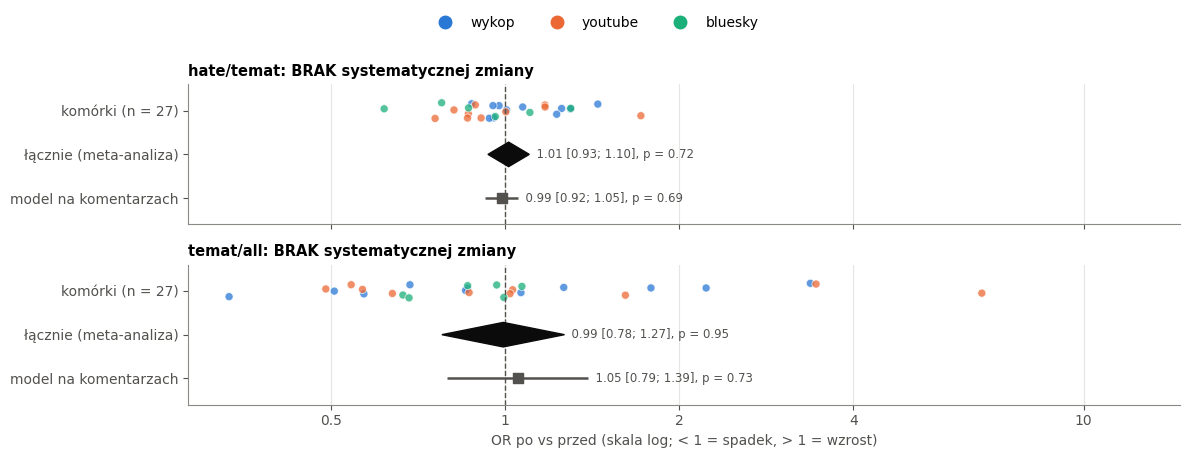

In [13]:
def overall_verdict(r):
    if r["p meta"] >= ALPHA:
        return "BRAK systematycznej zmiany"
    return "istotny WZROST" if r["OR meta"] > 1 else "istotny SPADEK"


overall = pooled[["komórek", "OR meta", "OR lo", "OR hi", "p meta", "I²", "wzrost w", "istotnie ↑ / ↓ / –",
                  "OR model", "OR model lo", "OR model hi", "p model"]].copy()
overall.insert(0, "werdykt", [overall_verdict(r) for _, r in pooled.iterrows()])
display(fmt_p(overall, 3))

for metric, r in pooled.iterrows():
    model = (f"model na komentarzach: OR = {r['OR model']:.2f} [{r['OR model lo']:.2f}; {r['OR model hi']:.2f}], "
             f"p = {r['p model']:.3g}" + (" – istotny" if r["p model"] < ALPHA else ""))
    print(f"{metric} ({METRIC_NAMES[metric]}): {overall_verdict(r)}\n"
          f"    łączny OR = {r['OR meta']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}], p = {r['p meta']:.3g}; "
          f"wzrost w {r['wzrost w']} komórek; I² = {r['I²']:.0%} (zróżnicowanie wydarzeń)\n    {model}")

# liczby bezwzględne: suma po wszystkich komórkach, średnio na dzień
tot = counts_tab.sum()
print(f"\nLiczby bezwzględne (suma {len(counts_tab)} komórek, na dzień): "
      f"komentarze {tot['komentarze/dzień przed']:,.0f} → {tot['komentarze/dzień po']:,.0f} "
      f"(×{tot['komentarze/dzień po'] / tot['komentarze/dzień przed']:.2f}), "
      f"hate {tot['hate/dzień przed']:,.0f} → {tot['hate/dzień po']:,.0f} "
      f"(×{tot['hate/dzień po'] / tot['hate/dzień przed']:.2f})")

fig, axes = plt.subplots(len(METRICS), 1, figsize=(12, 1.7 * len(METRICS) + 1.2), sharex=True)
rng = np.random.default_rng(0)
xs = []
for ax, metric in zip(axes, METRICS):
    e, r = E(metric).dropna(subset=["OR"]), pooled.loc[metric]
    ax.scatter(e["OR"], 2 + rng.uniform(-0.18, 0.18, len(e)), s=34, color=e["platform"].map(PLATFORM_COLORS).tolist(),
               alpha=0.75, edgecolor="white", linewidth=0.6, zorder=2)
    ax.fill([r["OR lo"], r["OR meta"], r["OR hi"], r["OR meta"]], [1, 1.28, 1, 0.72], color=INK, zorder=3)
    ax.hlines(0, r["OR model lo"], r["OR model hi"], color=INK2, lw=1.8)
    ax.scatter(r["OR model"], 0, marker="s", s=42, color=INK2, zorder=3)
    for y, o, lo, hi, p in [(1, r["OR meta"], r["OR lo"], r["OR hi"], r["p meta"]),
                            (0, r["OR model"], r["OR model lo"], r["OR model hi"], r["p model"])]:
        ax.text(hi, y, f"  {o:.2f} [{lo:.2f}; {hi:.2f}], p = {p:.2g}", va="center", fontsize=8.5, color=INK2)
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_yticks([2, 1, 0], [f"komórki (n = {len(e)})", "łącznie (meta-analiza)", "model na komentarzach"])
    ax.set_ylim(-0.6, 2.6)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(f"{metric}: {overall_verdict(r)}", fontsize=10.5)
    xs += [*e["OR"], r["OR lo"], r["OR hi"], r["OR model lo"], r["OR model hi"]]
axes[-1].set_xscale("log")
axes[-1].set_xlim(min(xs) * 0.85, max(xs) * 2.2)
log_ticks(axes[-1], "x")
axes[-1].set_xlabel("OR po vs przed (skala log; < 1 = spadek, > 1 = wzrost)")
platform_legend(fig, top=0.9)
plt.show()

### 1f. Test H4: czy efekt wydarzeń różni się między platformami?

- **Test główny:** różnica podgrup w meta-analizie – czy łączne efekty platform (1c) różnią się bardziej niż przez
  przypadek (statystyka Q między platformami).
- **Model z interakcją:** `y ~ po + po:C(platforma) + C(komórka)`, test Walda wszystkich interakcji `po:platforma`.
- **Pary platform:** stosunek OR (ROR = OR A / OR B) z łącznych efektów platform, korekta Holma dla par.
  ROR > 1 = po wydarzeniach odsetek na platformie A zmienia się bardziej „w górę” niż na B (nie: „na A jest więcej hejtu”).
- **Zbalansowany panel (3 platformy):** test Q i Wald tylko na wydarzeniach wspólnych dla **wszystkich** platform
  (Dezinformacja_Krakow, Ceuta, Atak_Kamienna_Gora) – różnica nie wynika z różnych zestawów wydarzeń.
- **Wspólne wydarzenia pary:** każdą parę platform porównujemy na wydarzeniach, które mają **obie** platformy
  tej pary. Dla wykop / youtube to 6 wydarzeń (wszystkie poza Smierc_Zolnierza), dla par z Bluesky – 3.

Porównujemy **wielkość zmiany**, nie poziomy.

In [14]:
def wald(d, col, formula, keep):
    """Test Walda dla współczynników, których nazwy spełniają keep(name); logit z klastrami po wątku."""
    m = logit_cluster(d, col, formula)
    idx = [i for i, n in enumerate(m.params.index) if keep(n)]
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue), m


def pair_events(a, b):
    # wydarzenia, które mają komórkę na obu platformach pary
    return [e for e in EVENT_ORDER if f"{a}:{e}" in CELLS and f"{b}:{e}" in CELLS]


def platform_meta(metric, events=None):
    out = {}
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        if events is not None:
            e = e[e["event"].isin(events)]
        out[p] = meta_random(e["log OR"], e["se"])
    return out


h4_rows, ror_rows = [], []
for metric in METRICS:
    pm = platform_meta(metric)
    q, pq = q_test([pm[p]["mu"] for p in PL], [pm[p]["se"] for p in PL])
    pmb = platform_meta(metric, COMMON_EVENTS)
    qb, pqb = q_test([pmb[p]["mu"] for p in PL], [pmb[p]["se"] for p in PL])
    d, col = subset(df, metric)
    pw, mw = wald(d, col, "y ~ po + po:C(platform) + C(cell)", lambda n: n.startswith("po:C(platform)"))
    pwb, _ = wald(d[d["event"].isin(COMMON_EVENTS)], col, "y ~ po + po:C(platform) + C(cell)",
                  lambda n: n.startswith("po:C(platform)"))
    h4_rows.append({"miara": metric, "Q między platformami": q, "p Q (wszystkie komórki)": pq,
                    "p Q (zbalansowany panel)": pqb, "p Wald po×platforma": pw, "p Wald (zbalansowany)": pwb,
                    **{f"OR {p}": np.exp(pm[p]["mu"]) for p in PL},
                    **{f"OR {p} (panel)": np.exp(pmb[p]["mu"]) for p in PL}})
    for a, b in combinations(PL, 2):
        pe = pair_events(a, b)
        pmp = platform_meta(metric, pe)
        for scope, mm in [("wszystkie komórki", pm), ("wspólne wydarzenia pary", pmp)]:
            dlt, s = mm[a]["mu"] - mm[b]["mu"], np.hypot(mm[a]["se"], mm[b]["se"])
            ror_rows.append({"miara": metric, "zakres": scope, "para": f"{a} / {b}",
                             "wydarzeń": f"{mm[a]['k']} / {mm[b]['k']}", "ROR": np.exp(dlt),
                             "ROR lo": np.exp(dlt - 1.96 * s), "ROR hi": np.exp(dlt + 1.96 * s),
                             "p": 2 * stats.norm.sf(abs(dlt / s))})
h4 = pd.DataFrame(h4_rows).set_index("miara")
ror = pd.DataFrame(ror_rows)
ror["p (Holm)"] = ror.groupby(["miara", "zakres"])["p"].transform(holm)
print("Test H4:")
display(fmt_p(h4, 3))
print("Pary platform (ROR > 1 = silniejsza zmiana względna na pierwszej platformie):")
display(fmt_p(ror.set_index(["miara", "zakres", "para"]), 3))

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Test H4:


,Q między platformami,p Q (wszystkie komórki),p Q (zbalansowany panel),p Wald po×platforma,p Wald (zbalansowany),OR wykop,OR youtube,OR bluesky,OR wykop (panel),OR youtube (panel),OR bluesky (panel)
miara,,,,,,,,,,,
hate/temat,2.057,0.358,0.303,0.033,0.02,1.070,0.986,0.917,1.084,0.986,0.917
temat/all,1.241,0.538,0.534,0.358,0.335,0.978,1.167,0.873,0.989,1.167,0.873


Pary platform (ROR > 1 = silniejsza zmiana względna na pierwszej platformie):


wydarzeń    ROR  ROR lo  ROR hi      p p (Holm)
miara      zakres                  para                                                             
hate/temat wszystkie komórki       wykop / youtube    11 / 10  1.085   0.914   1.289  0.352    0.703
           wspólne wydarzenia pary wykop / youtube    10 / 10  1.099   0.922   1.311  0.293    0.611
           wszystkie komórki       wykop / bluesky     11 / 6  1.167   0.919   1.482  0.204    0.611
           wspólne wydarzenia pary wykop / bluesky     11 / 6  1.167   0.919   1.482  0.204    0.611
           wszystkie komórki       youtube / bluesky   10 / 6  1.076   0.828   1.397  0.584    0.703
           wspólne wydarzenia pary youtube / bluesky   10 / 6  1.076   0.828   1.397  0.584    0.611
temat/all  wszystkie komórki       wykop / youtube    11 / 10  0.838   0.432   1.623  0.599        1
           wspólne wydarzenia pary wykop / youtube    10 / 10  0.847   0.427   1.682  0.635        1
           wszystkie komórki       wykop / bluesky     11 / 6  1.120   0.725   1.729  0.611        1
           wspólne wydarzenia pary wykop / bluesky     11 / 6  1.120   0.725   1.729  0.611        1
           wszystkie komórki       youtube / bluesky   10 / 6  1.337   0.773   2.310  0.299    0.896
           wspólne wydarzenia pary youtube / bluesky   10 / 6  1.337   0.773   2.310  0.299    0.896

**Wykresy H4:** (lewy) wykres interakcji – indeks przed → po dla każdej platformy (przed = 1, po = łączny OR platformy
z 95% CI); (prawy) OR tych samych wydarzeń na każdej platformie obok siebie – wszystkie wydarzenia obecne na ≥ 2 platformach.

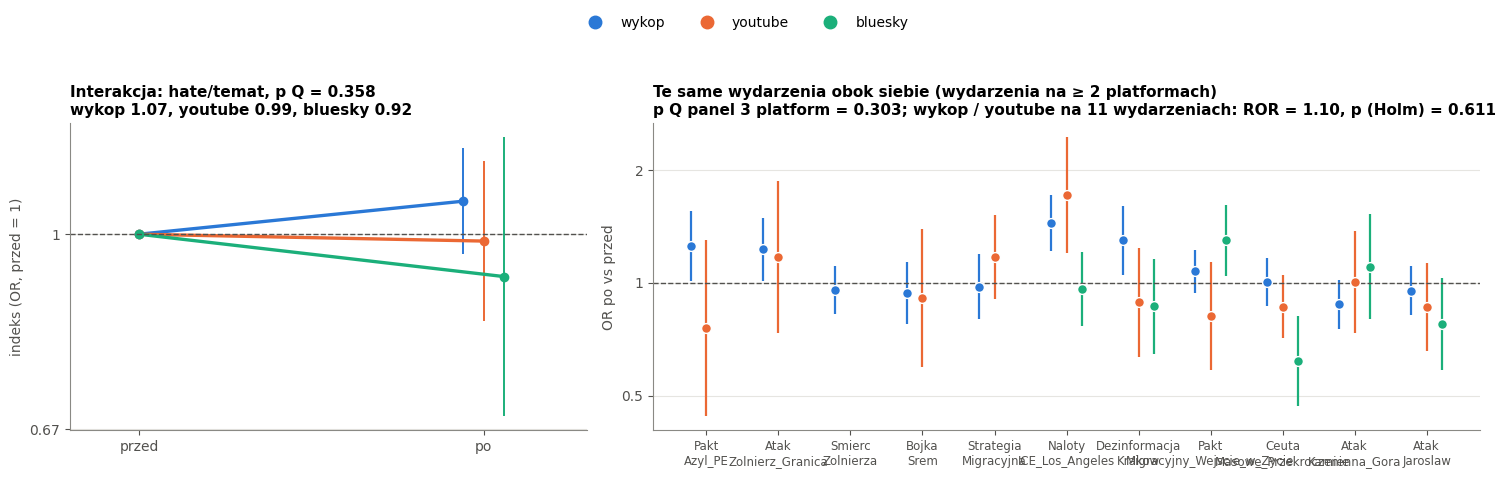

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
pm = platform_meta(MAIN)
for i, p in enumerate(PL):
    m = pm[p]
    xo = 1 + (i - 1) * 0.06
    ax.plot([0, xo], [1, np.exp(m["mu"])], color=PLATFORM_COLORS[p], lw=2.4, marker="o")
    ax.vlines(xo, np.exp(m["lo"]), np.exp(m["hi"]), color=PLATFORM_COLORS[p], lw=1.4)
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_xticks([0, 1], ["przed", "po"])
ax.set_xlim(-0.2, 1.3)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_ylabel("indeks (OR, przed = 1)")
ax.set_title(f"Interakcja: {MAIN}, p Q = {h4.loc[MAIN, 'p Q (wszystkie komórki)']:.3g}\n"
             + ", ".join(f"{p} {np.exp(pm[p]['mu']):.2f}" for p in PL), fontsize=11)

ax = axes[1]
shared = [e for e in EVENT_ORDER if sum(f"{p}:{e}" in CELLS for p in PL) >= 2]  # wydarzenia na ≥ 2 platformach
pos = {ev: i for i, ev in enumerate(shared)}
offs = np.linspace(-0.22, 0.22, len(PL))
for off, p in zip(offs, PL):
    e = E(MAIN)[(E(MAIN)["platform"] == p) & E(MAIN)["event"].isin(shared)].dropna(subset=["OR"])
    xx = e["event"].map(pos) + off
    ax.vlines(xx, e["OR lo"], e["OR hi"], color=PLATFORM_COLORS[p], lw=1.6)
    ax.scatter(xx, e["OR"], s=50, color=PLATFORM_COLORS[p], zorder=3, edgecolor="white")
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_xticks(range(len(shared)), [ev.replace("_", "\n", 1) for ev in shared], fontsize=8.5)
ax.set_ylabel("OR po vs przed")
r_wy = ror[(ror["miara"] == MAIN) & (ror["zakres"] == "wspólne wydarzenia pary") & (ror["para"] == "wykop / youtube")].iloc[0]
ax.set_title(f"Te same wydarzenia obok siebie (wydarzenia na ≥ 2 platformach)\n"
             f"p Q panel 3 platform = {h4.loc[MAIN, 'p Q (zbalansowany panel)']:.3g}; "
             f"wykop / youtube na {len(shared)} wydarzeniach: ROR = {r_wy['ROR']:.2f}, p (Holm) = {r_wy['p (Holm)']:.3g}",
             fontsize=11)
platform_legend(fig, top=0.86)
plt.show()



**Wnioski H4 (27 komórek z wystarczającą liczbą komentarzy):**

- **Platformy reagują na wydarzenia podobnie:** łączne OR platform – Wykop 1,07, YouTube 0,99, Bluesky 0,92 – nie różnią się
  w metaanalizie (Q: p = 0,36; zbalansowany panel p = 0,30), a żadna para platform nie różni się po Holmie (p ≥ 0,61).
- Model Walda na wszystkich komentarzach daje p = 0,03 (zbalansowany 0,02): na Wykopie hejt po wydarzeniach minimalnie
  rośnie, na Bluesky minimalnie spada. Ten model waży komentarze, więc to słaby sygnał, nie różnica w metaanalizie.
- `temat/all`: brak różnic (Q p = 0,54, Wald p = 0,36).
- **Werdykt H4 (reakcja): niepotwierdzona**, słaby sygnał tylko w modelu na komentarzach. Poziomy – sekcja 8.

## 2. Top 3 największe zmiany na osi czasu

**Ranking:** |log RR| miary `hate/temat` – największe zmiany względne w którąkolwiek stronę. Do rankingu wchodzą
tylko komórki **istotne po korekcie Holma** i z co najmniej `MIN_K_PRE_TOP` komentarzami z hejtem „przed”
(mała baza daje absurdalne RR). Jeśli takich komórek jest mniej niż 3, lista jest uzupełniana kolejnymi (nieistotnymi)
komórkami – w tytule wykresu jest wtedy dopisek *nieistotne*.

**Oś czasu:** dni −7..+14, linia przerywana = dzień 0, pozioma kropkowana = średnia „przed”. Linia = dzienny %
ze średnią kroczącą 3-dniową (dni z ≥ `MIN_DAILY_N` komentarzami w mianowniku). Szare słupki w tle = liczba
komentarzy dziennie (prawa oś) – pokazują, kiedy % jest liczony z małej próby.
Gdy na jednym wykresie jest kilka platform, oś Y to **indeks = % dzienny / średnia „przed”** (1 = bez zmiany).


wykop: top 3


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
wykop:Naloty_ICE_Los_Angeles,1.31,1.21,1.41,7.42,0.000572,↑,False
wykop:Dezinformacja_Krakow,1.20,1.10,1.31,5.33,0.414,–,True
wykop:Pakt_Azyl_PE,1.17,1.08,1.27,4.72,0.832,–,True


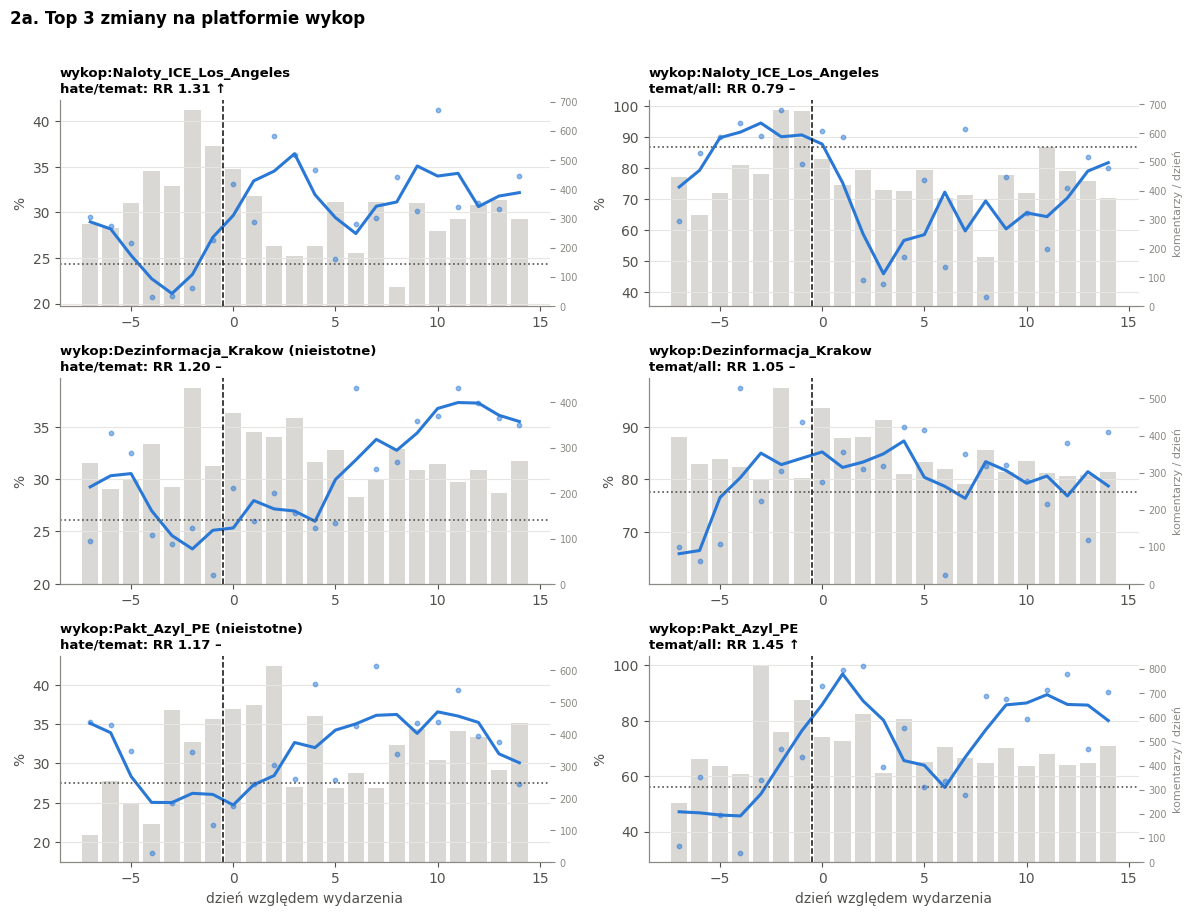


youtube: top 3


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
youtube:Naloty_ICE_Los_Angeles,1.34,1.27,1.42,13.35,0.0741,–,True
youtube:Pakt_Azyl_PE,0.84,0.78,0.90,-6.42,1,–,True
youtube:Pakt_Migracyjny_Wejscie_w_Zycie,0.90,0.87,0.93,-5.04,1,–,True


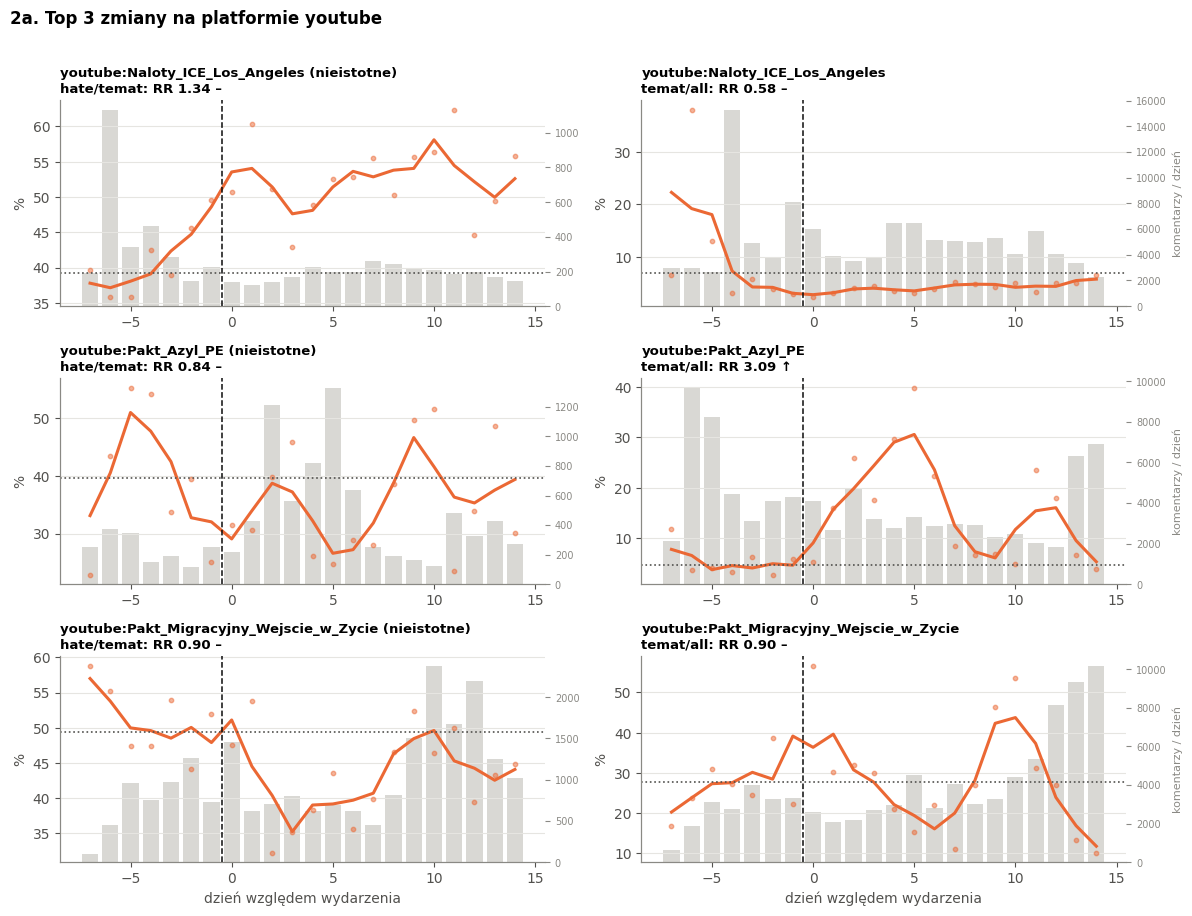


bluesky: top 3


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
bluesky:Ceuta_Masowe_Przekroczenie,0.69,0.61,0.79,-8.74,0.0181,↓,False
bluesky:Pakt_Migracyjny_Wejscie_w_Zycie,1.23,1.09,1.39,4.29,0.434,–,True
bluesky:Atak_Jaroslaw,0.82,0.70,0.96,-4.00,1,–,True


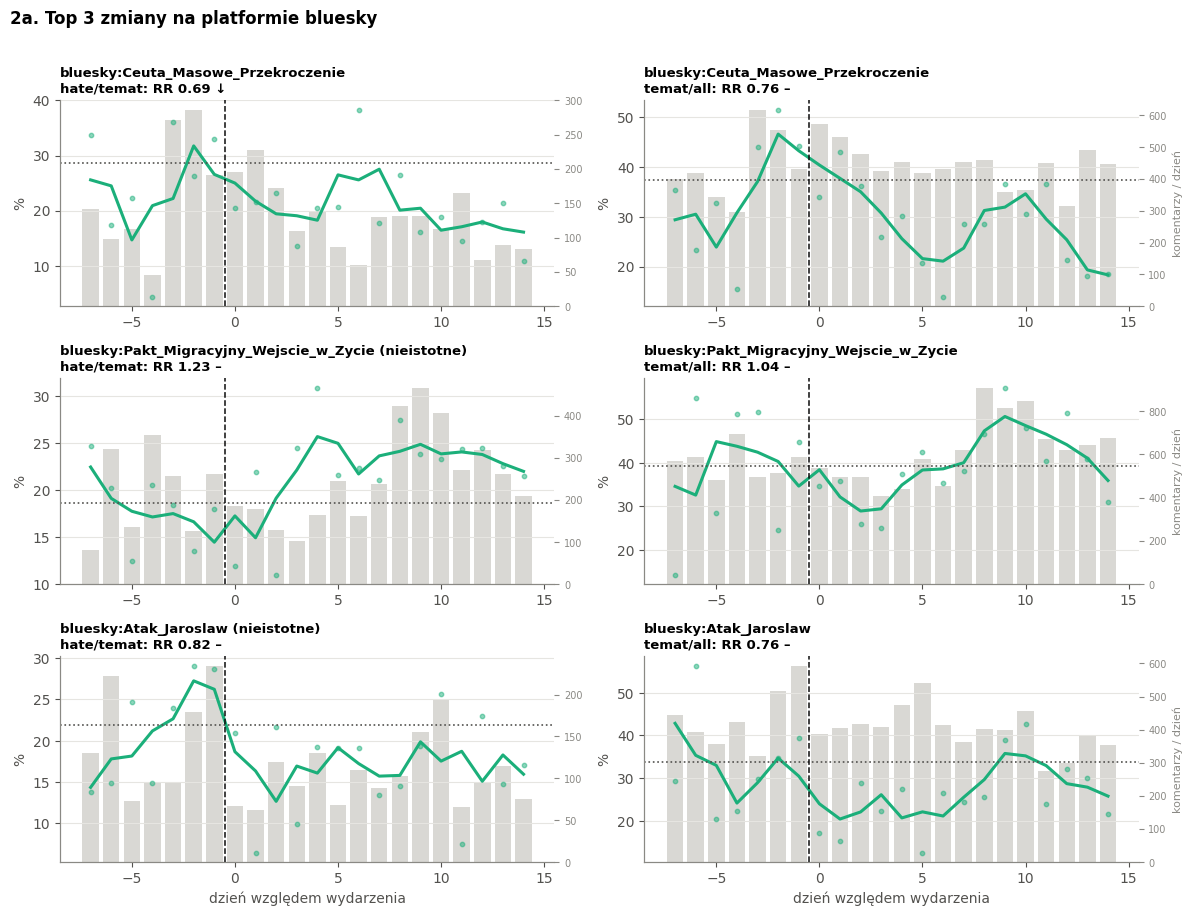

In [16]:
DAYS = range(WINDOW[0], WINDOW[1] + 1)


def daily_cell(cell, metric):
    d, col = subset(df[df["cell"] == cell], metric)
    g = d.groupby("relative_day").agg(num=(col, "sum"), den=(col, "size")).reindex(DAYS, fill_value=0)
    share = (100 * g["num"] / g["den"]).where(g["den"] >= MIN_DAILY_N)
    pre = g.loc[g.index < POST_FROM_DAY]
    base = 100 * pre["num"].sum() / max(pre["den"].sum(), 1)
    return share, base, g["den"]


def rank_cells(e):
    e = e.dropna(subset=["RR"]).assign(abs_lrr=lambda x: np.log(x["RR"]).abs())
    ok = e[e["istotne"] & (e["k przed"] >= MIN_K_PRE_TOP)].sort_values("abs_lrr", ascending=False)
    rest = e[~e.index.isin(ok.index) & (e["k przed"] >= MIN_K_PRE_TOP)].sort_values("abs_lrr", ascending=False)
    top = pd.concat([ok.assign(nieistotne=False), rest.assign(nieistotne=True)]).head(TOP_K)
    return top


def plot_cells(top, title):
    fig, axes = plt.subplots(len(top), len(METRICS), figsize=(6 * len(METRICS), 3.1 * len(top)), squeeze=False)
    for i, (_, r) in enumerate(top.iterrows()):
        for j, metric in enumerate(METRICS):
            ax = axes[i, j]
            share, base, den = daily_cell(r["cell"], metric)
            ax2 = ax.twinx()
            ax2.bar(list(DAYS), den.values, color="#d9d8d4", width=0.8, zorder=0)
            ax2.set_ylabel("komentarzy / dzień" if j == len(METRICS) - 1 else "", color=MUTED, fontsize=8)
            ax2.tick_params(axis="y", colors=MUTED, labelsize=7)
            ax2.grid(False)
            ax.set_zorder(ax2.get_zorder() + 1)
            ax.patch.set_visible(False)
            c = PLATFORM_COLORS[r["platform"]]
            ax.plot(list(DAYS), share.rolling(ROLL_DAYS, center=True, min_periods=1).mean(), color=c, lw=2.2)
            ax.scatter(list(DAYS), share.values, s=10, color=c, alpha=0.5)
            ax.axhline(base, color=INK2, ls=":", lw=1.2)
            ax.axvline(POST_FROM_DAY - 0.5, color=INK, ls="--", lw=1.1)
            ax.set_ylabel("%")
            em = E(metric).set_index("cell").loc[r["cell"]]
            tag = " (nieistotne)" if r["nieistotne"] else ""
            ax.set_title(f"{r['cell']}{tag if j == 0 else ''}\n{metric}: RR {em['RR']:.2f} {em['kierunek']}", fontsize=9.5)
            if i == len(top) - 1:
                ax.set_xlabel("dzień względem wydarzenia")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


rank_all = rank_cells(E(MAIN))
for p in PL:
    top = rank_cells(E(MAIN)[E(MAIN)["platform"] == p])
    print(f"\n{p}: top {TOP_K}")
    display(fmt_p(top.set_index("cell")[["RR", "RR lo", "RR hi", "różnica pp", "p (Holm)", "kierunek", "nieistotne"]], 2))
    plot_cells(top, f"2a. Top {TOP_K} zmiany na platformie {p}")

2b. Top 3 komórek ze wszystkich platform (bez łączenia):


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
bluesky:Ceuta_Masowe_Przekroczenie,0.69,0.61,0.79,-8.74,0.0181,↓,False
wykop:Naloty_ICE_Los_Angeles,1.31,1.21,1.41,7.42,0.000572,↑,False
youtube:Naloty_ICE_Los_Angeles,1.34,1.27,1.42,13.35,0.0741,–,True


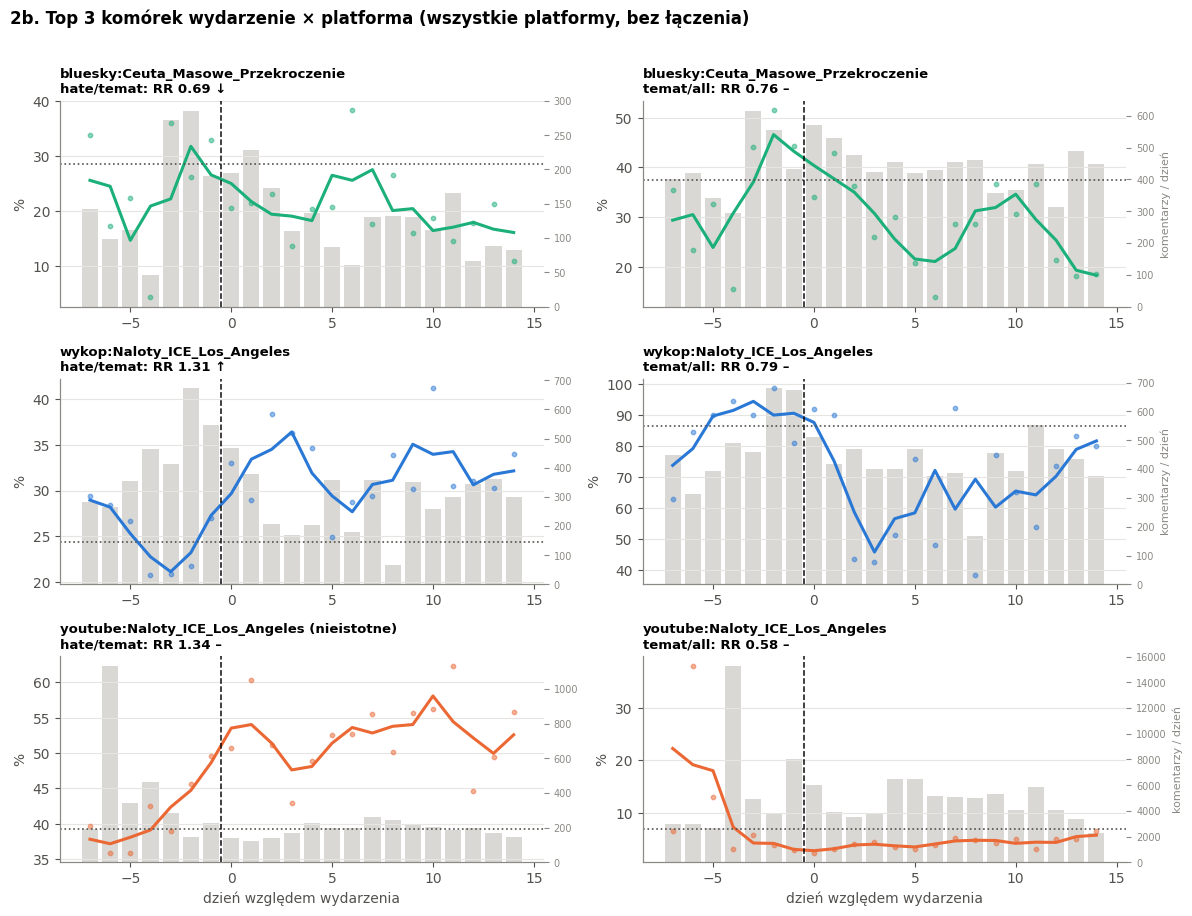

In [17]:
print(f"2b. Top {TOP_K} komórek ze wszystkich platform (bez łączenia):")
display(fmt_p(rank_all.set_index("cell")[["RR", "RR lo", "RR hi", "różnica pp", "p (Holm)", "kierunek", "nieistotne"]], 2))
plot_cells(rank_all, f"2b. Top {TOP_K} komórek wydarzenie × platforma (wszystkie platformy, bez łączenia)")

**2c. Top 3 wydarzenia łącząc platformy:** ranking po |łącznym log-OR| z widoku 1b (efekty stałe po platformach),
tylko wydarzenia z co najmniej 2 platformami. Linie = platformy, oś Y = indeks względem średniej „przed”.

,platformy,OR,OR lo,OR hi,p (Holm),nieistotne
event,,,,,,
Naloty_ICE_Los_Angeles,"wykop, youtube, bluesky",1.30,1.15,1.48,0.000534,False
Atak_Zolnierz_Granica,"wykop, youtube",1.22,1.02,1.46,0.297,True
Pakt_Azyl_PE,"wykop, youtube",1.17,0.96,1.43,0.747,True


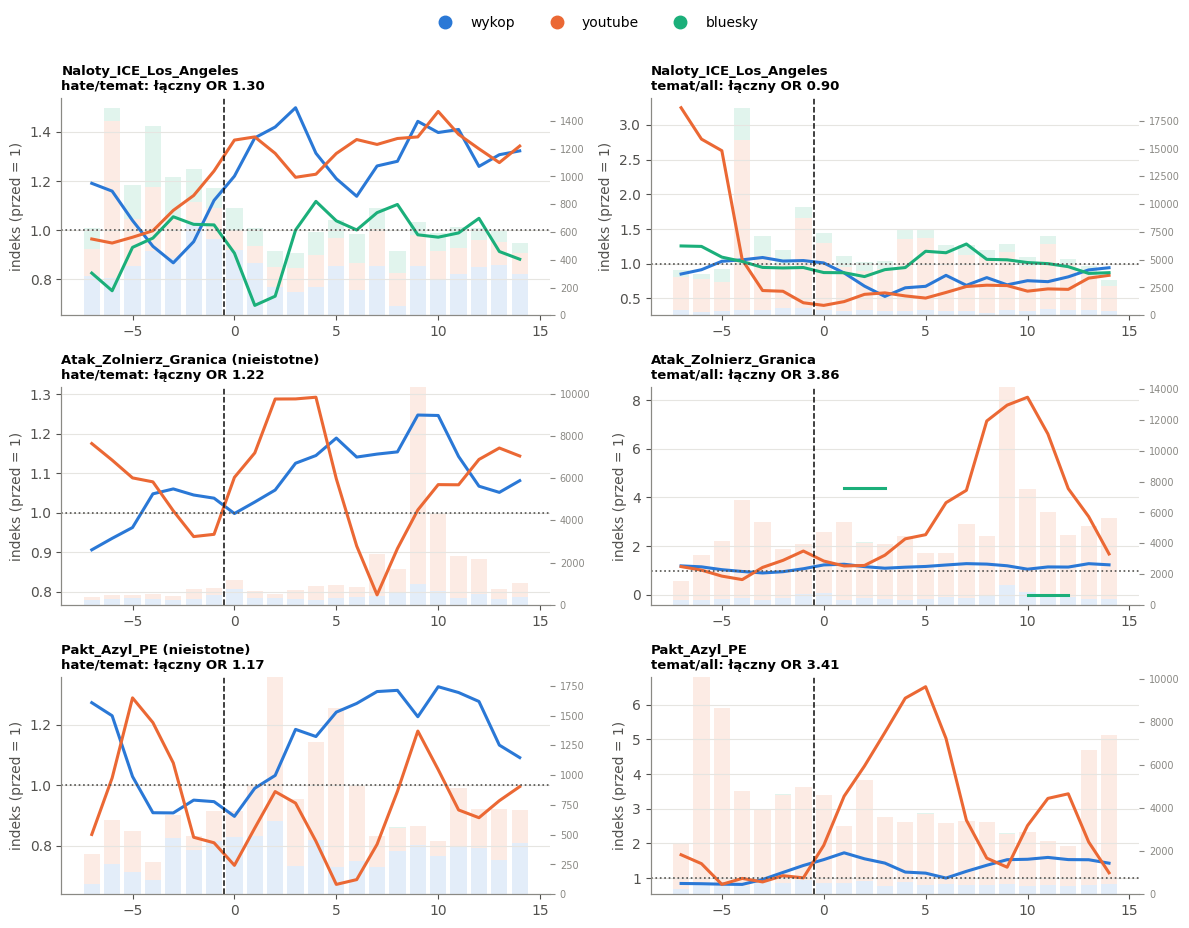

In [18]:
evp = ev_pool[(ev_pool["miara"] == MAIN) & (ev_pool["k"] >= 2)].assign(abs_mu=lambda x: x["mu"].abs())
top_ev = pd.concat([evp[evp["p (Holm)"] < ALPHA].sort_values("abs_mu", ascending=False).assign(nieistotne=False),
                    evp[evp["p (Holm)"] >= ALPHA].sort_values("abs_mu", ascending=False).assign(nieistotne=True)]).head(TOP_K)
display(fmt_p(top_ev.set_index("event")[["platformy", "OR", "OR lo", "OR hi", "p (Holm)", "nieistotne"]], 2))

fig, axes = plt.subplots(len(top_ev), len(METRICS), figsize=(6 * len(METRICS), 3.1 * len(top_ev)), squeeze=False)
for i, (_, r) in enumerate(top_ev.iterrows()):
    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        ax2 = ax.twinx()
        bottom = np.zeros(len(DAYS))
        for p in PL:
            cell = f"{p}:{r['event']}"
            if cell not in CELLS:
                continue
            share, base, den = daily_cell(cell, metric)
            idx = (share / base) if base > 0 else share * np.nan
            ax.plot(list(DAYS), idx.rolling(ROLL_DAYS, center=True, min_periods=1).mean(), color=PLATFORM_COLORS[p], lw=2.2)
            ax2.bar(list(DAYS), den.values, bottom=bottom, color=PLATFORM_COLORS[p], alpha=0.13, width=0.8)
            bottom += den.values
        ax2.grid(False)
        ax2.tick_params(axis="y", colors=MUTED, labelsize=7)
        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)
        ax.axhline(1, color=INK2, ls=":", lw=1.2)
        ax.axvline(POST_FROM_DAY - 0.5, color=INK, ls="--", lw=1.1)
        ax.set_ylabel("indeks (przed = 1)")
        em = ev_pool[(ev_pool["miara"] == metric) & (ev_pool["event"] == r["event"])].iloc[0]
        tag = " (nieistotne)" if (r["nieistotne"] and j == 0) else ""
        ax.set_title(f"{r['event']}{tag}\n{metric}: łączny OR {em['OR']:.2f}", fontsize=9.5)
platform_legend(fig, top=0.95)
plt.show()

## 3. Najczęstsze słowa w hejcie (wszystkie platformy razem)

- Materiał: komentarze `hate = 1` ze wszystkich platform (bez duplikatów z nakładających się okien Wykopu).
- Przetwarzanie: małe litery, bez linków i wzmianek, tokeny ≥ 3 litery, **lematyzacja `simplemma`**, bez stop-słów.
- **Częstość:** najczęstsze lematy i bigramy w hejcie.
- **Słowa wyróżniające:** log-odds z priorytetem Dirichleta (Monroe i in. 2008) – hejt vs komentarze w temacie migracji
  **bez** hejtu; `z` > 2 ≈ wyraźnie częstsze w hejcie.
- Panele per platforma pokazują, czy wynik nie pochodzi z jednej platformy.
- **Chmura słów:** jedna chmura z lematów hejtu ze **wszystkich platform razem** (rozmiar = liczba wystąpień).
  YouTube daje ok. 2/3 tokenów, więc to on najbardziej kształtuje chmurę.

In [19]:
STOPWORDS_PL = set("""
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
link user email phone mieć móc chcieć wiedzieć mówić czas rok raz ten taki który swój wszystek inny jakiś cały sam też
""".split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+|\[\w+\]")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")
_LEMMA = {}


def lemma(t):
    if t not in _LEMMA:
        _LEMMA[t] = simplemma.lemmatize(t, lang="pl").lower()
    return _LEMMA[t]


STOP = STOPWORDS_PL | {lemma(w) for w in STOPWORDS_PL}


def tokens(text):
    toks = [lemma(t) for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower()))]
    return [t for t in toks if t not in STOP and len(t) >= 3]


def count_terms(texts):
    uni, bi = Counter(), Counter()
    for txt in texts:
        t = tokens(txt)
        uni.update(t)
        bi.update(f"{a} {b}" for a, b in zip(t, t[1:]))
    return uni, bi


def log_odds(c1, c2, prior, min_count=10):
    """Ważony log-odds ratio z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n hejt", "n bez hejtu", "z"]).sort_values("z", ascending=False)


# bez duplikatów: ten sam komentarz Wykopu może należeć do dwóch nakładających się wydarzeń
uniq = df.drop_duplicates(["platform", "uid"])
hm = uniq[uniq["hate"]]
nh = uniq[uniq["temat"] & ~uniq["hate"]]
print("komentarze z hejtem:", hm.groupby("platform").size().reindex(PL).to_dict())
print("komentarze w temacie bez hejtu:", nh.groupby("platform").size().reindex(PL).to_dict())

terms = {}
for p in PL:
    terms[(p, "hejt")] = count_terms(hm.loc[hm["platform"] == p, "text"])
    terms[(p, "bez")] = count_terms(nh.loc[nh["platform"] == p, "text"])
uni_h = sum((terms[(p, "hejt")][0] for p in PL), Counter())
bi_h = sum((terms[(p, "hejt")][1] for p in PL), Counter())
uni_n = sum((terms[(p, "bez")][0] for p in PL), Counter())
bi_n = sum((terms[(p, "bez")][1] for p in PL), Counter())

komentarze z hejtem: {'wykop': 26236, 'youtube': 63298, 'bluesky': 3736}
komentarze w temacie bez hejtu: {'wykop': 52424, 'youtube': 82173, 'bluesky': 14968}


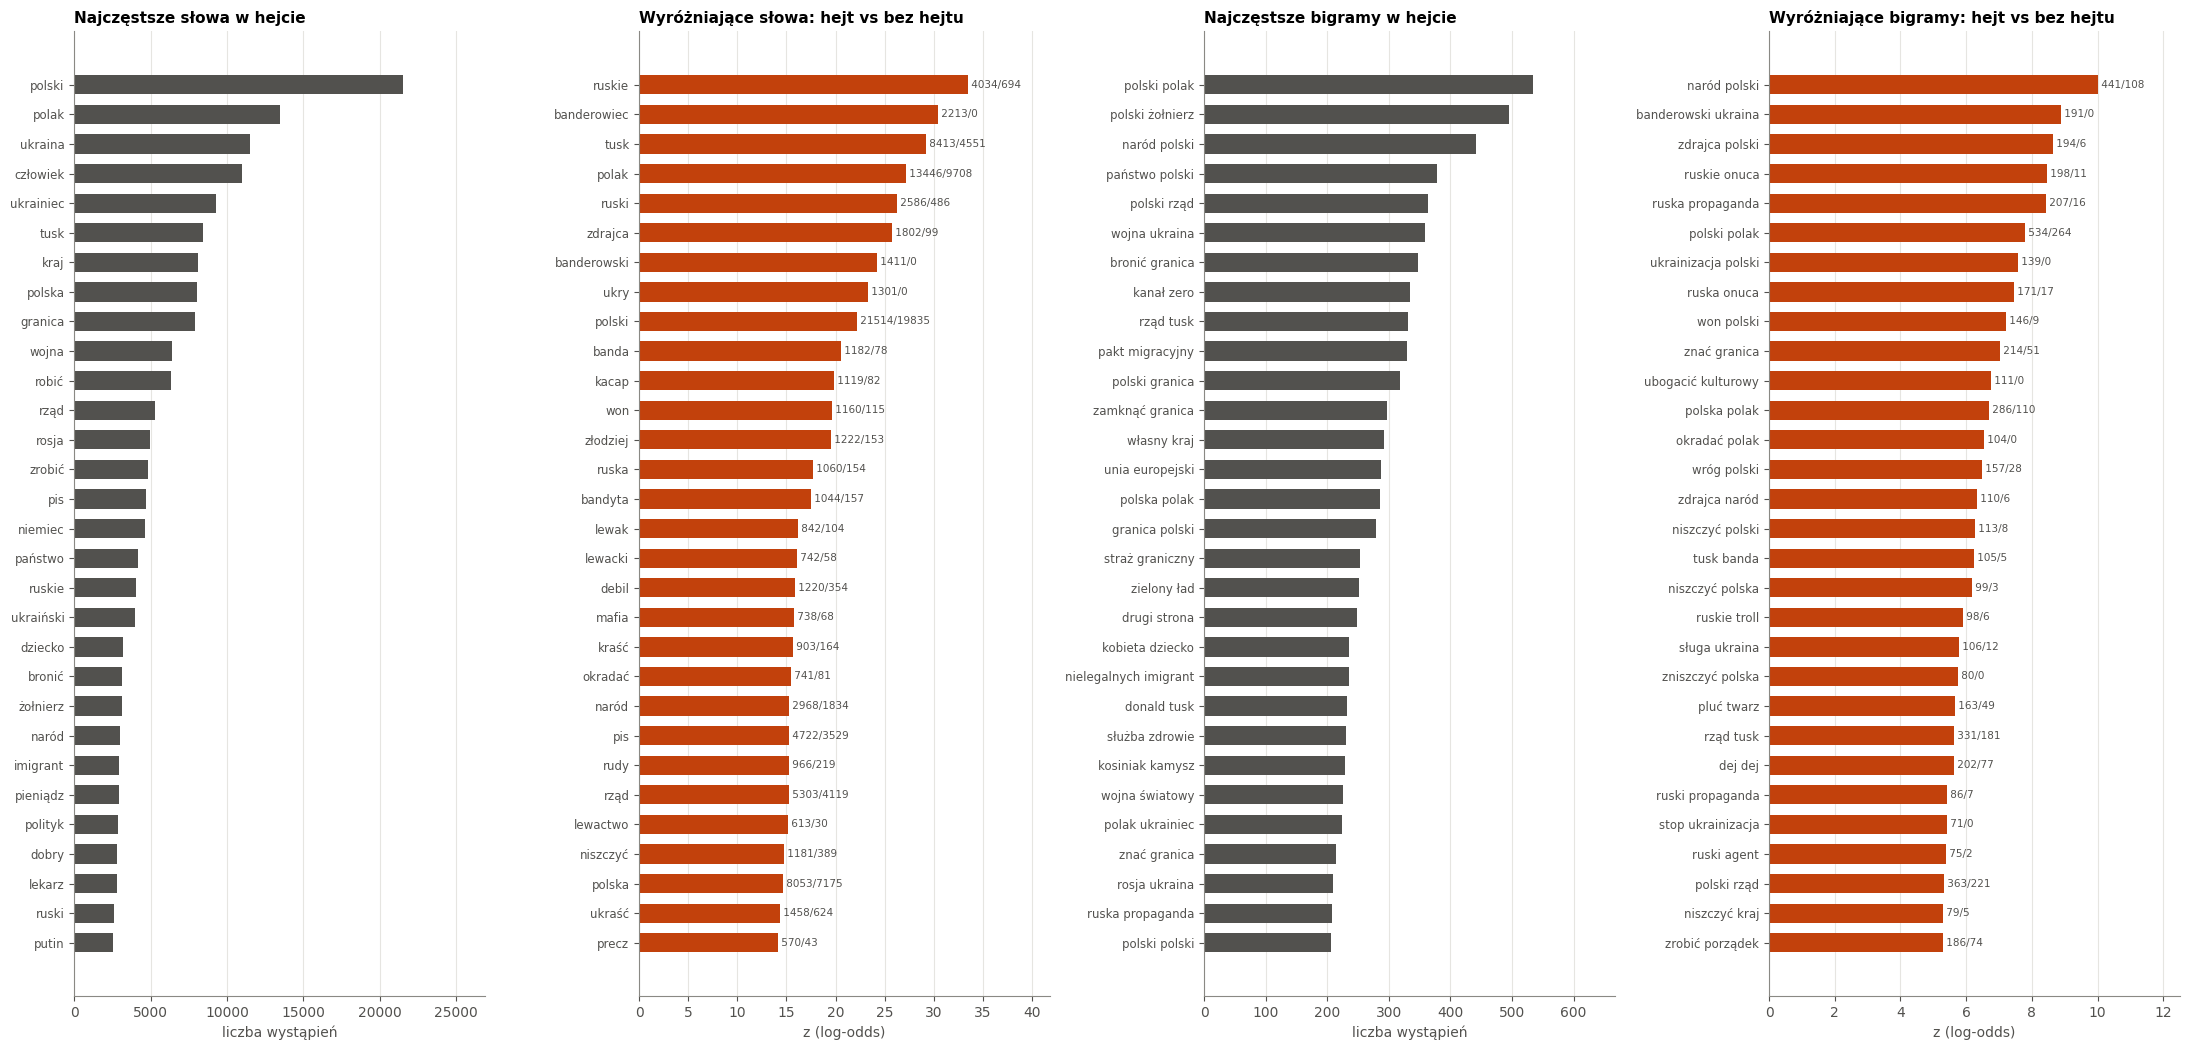

In [20]:
def barh(ax, labels, values, color, title, xlabel, notes=None):
    ax.barh(labels[::-1], values[::-1], color=color, height=0.65)
    if notes is not None:
        for yi, (v, n) in enumerate(zip(values[::-1], notes[::-1])):
            ax.text(v, yi, f" {n}", va="center", color=INK2, fontsize=7.5)
    ax.margins(x=0.25)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)


fig, axes = plt.subplots(1, 4, figsize=(22, 0.3 * TOP_N_WORDS + 1.6))
for ax, (c_h, c_n, kind) in zip([axes[:2], axes[2:]], [(uni_h, uni_n, "słowa"), (bi_h, bi_n, "bigramy")]):
    top = c_h.most_common(TOP_N_WORDS)
    barh(ax[0], [w for w, _ in top], [n for _, n in top], INK2, f"Najczęstsze {kind} w hejcie", "liczba wystąpień")
    lo_ = log_odds(c_h, c_n, c_h + c_n, min_count=10 if kind == "słowa" else 5).head(TOP_N_WORDS)
    barh(ax[1], lo_["słowo"].tolist(), lo_["z"].tolist(), "#c2410c", f"Wyróżniające {kind}: hejt vs bez hejtu",
         "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hejt"], lo_["n bez hejtu"])])
plt.tight_layout()
plt.show()

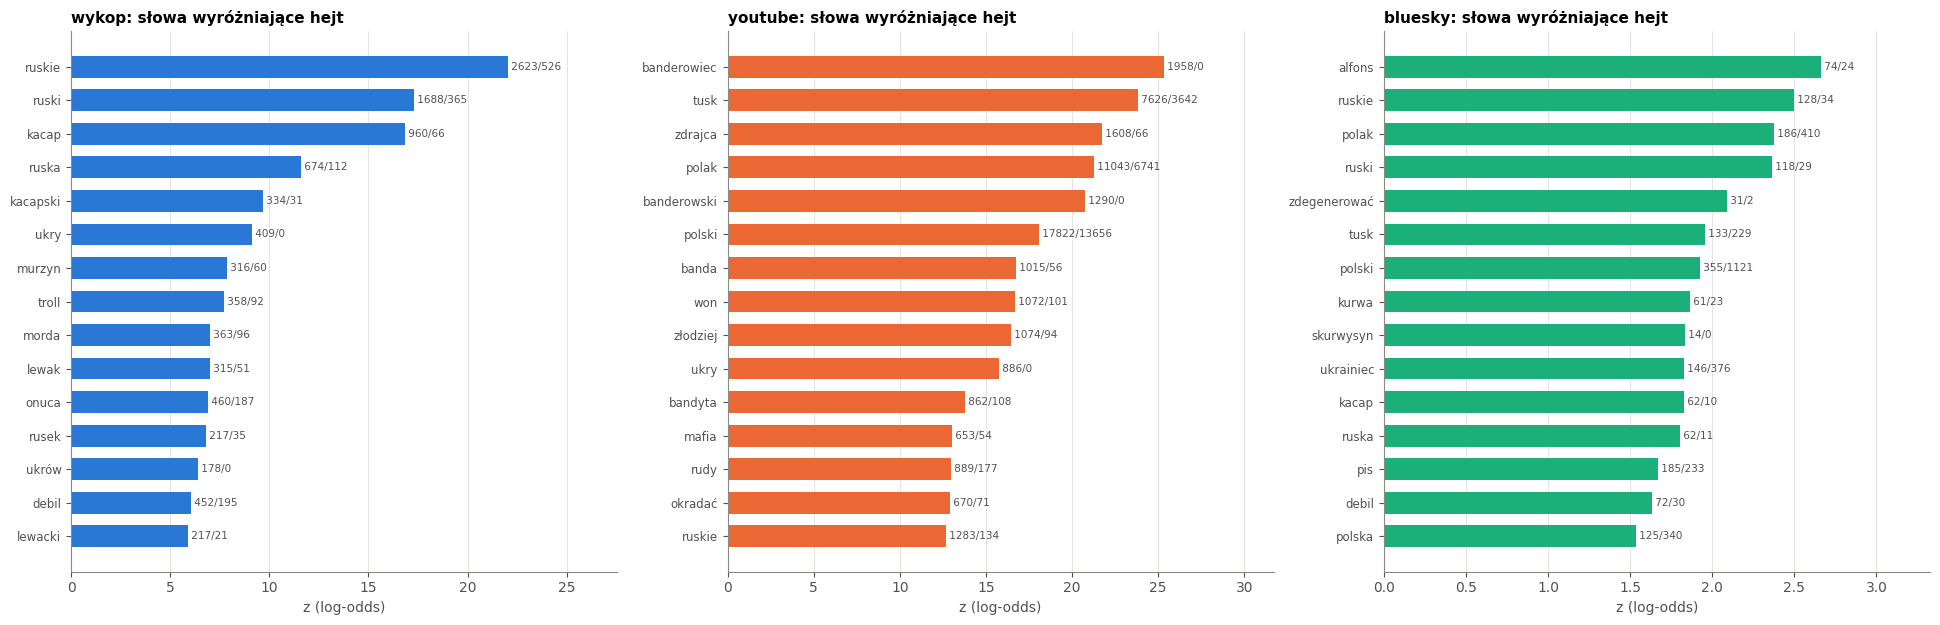

Udział platform w puli słów hejtu (tokeny): {'wykop': '27%', 'youtube': '70%', 'bluesky': '3%'}


In [21]:
TOP_PER_PL = 15
fig, axes = plt.subplots(1, len(PL), figsize=(6.5 * len(PL), 0.33 * TOP_PER_PL + 1.4))
for ax, p in zip(axes, PL):
    c_h, c_n = terms[(p, "hejt")][0], terms[(p, "bez")][0]
    lo_ = log_odds(c_h, c_n, uni_h + uni_n, min_count=5).head(TOP_PER_PL)
    barh(ax, lo_["słowo"].tolist(), lo_["z"].tolist(), PLATFORM_COLORS[p],
         f"{p}: słowa wyróżniające hejt", "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hejt"], lo_["n bez hejtu"])])
plt.tight_layout()
plt.show()

print("Udział platform w puli słów hejtu (tokeny):",
      {p: f"{100 * sum(terms[(p, 'hejt')][0].values()) / sum(uni_h.values()):.0f}%" for p in PL})

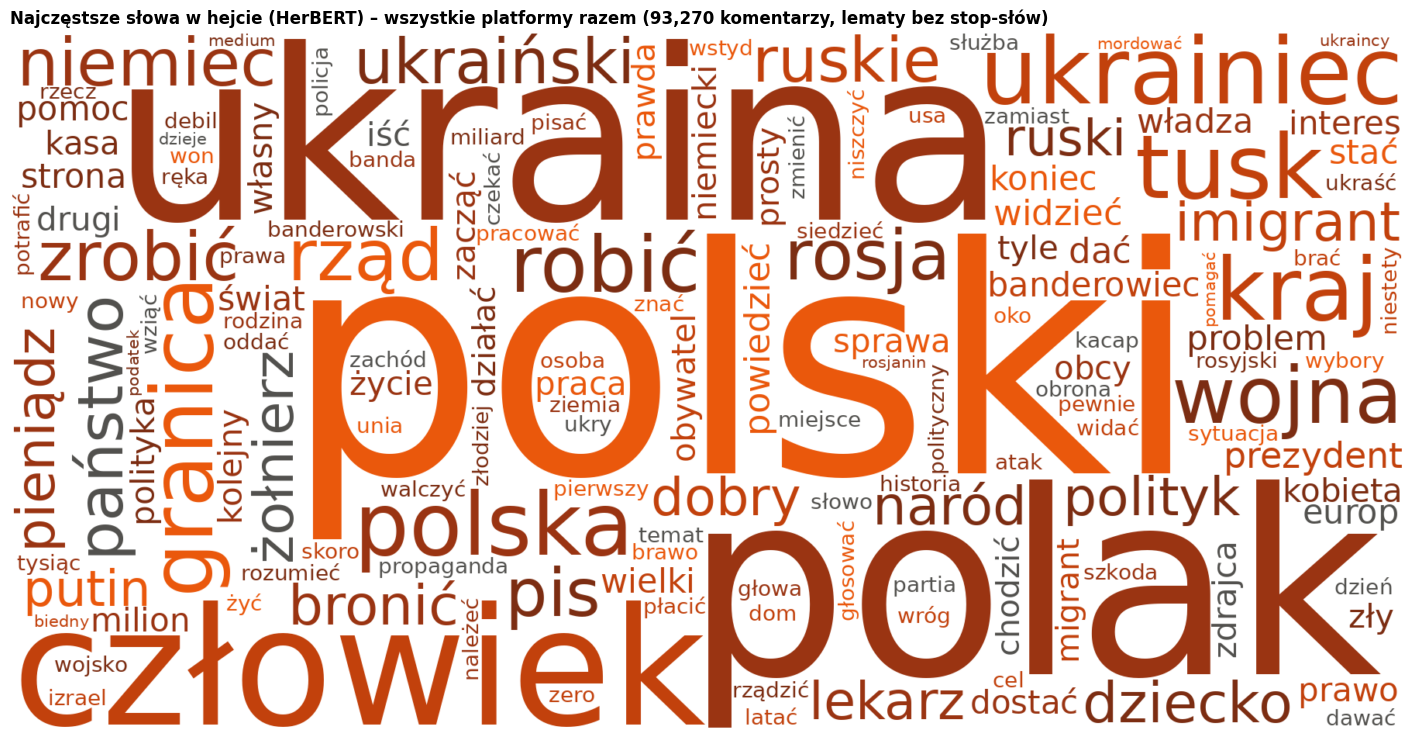

In [22]:
HATE_SHADES = ["#7c2d12", "#9a3412", "#c2410c", "#ea580c", "#52514e"]


def hate_color(word, font_size, position, orientation, random_state=None, **kw):
    return random_state.choice(HATE_SHADES)


wc = WordCloud(width=1800, height=900, background_color="white", max_words=150, prefer_horizontal=0.95,
               font_path=font_manager.findfont("DejaVu Sans"), color_func=hate_color, random_state=0,
               margin=4).generate_from_frequencies(dict(uni_h.most_common(400)))
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title(f"Najczęstsze słowa w hejcie (HerBERT) – wszystkie platformy razem "
             f"({len(hm):,} komentarzy, lematy bez stop-słów)")
plt.tight_layout()
plt.show()

## 4. Kogo obrażano i jakimi obelgami

**Grupy docelowe:** słowa kluczowe (`TARGET_GROUPS`, jak w poprzednich notebookach) w komentarzach `hate = 1`.
Komentarz może trafić do kilku grup; osobno pokazujemy, ile komentarzy nie wskazuje żadnej grupy.

**Kategorie obelg:** leksykon `src/lexicon/slurs.py` uruchomiony na tekstach `hate = 1` ze wszystkich platform
(dla YouTube nie ma etapu `slurs/`, więc liczymy tutaj). 15 kategorii zwiniętych do 6 grup. Leksykon łapie tylko część
hejtu – **pokrycie** (drukowane nad wykresem) mówi, jaki % komentarzy z hejtem zawiera **jakikolwiek** termin
z leksykonu. Kategorie na mapie to % **wszystkich** komentarzy z hejtem (nie tylko pokrytych), więc żadna nie może
przekroczyć pokrycia, a reszta to hejt bez słownikowych obelg (np. „niech wracają do siebie”, sarkazm, groźby
opisowe). Pokrycie różni się między platformami, więc porównując kategorie między platformami, lepiej patrzeć na ich
proporcje do pokrycia niż na same procenty.

Wartości = % komentarzy z hejtem (cały okres −7..+14). Wiersze per wydarzenie łączą platformy
(liczone na komentarzach, więc większa platforma waży więcej – `n` podane w etykiecie).

Pokrycie leksykonem (% komentarzy z hejtem, w których jest ≥ 1 termin z leksykonu): wykop 12%, youtube 17%, bluesky 5%


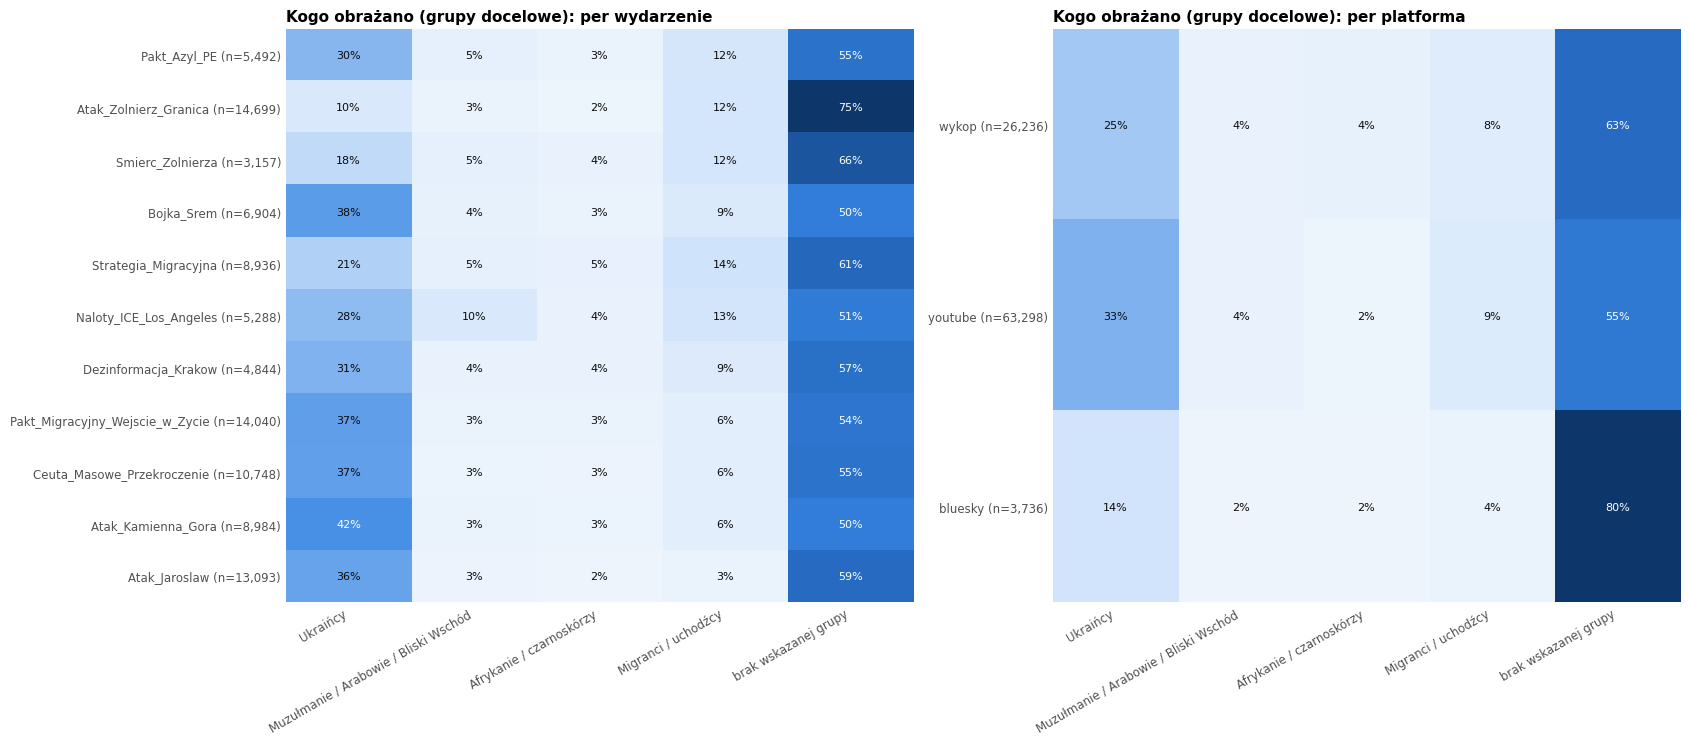

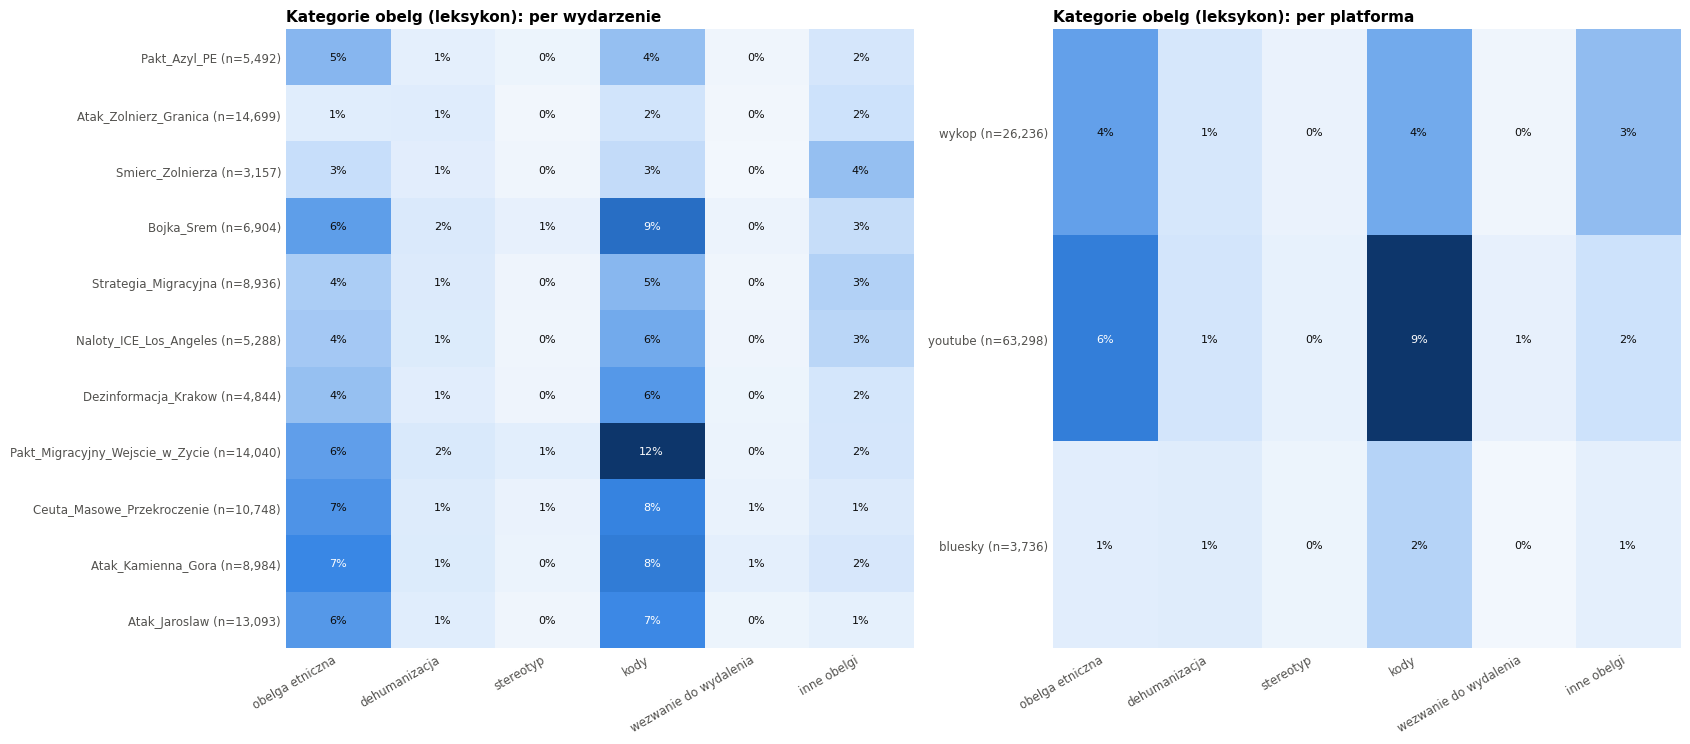

In [23]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
SLUR_GROUPS = {
    "obelga etniczna": ["obelga_etniczna", "obelga_etniczna_zlozenie", "obelga_historyczna"],
    "dehumanizacja": ["dehumanizacja"],
    "stereotyp": ["stereotyp", "stereotyp_swiadczenia", "stereotyp_seksistowski"],
    "kody": ["kod", "kod_historyczny", "kod_ironiczny", "kod_spiskowy", "kod_inwazji", "kod_prorosyjski"],
    "wezwanie do wydalenia": ["wezwanie_do_wydalenia"],
    "inne obelgi": ["obelga"],
}
CAT2GROUP = {c: g for g, cs in SLUR_GROUPS.items() for c in cs}

hm_ev = df[df["hate"]].copy()  # per wydarzenie (z ewentualnymi duplikatami między wydarzeniami)
low = hm_ev["text"].str.lower()
tg = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()}, index=hm_ev.index)
tg["brak wskazanej grupy"] = ~tg.any(axis=1)

found = hm_ev["text"].map(find_slurs)
sg = pd.DataFrame({g: found.map(lambda ts, g=g: any(CAT2GROUP.get(t.category) == g for t in ts)) for g in SLUR_GROUPS},
                  index=hm_ev.index)
unknown = {t.category for ts in found for t in ts} - set(CAT2GROUP)
if unknown:
    print("kategorie spoza mapowania:", unknown)
for t in [tg, sg]:
    t[["platform", "event", "uid"]] = hm_ev[["platform", "event", "uid"]]

coverage = (hm_ev.assign(pokryte=found.map(bool)).drop_duplicates(["platform", "uid"])
            .groupby("platform")["pokryte"].mean().reindex(PL))
print("Pokrycie leksykonem (% komentarzy z hejtem, w których jest ≥ 1 termin z leksykonu):",
      ", ".join(f"{p} {100 * v:.0f}%" for p, v in coverage.items()))


def share_tab(t, by, order):
    cols = [c for c in t.columns if c not in ("platform", "event", "uid")]
    if by == "platform":  # per platforma bez duplikatów z nakładających się okien
        t = t.drop_duplicates(["platform", "uid"])
    tab = 100 * t.groupby(by)[cols].mean().reindex(order)
    n = t.groupby(by).size().reindex(order)
    tab.index = [f"{i} (n={int(k):,})" for i, k in zip(tab.index, n)]
    return tab


def heat(ax, tab, title):
    vmax = np.nanmax(tab.values)
    ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(tab.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 0.55 * vmax else INK)
    ax.set_xticks(range(tab.shape[1]), [c.split(" (")[0] for c in tab.columns], rotation=30, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(tab)), tab.index, fontsize=8.5)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11)


for t, name in [(tg, "Kogo obrażano (grupy docelowe)"), (sg, "Kategorie obelg (leksykon)")]:
    fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * len(EVENT_ORDER) + 2.6), gridspec_kw={"width_ratios": [1, 1]})
    heat(axes[0], share_tab(t, "event", EVENT_ORDER), f"{name}: per wydarzenie")
    heat(axes[1], share_tab(t, "platform", PL), f"{name}: per platforma")
    plt.tight_layout()
    plt.show()

In [24]:
# najczęstsze terminy z leksykonu i zmiana grup docelowych przed → po
uniq_found = hm_ev.assign(found=found).drop_duplicates(["platform", "uid"])
term_tabs = {}
for p in PL:
    c = Counter(t.name for ts in uniq_found.loc[uniq_found["platform"] == p, "found"] for t in ts)
    n = (uniq_found["platform"] == p).sum()
    term_tabs[p] = [f"{w} ({100 * k / n:.1f}%)" for w, k in c.most_common(10)]
print("Najczęstsze terminy z leksykonu (% komentarzy z hejtem na platformie):")
display(pd.DataFrame({p: v + [""] * (10 - len(v)) for p, v in term_tabs.items()}, index=range(1, 11)))

tg_u = tg.assign(okres=hm_ev["okres"]).drop_duplicates(["platform", "uid"])
cols = list(TARGET_GROUPS) + ["brak wskazanej grupy"]
chg = (100 * tg_u.groupby(["platform", "okres"])[cols].mean()).unstack("okres")
print("Grupy docelowe przed → po (% komentarzy z hejtem):")
display(pd.concat({c: chg[c][["przed", "po"]].assign(**{"zmiana pp": chg[c]["po"] - chg[c]["przed"]}) for c in cols},
                  axis=1).reindex(PL).round(1))

Najczęstsze terminy z leksykonu (% komentarzy z hejtem na platformie):


,wykop,youtube,bluesky
1,ukry (2.6%),banderowiec (5.0%),bydlo_holota (0.8%)
2,murzyni (1.3%),ukry (2.4%),banderowiec (0.7%)
3,banderowiec (1.3%),upadlina (1.9%),upa (0.6%)
4,bydlo_holota (1.2%),bydlo_holota (1.2%),ukry (0.5%)
5,ciapaci (1.0%),upa (1.0%),bandera (0.3%)
6,ukro-* (0.8%),banderyzm (0.9%),banderyzm (0.3%)
7,ubogacacze (0.6%),nachodzcy (0.6%),ciapaci (0.2%)
8,nachodzcy (0.5%),bandera (0.6%),ukro-* (0.2%)
9,upa (0.5%),ukrainizacja (0.5%),murzyni (0.2%)
10,bandera (0.5%),ukro-* (0.5%),ss_galizien (0.2%)


Grupy docelowe przed → po (% komentarzy z hejtem):


Ukraińcy                 Muzułmanie / Arabowie / Bliski Wschód                Afrykanie / czarnoskórzy                Migranci / uchodźcy (ogólnie)                brak wskazanej grupy                
okres       przed    po zmiana pp                                 przed   po zmiana pp                    przed   po zmiana pp                         przed   po zmiana pp                przed    po zmiana pp
platform                                                                                                                                                                                                        
wykop        27.3  24.7      -2.6                                   3.8  4.1       0.3                      4.6  4.3      -0.3                           5.7  8.6       2.8                 62.5  62.9       0.4
youtube      38.6  31.7      -7.0                                   4.6  3.5      -1.0                      2.4  2.4      -0.0                           7.7  9.5       1.8                 50.5  56.2       5.7
bluesky      13.6  14.5       0.9                                   2.5  1.7      -0.7                      2.1  1.9      -0.2                           4.0  3.4      -0.6                 79.3  79.8       0.5

## 5. Koncentracja autorów hejtu

Tylko **Wykop i Bluesky** – na YouTube autorzy są puste już w surowych danych.
Na Bluesky pseudonimy są nadawane od nowa w każdym wydarzeniu, więc autor = (wydarzenie, pseudonim);
na Wykopie hash autora jest stały, więc autor jest liczony łącznie dla wszystkich wydarzeń.

- **udział top 1% / top 10%** autorów hejtu w całym hejcie, **Gini**, **krzywa Lorenza**,
- punkt odniesienia: ta sama koncentracja dla **wszystkich komentarzy** – czy hejt jest bardziej skupiony niż zwykłe pisanie?
- **% autorów, którzy napisali choć jeden hejt**,
- (Wykop) autorzy hejtujący przy **kilku wydarzeniach**.

autorów  komentarzy  top 1% autorów [% treści]  top 10% autorów [% treści]  Gini  śr. na autora  % autorów z ≥1 hejtem
platform co                                                                                                                                          
wykop    wszystkie komentarze    13855      101089                      18.07                       56.76  0.68           7.30                    NaN
         hejt (HerBERT)           7187       26236                      12.62                       46.28  0.56           3.65                  51.87
bluesky  wszystkie komentarze     6163       71133                      15.77                       56.56  0.70          11.54                    NaN
         hejt (HerBERT)           1471        3736                      13.52                       41.62  0.48           2.54                  23.87

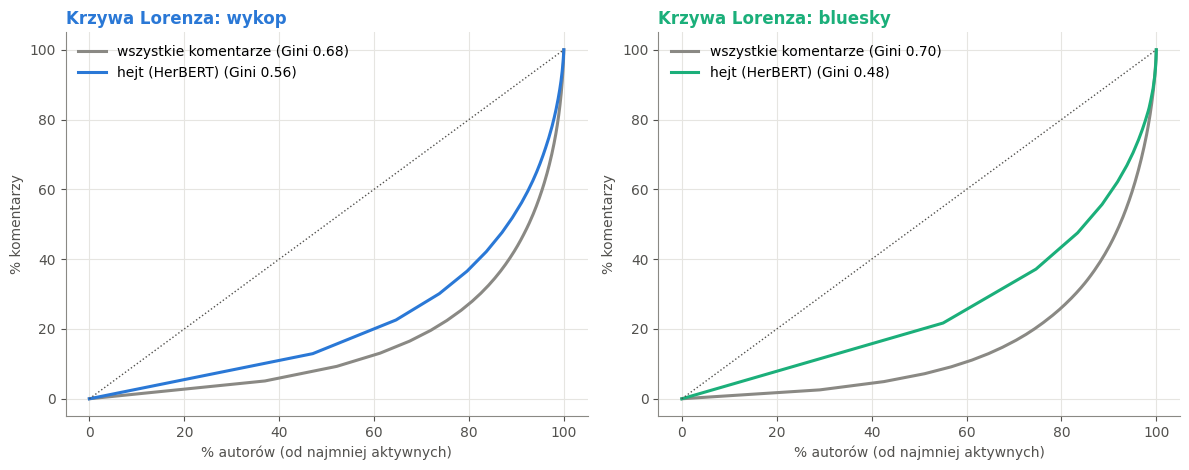

In [25]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n


def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    k = max(1, int(np.ceil(q * len(x))))
    return 100 * x[:k].sum() / x.sum()


def lorenz(x):
    x = np.sort(np.asarray(x, float))
    return np.r_[0, np.arange(1, len(x) + 1) / len(x)], np.r_[0, np.cumsum(x) / x.sum()]


AUTH_PL = [p for p in ["wykop", "bluesky"] if p in PL]
conc_rows, curves = [], {}
for p in AUTH_PL:
    d = uniq[(uniq["platform"] == p) & uniq["author_id"].notna()].copy()
    d["author"] = d["author_id"] if p == "wykop" else d["event"] + ":" + d["author_id"]
    per_author = d.groupby("author").agg(all=("comment_id", "size"), hate=("hate", "sum"))
    haters = per_author.loc[per_author["hate"] > 0, "hate"]
    curves[p] = {"wszystkie komentarze": lorenz(per_author["all"]), "hejt (HerBERT)": lorenz(haters)}
    for name, x in [("wszystkie komentarze", per_author["all"]), ("hejt (HerBERT)", haters)]:
        conc_rows.append({"platform": p, "co": name, "autorów": len(x), "komentarzy": int(x.sum()),
                          "top 1% autorów [% treści]": top_share(x, 0.01), "top 10% autorów [% treści]": top_share(x, 0.10),
                          "Gini": gini(x), "śr. na autora": x.mean()})
    conc_rows[-1]["% autorów z ≥1 hejtem"] = 100 * len(haters) / len(per_author)
conc = pd.DataFrame(conc_rows).set_index(["platform", "co"])
display(conc.round(2))

fig, axes = plt.subplots(1, len(AUTH_PL), figsize=(6 * len(AUTH_PL), 4.8), squeeze=False)
for ax, p in zip(axes[0], AUTH_PL):
    for (name, (x, y)), ls in zip(curves[p].items(), ["-", "-"]):
        c = MUTED if name == "wszystkie komentarze" else PLATFORM_COLORS[p]
        ax.plot(x * 100, y * 100, color=c, ls=ls, lw=2.2,
                label=f"{name} (Gini {conc.loc[(p, name), 'Gini']:.2f})")
    ax.plot([0, 100], [0, 100], color=INK2, ls=":", lw=1)
    ax.set_xlabel("% autorów (od najmniej aktywnych)")
    ax.set_ylabel("% komentarzy")
    ax.grid(axis="x", visible=True)
    ax.legend(loc="upper left")
    ax.set_title(f"Krzywa Lorenza: {p}", color=PLATFORM_COLORS[p])
plt.tight_layout()
plt.show()

In [26]:
if "wykop" in AUTH_PL:
    d = df[(df["platform"] == "wykop") & df["hate"] & df["author_id"].notna()]
    ev_per_author = d.groupby("author_id")["event"].nunique()
    hate_per_author = d.drop_duplicates("comment_id").groupby("author_id").size()
    rep = pd.DataFrame({"wydarzeń": ev_per_author, "hejtów": hate_per_author})
    tab = rep.groupby(rep["wydarzeń"].clip(upper=4)).agg(autorów=("hejtów", "size"), hejtów=("hejtów", "sum"))
    tab.index = [f"{i}" if i < 4 else "4+" for i in tab.index]
    tab["% autorów"] = 100 * tab["autorów"] / tab["autorów"].sum()
    tab["% hejtu"] = 100 * tab["hejtów"] / tab["hejtów"].sum()
    print("Wykop: przy ilu wydarzeniach autor pisał hejt (HerBERT)")
    display(tab.round(1))
    print("Uwaga: Bojka/Strategia i Ceuta/Kamienna Góra mają bliskie okna – ten sam okres aktywności może liczyć się do dwóch wydarzeń.")

Wykop: przy ilu wydarzeniach autor pisał hejt (HerBERT)


,autorów,hejtów,% autorów,% hejtu
1,3650,5000,50.8,19.1
2,1632,4187,22.7,16.0
3,811,3829,11.3,14.6
4+,1094,13220,15.2,50.4


Uwaga: Bojka/Strategia i Ceuta/Kamienna Góra mają bliskie okna – ten sam okres aktywności może liczyć się do dwóch wydarzeń.


**Jak czytać:** *Gini* (0 = każdy autor pisze tyle samo, 1 = wszystko pisze jedna osoba) i *udział top 1% / 10%*
mówią, czy treść tworzy wąska grupa. Krzywa Lorenza: im dalej od przekątnej, tym większa koncentracja.
Punkt odniesienia to wszystkie komentarze – jeśli hejt byłby dziełem kilku „trolli”, byłby bardziej skupiony niż
zwykłe pisanie.

**Wnioski:**
- **Hejt jest mniej skoncentrowany niż zwykła aktywność:** Wykop – Gini 0,56 dla hejtu vs 0,68 dla wszystkich komentarzy
  (top 10% autorów pisze 46% hejtu i 57% wszystkich komentarzy); Bluesky – 0,48 vs 0,70.
- **Hejt pisze szerokie grono:** na Wykopie 52% autorów napisało co najmniej jeden komentarz z hejtem w temacie migracji
  (średnio 3,7), na Bluesky 24% (2,5).
- **Na Wykopie jest stały rdzeń:** 15% autorów hejtowało przy 4+ wydarzeniach i napisało połowę hejtu (50%) – przy 11
  wydarzeniach (i bliskich oknach) powracający autorzy ważą więcej niż w analizie Oli na 7 wydarzeniach.

## 6. Czy hejt zbiera więcej polubień?

Porównujemy komentarze **w temacie migracji** (`temat = 1`): z hejtem vs bez hejtu, osobno na każdej
platformie (ten sam temat, więc różnica nie wynika z tego, że migracja ogólnie przyciąga więcej uwagi).

- mediana, średnia, % komentarzy z ≥ 1 polubieniem,
- **test Manna-Whitneya** (rangi; odporny na pojedyncze komentarze z tysiącami polubień) i prawdopodobieństwo przewagi
  P(hejt > bez hejtu),
- **model ujemny dwumianowy** `likes ~ hejt + C(wydarzenie)` z błędami klastrowanymi po wątku →
  **stosunek średnich** (ile razy więcej polubień ma średnio hejt w tym samym wydarzeniu).

Wykop: `likes` to głosy (plusy − minusy), mogą być ujemne – w testach rangowych zostają, w modelu przycinamy je do 0.

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3802: RuntimeWarning: overflow encountered in scalar power
  da1 = -(alpha**-2)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3706: RuntimeWarning: divide by zero encountered in scalar divide
  size = 1 / alpha * mu**Q
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3707: RuntimeWa

/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/sessions/rcw-01nsx5yb4djqzr5y7phg3hmf/.local/lib/python3.10/site-packag

,n hejt,n bez hejtu,mediana hejt,mediana bez,średnia hejt,średnia bez,% ≥1 hejt,% ≥1 bez,P(hejt > bez),p Mann-Whitney,stosunek średnich (NB),lo,hi,p NB,p NB (Holm)
platform,,,,,,,,,,,,,,,
wykop,26236,52424,1.0,1.0,14.073,10.962,59.819,55.373,0.528,1.47e-38,1.288,1.209,1.372,5.47e-15,1.09e-14
youtube,63298,82173,0.0,1.0,8.834,13.591,49.305,55.118,0.452,1.04e-242,0.648,NaN,NaN,,
bluesky,3736,14968,1.0,1.0,2.090,1.722,73.207,67.958,0.553,7.15e-25,1.218,1.137,1.305,1.95e-08,1.95e-08


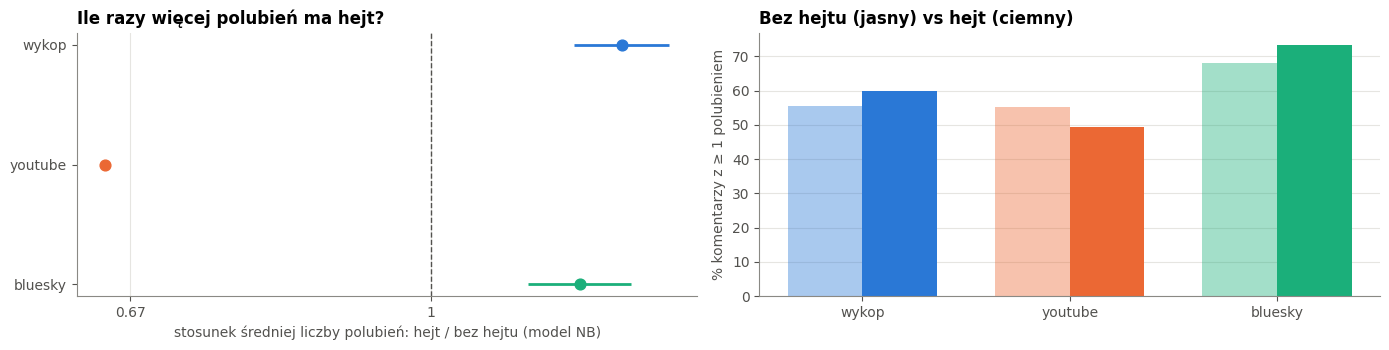

In [27]:
like_rows = []
for p in PL:
    d = uniq[(uniq["platform"] == p) & uniq["temat"]].dropna(subset=["likes"]).copy()
    h, n = d.loc[d["hate"], "likes"], d.loc[~d["hate"], "likes"]
    mw = stats.mannwhitneyu(h, n, alternative="two-sided")
    d["likes0"] = d["likes"].clip(lower=0).astype(int)
    d["hejt"] = d["hate"].astype(int)
    formula = "likes0 ~ hejt + C(event)" if d["event"].nunique() > 1 else "likes0 ~ hejt"
    try:
        m = smf.negativebinomial(formula, data=d).fit(
            disp=0, maxiter=300, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
        b, s, pv = m.params["hejt"], m.bse["hejt"], m.pvalues["hejt"]
    except Exception as ex:
        print(p, "model NB nie zbiegł:", str(ex)[:80])
        b, s, pv = np.nan, np.nan, np.nan
    like_rows.append({"platform": p, "n hejt": len(h), "n bez hejtu": len(n),
                      "mediana hejt": h.median(), "mediana bez": n.median(),
                      "średnia hejt": h.mean(), "średnia bez": n.mean(),
                      "% ≥1 hejt": 100 * (h >= 1).mean(), "% ≥1 bez": 100 * (n >= 1).mean(),
                      "P(hejt > bez)": mw.statistic / (len(h) * len(n)), "p Mann-Whitney": mw.pvalue,
                      "stosunek średnich (NB)": np.exp(b), "lo": np.exp(b - 1.96 * s), "hi": np.exp(b + 1.96 * s),
                      "p NB": pv})
likes = pd.DataFrame(like_rows).set_index("platform")
likes["p NB (Holm)"] = holm(likes["p NB"]).values
display(fmt_p(likes, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
ax = axes[0]
y = np.arange(len(PL))
for yi, p in zip(y, PL):
    r = likes.loc[p]
    ax.hlines(yi, r["lo"], r["hi"], color=PLATFORM_COLORS[p], lw=2)
    ax.scatter(r["stosunek średnich (NB)"], yi, s=60, color=PLATFORM_COLORS[p], zorder=3)
ax.axvline(1, color=INK2, ls="--", lw=1)
ax.set_xscale("log")
log_ticks(ax, "x")
ax.set_yticks(y, PL)
ax.invert_yaxis()
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("stosunek średniej liczby polubień: hejt / bez hejtu (model NB)")
ax.set_title("Ile razy więcej polubień ma hejt?")
ax = axes[1]
w = 0.36
ax.bar(y - w / 2, likes["% ≥1 bez"], width=w, color=[PLATFORM_COLORS[p] for p in PL], alpha=0.4, label="bez hejtu")
ax.bar(y + w / 2, likes["% ≥1 hejt"], width=w, color=[PLATFORM_COLORS[p] for p in PL], label="hejt")
ax.set_xticks(y, PL)
ax.set_ylabel("% komentarzy z ≥ 1 polubieniem")
ax.set_title("Bez hejtu (jasny) vs hejt (ciemny)")
plt.tight_layout()
plt.show()

**Jak czytać:** *P(hejt > bez)* = szansa, że losowy komentarz z hejtem ma więcej polubień niż losowy komentarz o
migracji bez hejtu (0,5 = brak różnicy). *Stosunek średnich (NB)* = ile razy więcej polubień ma średnio hejt w tym
samym wydarzeniu (1 = tyle samo).

**Wnioski:**
- **Wykop i Bluesky: hejt zbiera więcej polubień** niż komentarze w temacie bez hejtu – Wykop ×1,29 [1,21; 1,37],
  Bluesky ×1,22 [1,14; 1,31], oba istotne po Holmie; efekt mały (P(hejt > bez) = 0,53 i 0,55, mediany równe).
- **YouTube: odwrotnie** – hejt ma średnio mniej polubień (×0,65; P(hejt > bez) = 0,45, Mann–Whitney p < 0,001);
  przedział ufności z modelu NB się nie policzył (problem zbieżności), więc opieramy się na Mann–Whitney.
- Ten sam obraz co u Oli na LLM: brak uniwersalnego „nagradzania hejtu”, wynik zależy od platformy.

## 7. Typ wydarzenia a wielkość zmiany (H2)

**Typy:** kryminalne (przemoc / incydent; 3 wydarzenia), polityczne (2), dezinformacja (1), kryzys graniczny (1).
**Zasięg:** krajowe (5) vs zagraniczne (2).

- **Test główny:** meta-regresja log-OR (wszystkie komórki) z moderatorem `typ` i kontrolą platformy;
  test omnibus moderatora (F, poprawka Knappa–Hartunga).
- **Kontrast:** kryminalne vs reszta; **zasięg:** krajowe vs zagraniczne (ta sama meta-regresja).
- **Test permutacyjny:** przetasowujemy etykiety typu między **wydarzeniami** (wszystkie możliwe przypisania) i
  liczymy, jak często statystyka jest co najmniej tak duża jak prawdziwa – dokładne p bez założenia normalności.
- **Kierunek:** ile komórek każdego typu ma istotny wzrost / spadek.
- **Per platforma:** Wykop i YouTube – kontrast kryminalne vs reszta; Bluesky (po jednym wydarzeniu na typ) – tylko opis.

⚠️ Wynik eksploracyjny: 7 wydarzeń, a dezinformacja i kryzys graniczny mają po jednym – „efekt typu” jest tam
nieodróżnialny od efektu konkretnego wydarzenia.

In [28]:
def meta_reg(y, se, X):
    """Meta-regresja efektów mieszanych: τ² metodą momentów (DerSimonian–Laird), błędy Knappa–Hartunga."""
    y, v, X = np.asarray(y, float), np.asarray(se, float) ** 2, np.asarray(X, float)
    k, p = X.shape
    W = np.diag(1 / v)
    XtWX_inv = np.linalg.pinv(X.T @ W @ X)
    P = W - W @ X @ XtWX_inv @ X.T @ W
    q_e = float(y @ P @ y)
    tau2 = max(0.0, (q_e - (k - p)) / np.trace(P))
    Ws = np.diag(1 / (v + tau2))
    cov = np.linalg.pinv(X.T @ Ws @ X)
    b = cov @ X.T @ Ws @ y
    s2 = max(1.0, float((y - X @ b) @ Ws @ (y - X @ b)) / (k - p))
    return b, cov * s2, tau2, k - p


def moderator_test(e, mod_cols, control_platform=True):
    """Test omnibus (F) dla kolumn moderatora; zwraca (F, p, współczynniki moderatora, df)."""
    X = pd.DataFrame({"const": 1.0}, index=e.index)
    for c in mod_cols:
        X[c] = e[c].astype(float)
    if control_platform:
        for p in PL[1:]:
            X[f"pl_{p}"] = (e["platform"] == p).astype(float)
    X = X.loc[:, X.std().fillna(0).gt(0) | (X.columns == "const")]
    keep = [c for c in mod_cols if c in X.columns]
    if not keep:
        return np.nan, np.nan, {}, 0
    b, cov, tau2, dfr = meta_reg(e["log OR"], e["se"], X.values)
    idx = [list(X.columns).index(c) for c in keep]
    bm, cm = b[idx], cov[np.ix_(idx, idx)]
    F = float(bm @ np.linalg.pinv(cm) @ bm) / len(idx)
    return F, stats.f.sf(F, len(idx), dfr), dict(zip(keep, bm)), dfr


def type_dummies(e, typ_of_event):
    t = e["event"].map(typ_of_event)
    return e.assign(**{f"typ_{x}": (t == x).astype(float) for x in TYPE_ORDER[1:]},
                    kryminalne=(t == "kryminalne").astype(float),
                    zagraniczne=e["event"].map(lambda ev: EVENT_META[ev][1] == "zagraniczne").astype(float))


TYPE_COLS = [f"typ_{x}" for x in TYPE_ORDER[1:]]
true_typ = {ev: EVENT_META[ev][0] for ev in EVENT_ORDER}


def perm_test(e, kind):
    """Wszystkie przypisania etykiet typu do wydarzeń o tych samych licznościach; statystyka = F moderatora."""
    events = list(dict.fromkeys(e["event"]))
    labels = [true_typ[ev] for ev in events]
    obs = moderator_test(type_dummies(e, true_typ), TYPE_COLS if kind == "typ" else ["kryminalne"])[0]
    from itertools import permutations
    stats_ = []
    for perm in set(permutations(labels)):
        tp = dict(zip(events, perm))
        F = moderator_test(type_dummies(e, tp), TYPE_COLS if kind == "typ" else ["kryminalne"])[0]
        if not np.isnan(F):
            stats_.append(F)
    stats_ = np.array(stats_)
    return obs, np.mean(stats_ >= obs - 1e-12), stats_


h2_rows, perm_dist = [], {}
for metric in METRICS:
    e = type_dummies(E(metric).dropna(subset=["log OR"]), true_typ)
    F, p, coef, dfr = moderator_test(e, TYPE_COLS)
    Fk, pk, ck, _ = moderator_test(e, ["kryminalne"])
    Fz, pz, cz, _ = moderator_test(e, ["zagraniczne"])
    obs, pperm, dist = perm_test(e, "typ")
    obs_k, pperm_k, dist_k = perm_test(e, "kryminalne")
    perm_dist[metric] = (obs, dist, obs_k, dist_k)
    h2_rows.append({"miara": metric, "komórek": len(e), "F typ": F, "p typ (meta-regresja)": p,
                    "p typ (permutacyjny)": pperm, "przypisań typ": len(dist),
                    "OR kryminalne vs reszta": np.exp(ck.get("kryminalne", np.nan)), "p kryminalne": pk,
                    "p kryminalne (permutacyjny)": pperm_k, "przypisań kontrast": len(dist_k),
                    "OR zagraniczne vs krajowe": np.exp(cz.get("zagraniczne", np.nan)), "p zasięg": pz,
                    **{f"OR {t} vs kryminalne": np.exp(coef.get(f"typ_{t}", np.nan)) for t in TYPE_ORDER[1:]}})
h2 = pd.DataFrame(h2_rows).set_index("miara")
display(fmt_p(h2, 3))

,komórek,F typ,p typ (meta-regresja),p typ (permutacyjny),przypisań typ,OR kryminalne vs reszta,p kryminalne,p kryminalne (permutacyjny),przypisań kontrast,OR zagraniczne vs krajowe,p zasięg,OR polityczne vs kryminalne,OR dezinformacja vs kryminalne,OR kryzys graniczny vs kryminalne
miara,,,,,,,,,,,,,,
hate/temat,27,2.881,0.0601,0.127,13860,0.900,0.204,0.299,13860,1.085,0.329,1.202,1.105,0.901
temat/all,27,0.634,0.602,0.719,13860,1.138,0.615,0.673,13860,0.926,0.765,1.001,0.843,0.581


In [29]:
dir_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])
    for t in TYPE_ORDER:
        g = e[e["typ"] == t]
        m = meta_random(g["log OR"], g["se"])
        dir_rows.append({"miara": metric, "typ": t, "wydarzeń": g["event"].nunique(), "komórek": len(g),
                         "wzrost": int((g["log OR"] > 0).sum()), "spadek": int((g["log OR"] < 0).sum()),
                         "istotnie ↑": int((g["kierunek"] == "↑").sum()), "istotnie ↓": int((g["kierunek"] == "↓").sum()),
                         **or_row(m)})
dirs = pd.DataFrame(dir_rows).set_index(["miara", "typ"])
print("Kierunek i siła zmian per typ (OR = meta-analiza efektów losowych komórek danego typu):")
display(fmt_p(dirs, 2))

pp_rows = []
for metric in METRICS:
    for p in PL:
        e = type_dummies(E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"]), true_typ)
        row = {"miara": metric, "platform": p, "wydarzeń": len(e)}
        if p != "bluesky" and e["kryminalne"].nunique() > 1:
            Fk, pk, ck, _ = moderator_test(e, ["kryminalne"], control_platform=False)
            Fz, pz, cz, _ = moderator_test(e, ["zagraniczne"], control_platform=False)
            row.update({"OR kryminalne vs reszta": np.exp(ck.get("kryminalne", np.nan)), "p kryminalne": pk,
                        "OR zagraniczne vs krajowe": np.exp(cz.get("zagraniczne", np.nan)), "p zasięg": pz})
        pp_rows.append(row)
print("Per platforma (Bluesky: tylko opis – każdy typ ma jedno wydarzenie):")
display(fmt_p(pd.DataFrame(pp_rows).set_index(["miara", "platform"]), 3))

Kierunek i siła zmian per typ (OR = meta-analiza efektów losowych komórek danego typu):


wydarzeń  komórek  wzrost  spadek  istotnie ↑  istotnie ↓    OR  OR lo  OR hi       p
miara      typ                                                                                                    
hate/temat kryminalne               5       11       4       7           0           0  0.96   0.88   1.04   0.304
           polityczne               4       10       6       4           1           0  1.14   0.97   1.34  0.0916
           dezinformacja            1        3       1       2           0           0  1.02   0.55   1.91   0.908
           kryzys graniczny         1        3       1       2           0           1  0.83   0.46   1.52    0.32
temat/all  kryminalne               5       11       5       6           1           0  1.10   0.68   1.79    0.67
           polityczne               4       10       5       5           2           0  1.09   0.68   1.75   0.684
           dezinformacja            1        3       1       2           0           0  0.88   0.48   1.65   0.485
           kryzys graniczny         1        3       0       3           0           0  0.64   0.36   1.15  0.0824

Per platforma (Bluesky: tylko opis – każdy typ ma jedno wydarzenie):


wydarzeń  OR kryminalne vs reszta p kryminalne  OR zagraniczne vs krajowe p zasięg
miara      platform                                                                                    
hate/temat wykop           11                    0.846       0.0839                      1.158    0.155
           youtube         10                    0.961        0.809                      0.993    0.966
           bluesky          6                      NaN                                     NaN         
temat/all  wykop           11                    1.059        0.898                      0.823    0.675
           youtube         10                    1.615         0.41                      0.837    0.768
           bluesky          6                      NaN                                     NaN

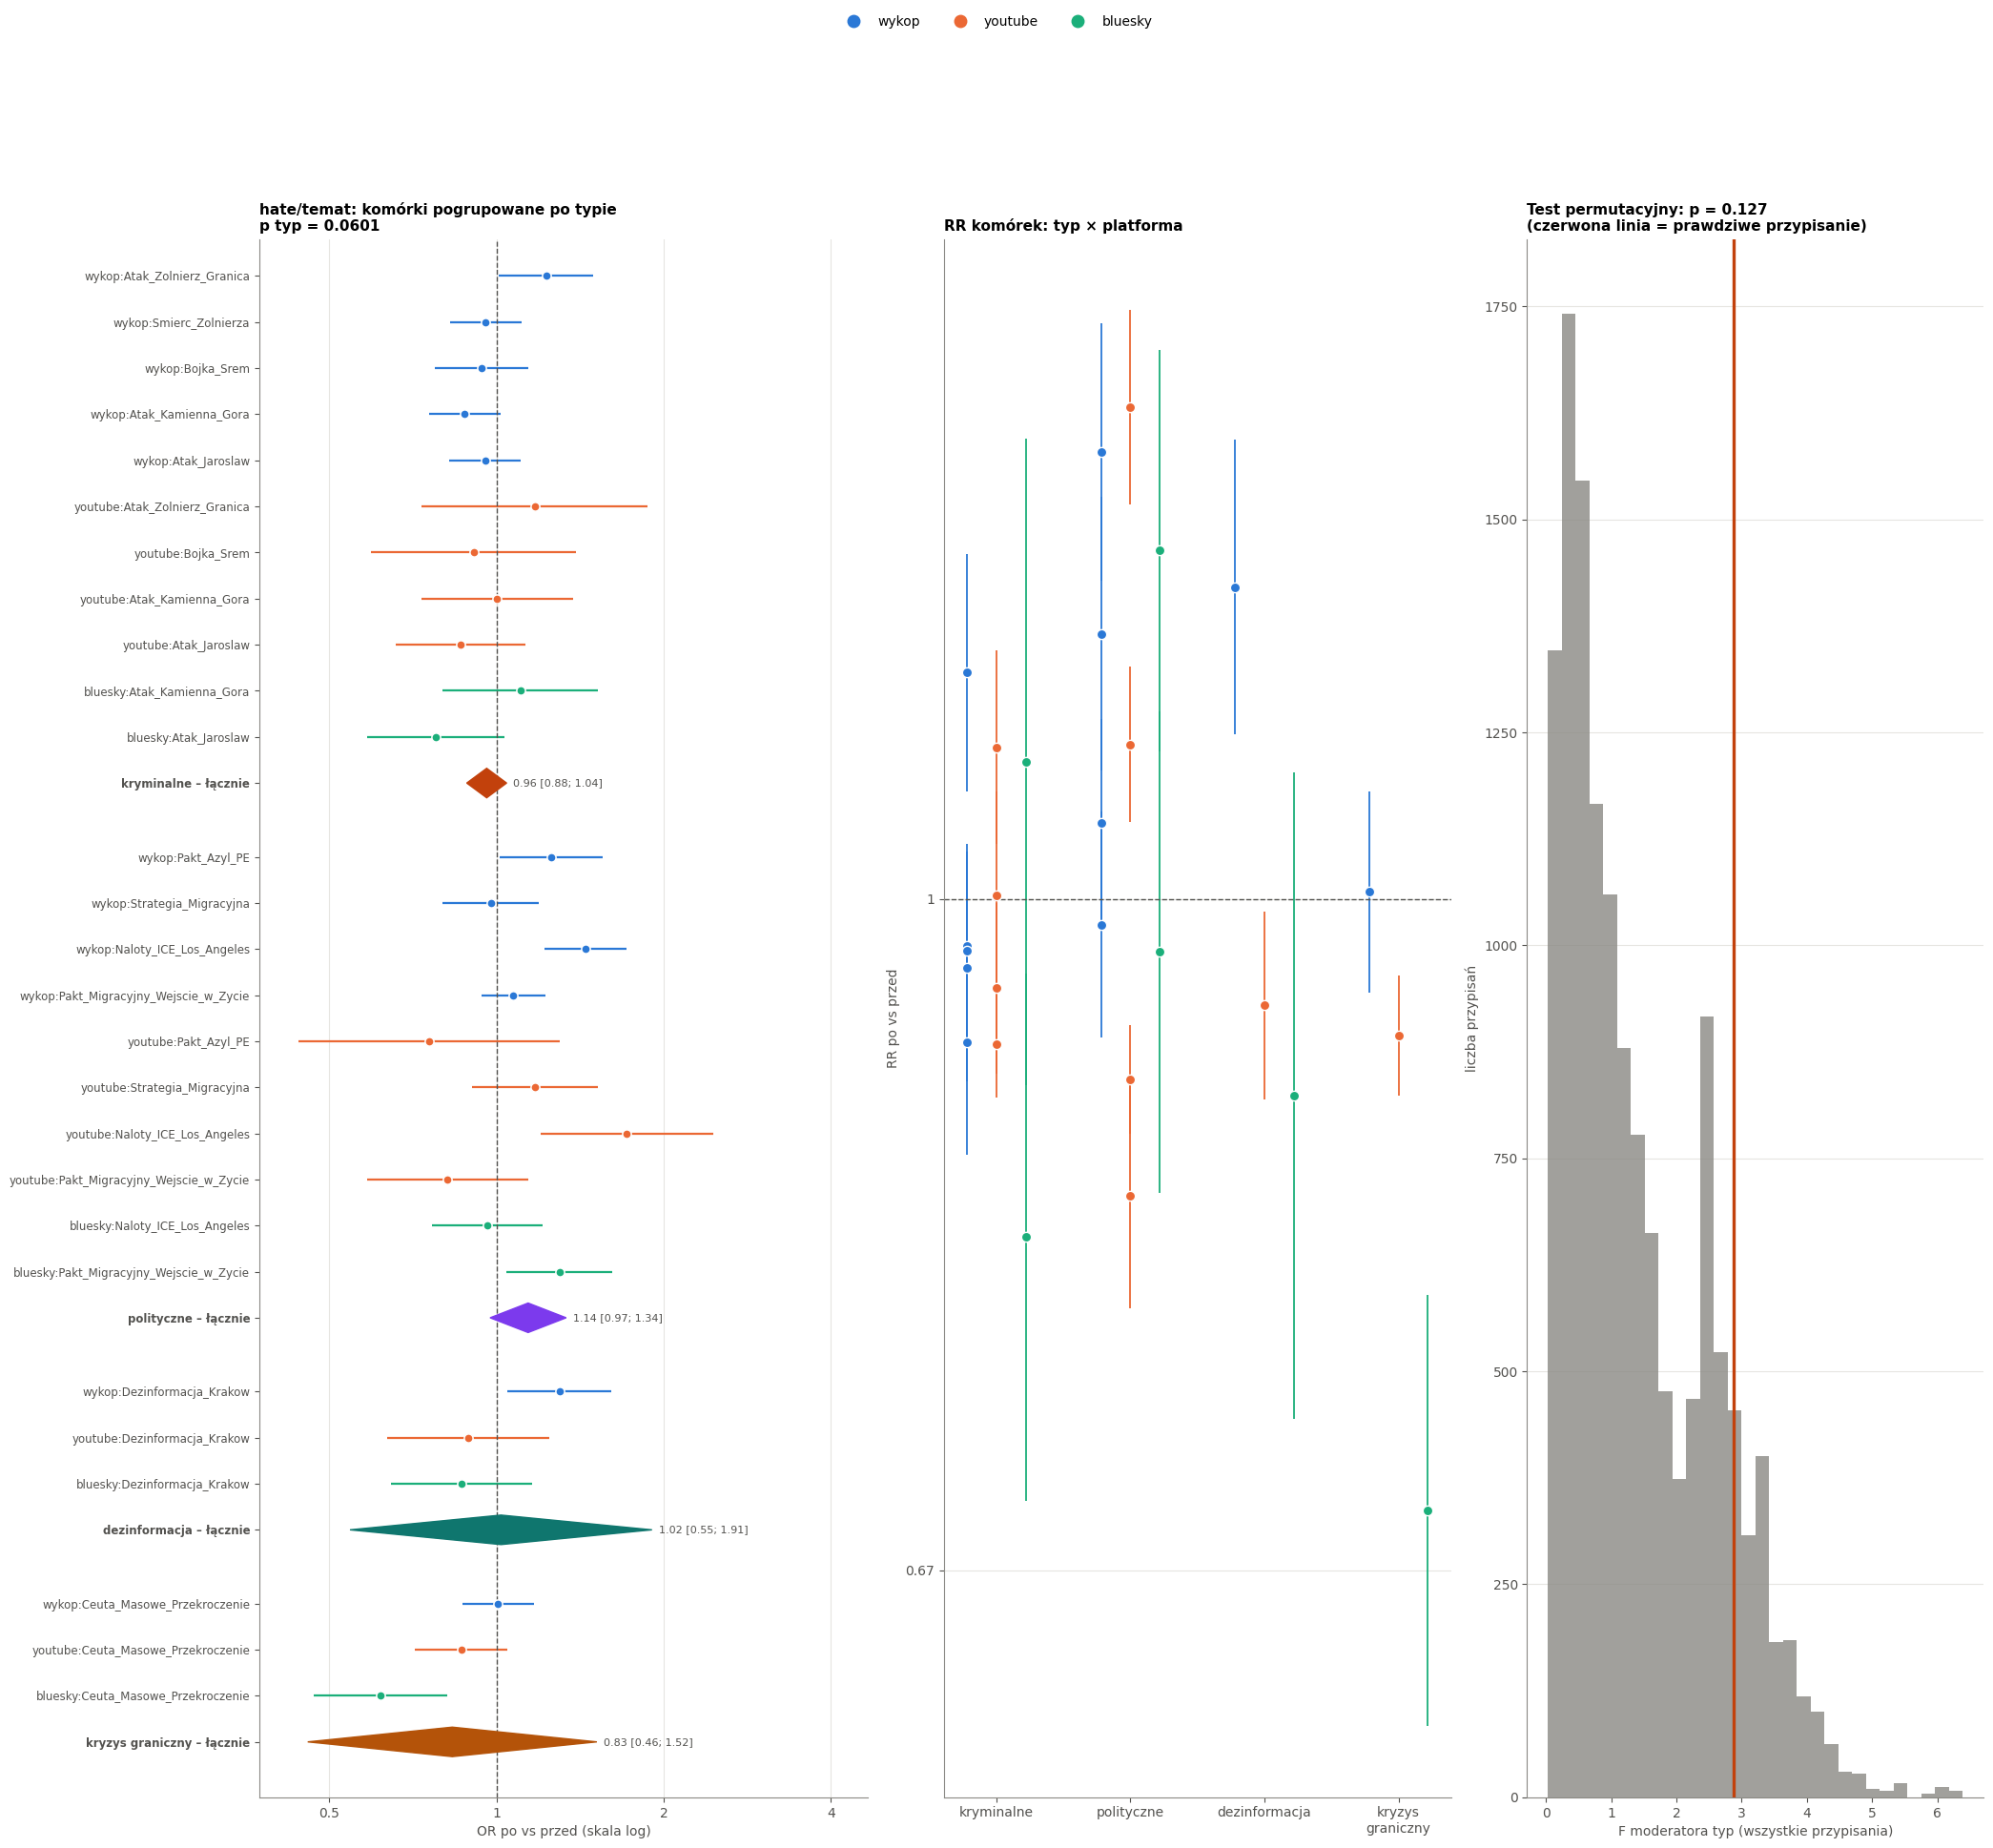

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(21, 0.5 * len(CELLS) + 3.4), gridspec_kw={"width_ratios": [1.2, 1, 0.9]})
groups = []
for t in TYPE_ORDER:
    g = E(MAIN)[E(MAIN)["typ"] == t].dropna(subset=["log OR"])
    m = meta_random(g["log OR"], g["se"])
    groups.append({"label": f"{t} – łącznie", "items": items_from(g.assign(lab=g["cell"]), "lab",
                                                                   lambda r_: PLATFORM_COLORS[r_["platform"]]),
                   "diamond": dia(m, TYPE_COLORS[t])})
forest(axes[0], groups, title=f"{MAIN}: komórki pogrupowane po typie\np typ = {h2.loc[MAIN, 'p typ (meta-regresja)']:.3g}")

ax = axes[1]
offs = np.linspace(-0.22, 0.22, len(PL))
for off, p in zip(offs, PL):
    e = E(MAIN)[E(MAIN)["platform"] == p].dropna(subset=["RR"])
    xx = e["typ"].map({t: i for i, t in enumerate(TYPE_ORDER)}) + off
    ax.vlines(xx, e["RR lo"], e["RR hi"], color=PLATFORM_COLORS[p], lw=1.3)
    ax.scatter(xx, e["RR"], s=55, color=PLATFORM_COLORS[p], edgecolor="white", zorder=3)
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" ", "\n") for t in TYPE_ORDER])
ax.set_ylabel("RR po vs przed")
ax.set_title("RR komórek: typ × platforma", fontsize=11)

ax = axes[2]
obs, dist, obs_k, dist_k = perm_dist[MAIN]
ax.hist(dist, bins=30, color=MUTED, alpha=0.8)
ax.axvline(obs, color="#c2410c", lw=2.4)
ax.set_xlabel("F moderatora typ (wszystkie przypisania)")
ax.set_ylabel("liczba przypisań")
ax.set_title(f"Test permutacyjny: p = {h2.loc[MAIN, 'p typ (permutacyjny)']:.3g}\n"
             f"(czerwona linia = prawdziwe przypisanie)", fontsize=11)
platform_legend(fig, top=0.9)
plt.show()

**Jak czytać:** meta-regresja sprawdza, czy log-OR komórek różni się w zależności od typu wydarzenia (przy kontroli
platformy). Test permutacyjny przestawia etykiety typu między wydarzeniami – p mówi, jak często losowe przypisanie
typów daje równie duże różnice. Lewy wykres: komórki pogrupowane po typie, romb = łączny OR typu.

**Wnioski:**
- **H2 niepotwierdzona:** typ wydarzenia nie wyjaśnia istotnie zmiany hejtu – meta-regresja p = 0,06 (permutacyjny 0,13);
  kryminalne vs reszta OR 0,90 (p = 0,20); zagraniczne vs krajowe OR 1,09 (p = 0,33). `temat/all`: p = 0,60.
- **Opisowo:** wydarzenia **polityczne** mają największy łączny wzrost (OR 1,14, p = 0,09; jedyna istotna komórka ↑ to naloty
  ICE na Wykopie), **kryzys graniczny** (Ceuta) – spadek (OR 0,83), kryminalne i dezinformacja – około zera.
- Przy 11 wydarzeniach (dezinformacja i kryzys graniczny po jednym) to wynik eksploracyjny.

---
---

## 8. Analizy dodatkowe (poza analizą Oli)

Wszystko powyżej to analiza Oli 1:1 na HerBERT-cie. Tu dokładamy:

- **testy z README** dla H1, H2 i H4 (na efektach komórek z sekcji 1a, które mają ≥ 30 komentarzy przed i po): Wilcoxon + rank-biserial r, Kruskal–Wallis → Dunn + Holm,
- **H3 – trwałość efektu** (u Oli nie było): czy zmiana jest największa w dniach 0–3 i potem słabnie.
  Okna 0–3, 4–7, 8–14 dni porównujemy z baseline −7..−1: Friedman (te same komórki w 3 oknach), potem Wilcoxon każde okno
  vs baseline z korektą Holma,
- tabelę werdyktów wszystkich hipotez.

In [31]:
from scipy.stats import friedmanchisquare, kruskal, wilcoxon

H3_WINDOWS = {"dni 0–3": (0, 3), "dni 4–7": (4, 7), "dni 8–14": (8, 14)}
BASELINE = (-7, -1)


def rank_biserial(x, y):
    d = np.asarray(y, float) - np.asarray(x, float)
    d = d[d != 0]
    if len(d) == 0:
        return 0.0
    r = stats.rankdata(np.abs(d))
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()


def dunn_holm(groups):
    """Dunn post-hoc (rangi wspólne, poprawka na remisy) + Holm."""
    names = list(groups)
    allv = np.concatenate([groups[n] for n in names])
    ranks = stats.rankdata(allv)
    N = len(allv)
    _, cnt = np.unique(allv, return_counts=True)
    tie = 1 - (cnt ** 3 - cnt).sum() / (N ** 3 - N)
    pos, mean_r = 0, {}
    for n in names:
        k = len(groups[n])
        mean_r[n] = ranks[pos:pos + k].mean()
        pos += k
    rows = []
    for a, b in combinations(names, 2):
        se = np.sqrt(tie * N * (N + 1) / 12 * (1 / len(groups[a]) + 1 / len(groups[b])))
        z = (mean_r[a] - mean_r[b]) / se
        rows.append({"para": f"{a} vs {b}", "z": z, "p": 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    if len(out):
        out["p (Holm)"] = holm(out["p"]).values
    return out


readme_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])   # komórki z wystarczającą liczbą komentarzy (jak w metaanalizie)
    # H1: Wilcoxon przed vs po (pary = komórki)
    w = wilcoxon(e["przed %"], e["po %"])
    readme_rows.append({"hipoteza": "H1", "miara": metric, "test": "Wilcoxon przed vs po", "komórek": len(e),
                        "statystyka": w.statistic, "p": w.pvalue, "wielkość efektu": rank_biserial(e["przed %"], e["po %"]),
                        "opis": f"mediana zmiany {e['różnica pp'].median():+.2f} pp; wzrost w {(e['różnica pp'] > 0).sum()}/{len(e)}"})
    # H2: Kruskal–Wallis zmiany między typami
    g = {t: e.loc[e["typ"] == t, "różnica pp"].values for t in TYPE_ORDER if (e["typ"] == t).any()}
    kw = kruskal(*g.values())
    eps = (kw.statistic - len(g) + 1) / (len(e) - len(g))
    readme_rows.append({"hipoteza": "H2", "miara": metric, "test": "Kruskal–Wallis: zmiana pp wg typu", "komórek": len(e),
                        "statystyka": kw.statistic, "p": kw.pvalue, "wielkość efektu": eps,
                        "opis": "; ".join(f"{t} {np.median(v):+.2f} pp" for t, v in g.items())})
    # H4: Kruskal–Wallis między platformami – reakcja (zmiana) i poziom (przed %)
    for what, col in [("reakcja (zmiana pp)", "różnica pp"), ("poziom (przed %)", "przed %")]:
        gp = {p: e.loc[e["platform"] == p, col].values for p in PL if (e["platform"] == p).any()}
        kw = kruskal(*gp.values())
        readme_rows.append({"hipoteza": "H4", "miara": metric, "test": f"Kruskal–Wallis: {what}", "komórek": len(e),
                            "statystyka": kw.statistic, "p": kw.pvalue,
                            "wielkość efektu": (kw.statistic - len(gp) + 1) / (len(e) - len(gp)),
                            "opis": "; ".join(f"{p} {np.median(v):.1f}" for p, v in gp.items())})
readme = pd.DataFrame(readme_rows)
display(fmt_p(readme.set_index(["hipoteza", "miara", "test"]), 3))

print("Post-hoc Dunn + Holm (H2, miara główna):")
e = E(MAIN).dropna(subset=["log OR"])
display(fmt_p(dunn_holm({t: e.loc[e["typ"] == t, "różnica pp"].values for t in TYPE_ORDER if (e["typ"] == t).any()}), 3))
print("Post-hoc Dunn + Holm (H4 poziom, miara główna):")
display(fmt_p(dunn_holm({p: e.loc[e["platform"] == p, "przed %"].values for p in PL if (e["platform"] == p).any()}), 3))

komórek  statystyka         p  wielkość efektu                                                                                         opis
hipoteza miara      test                                                                                                                                                                            
H1       hate/temat Wilcoxon przed vs po                      27     188.000     0.991           -0.005                                                      mediana zmiany -0.55 pp; wzrost w 12/27
H2       hate/temat Kruskal–Wallis: zmiana pp wg typu         27       3.670     0.299            0.029  kryminalne -1.08 pp; polityczne +2.76 pp; dezinformacja -2.22 pp; kryzys graniczny -3.59 pp
H4       hate/temat Kruskal–Wallis: reakcja (zmiana pp)       27       3.519     0.172            0.063                                                        wykop 0.1; youtube -2.6; bluesky -1.4
                    Kruskal–Wallis: poziom (przed %)          27      21.894  1.76e-05            0.829                                                       wykop 34.2; youtube 44.2; bluesky 19.3
H1       temat/all  Wilcoxon przed vs po                      27     158.000      0.47           -0.164                                                      mediana zmiany -2.06 pp; wzrost w 11/27
H2       temat/all  Kruskal–Wallis: zmiana pp wg typu         27       4.718     0.194            0.075  kryminalne -0.62 pp; polityczne +0.08 pp; dezinformacja -2.48 pp; kryzys graniczny -8.93 pp
H4       temat/all  Kruskal–Wallis: reakcja (zmiana pp)       27       0.281     0.869           -0.072                                                       wykop -2.1; youtube -1.3; bluesky -1.5
                    Kruskal–Wallis: poziom (przed %)          27      20.724  3.16e-05            0.780                                                       wykop 79.6; youtube 10.9; bluesky 29.6

Post-hoc Dunn + Holm (H2, miara główna):


,para,z,p,p (Holm)
0,kryminalne vs polityczne,-1.316,0.188,0.941
1,kryminalne vs dezinformacja,-0.328,0.743,1
2,kryminalne vs kryzys graniczny,0.897,0.37,1
3,polityczne vs dezinformacja,0.549,0.583,1
4,polityczne vs kryzys graniczny,1.761,0.0783,0.47
5,dezinformacja vs kryzys graniczny,0.977,0.328,1


Post-hoc Dunn + Holm (H4 poziom, miara główna):


,para,z,p,p (Holm)
0,wykop vs youtube,-3.106,0.00189,0.00379
1,wykop vs bluesky,1.918,0.0551,0.0551
2,youtube vs bluesky,4.514,6.38e-06,1.91e-05


### 8b. H3 – czy zmiana jest największa tuż po wydarzeniu i potem słabnie?

Dla każdej komórki: % w baseline (−7..−1) i w oknach 0–3, 4–7, 8–14; zmiana = okno − baseline (pp). Komórka wchodzi, jeśli
w każdym oknie ma co najmniej `MIN_DAILY_N` × liczba dni komentarzy w mianowniku.

,komórek,p Friedman,dni 0–3: średnio pp,dni 4–7: średnio pp,dni 8–14: średnio pp,p (Holm) dni 0–3 vs baseline,p (Holm) dni 4–7 vs baseline,p (Holm) dni 8–14 vs baseline
miara,,,,,,,,
hate/temat,27,0.236,0.024,-1.033,0.937,1,0.938,1
temat/all,27,0.396,-0.921,-1.396,1.029,0.904,0.904,0.915


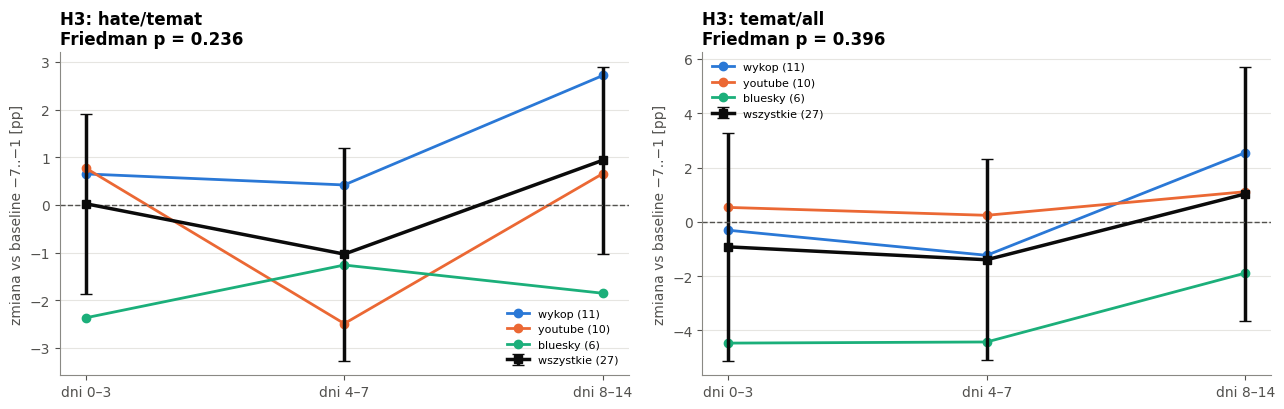

In [32]:
def window_pct(d, col, lo, hi):
    w = d[d["relative_day"].between(lo, hi)]
    return (100 * w[col].mean() if len(w) >= MIN_DAILY_N * (hi - lo + 1) else np.nan), len(w)


h3_rows = []
for metric in METRICS:
    for cell in E(metric).dropna(subset=["log OR"])["cell"]:
        d, col = subset(df[df["cell"] == cell], metric)
        base, nb_ = window_pct(d, col, *BASELINE)
        row = {"miara": metric, "cell": cell, "platform": cell.split(":")[0], "baseline %": base}
        for name, (lo, hi) in H3_WINDOWS.items():
            v, _ = window_pct(d, col, lo, hi)
            row[name] = v - base if pd.notna(v) and pd.notna(base) else np.nan
        h3_rows.append(row)
h3 = pd.DataFrame(h3_rows)

h3_tests = []
for metric in METRICS:
    t = h3[h3["miara"] == metric].dropna(subset=list(H3_WINDOWS))
    fr = friedmanchisquare(*[t[w] for w in H3_WINDOWS]) if len(t) >= 3 else None
    ps = [wilcoxon(t[w]).pvalue if (t[w] != 0).any() else 1.0 for w in H3_WINDOWS]
    h3_tests.append({"miara": metric, "komórek": len(t), "p Friedman": fr.pvalue if fr else np.nan,
                     **{f"{w}: średnio pp": t[w].mean() for w in H3_WINDOWS},
                     **{f"p (Holm) {w} vs baseline": p for w, p in zip(H3_WINDOWS, holm(pd.Series(ps)).values)}})
h3_tests = pd.DataFrame(h3_tests).set_index("miara")
display(fmt_p(h3_tests, 3))

fig, axes = plt.subplots(1, len(METRICS), figsize=(6.5 * len(METRICS), 4.2), squeeze=False)
for ax, metric in zip(axes[0], METRICS):
    t = h3[h3["miara"] == metric].dropna(subset=list(H3_WINDOWS))
    for p in PL:
        tp = t[t["platform"] == p]
        if len(tp):
            ax.plot(list(H3_WINDOWS), tp[list(H3_WINDOWS)].mean(), marker="o", color=PLATFORM_COLORS[p], label=f"{p} ({len(tp)})")
    m, s = t[list(H3_WINDOWS)].mean(), t[list(H3_WINDOWS)].std() / np.sqrt(max(len(t), 1))
    ax.errorbar(list(H3_WINDOWS), m, yerr=1.96 * s, color=INK, lw=2.5, marker="s", capsize=4, label=f"wszystkie ({len(t)})")
    ax.axhline(0, color=INK2, ls="--", lw=1)
    ax.set_ylabel("zmiana vs baseline −7..−1 [pp]")
    ax.set_title(f"H3: {metric}\nFriedman p = {h3_tests.loc[metric, 'p Friedman']:.3g}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8c. Werdykty hipotez

In [33]:
def verdict_h1(metric):
    r = readme[(readme["hipoteza"] == "H1") & (readme["miara"] == metric)].iloc[0]
    sig = (E(metric)["kierunek"] != "–").sum()
    if r["p"] < ALPHA:
        return "potwierdzona" if sig else "częściowo", f"Wilcoxon p = {r['p']:.3g}; istotne komórki: {sig}"
    return ("częściowo" if sig else "brak dowodów"), f"Wilcoxon p = {r['p']:.3g}; istotne komórki: {sig}/{E(metric)['log OR'].notna().sum()}"


def verdict_simple(h, metric, test_contains):
    r = readme[(readme["hipoteza"] == h) & (readme["miara"] == metric) & readme["test"].str.contains(test_contains, regex=False)].iloc[0]
    return ("potwierdzona" if r["p"] < ALPHA else "brak dowodów"), f"{r['test']}: p = {r['p']:.3g}"


rows = []
for metric in METRICS:
    v, why = verdict_h1(metric)
    rows.append({"hipoteza": "H1", "miara": metric, "werdykt": v, "uzasadnienie": why})
    v, why = verdict_simple("H2", metric, "typu")
    rows.append({"hipoteza": "H2", "miara": metric, "werdykt": v, "uzasadnienie": why})
    p3 = h3_tests.loc[metric, "p Friedman"]
    rows.append({"hipoteza": "H3", "miara": metric, "werdykt": "potwierdzona" if p3 < ALPHA else "brak dowodów",
                 "uzasadnienie": f"Friedman p = {p3:.3g}"})
    vr, wr = verdict_simple("H4", metric, "reakcja")
    vl, wl = verdict_simple("H4", metric, "poziom")
    v = "potwierdzona" if vr == "potwierdzona" else ("częściowo" if vl == "potwierdzona" else "brak dowodów")
    rows.append({"hipoteza": "H4", "miara": metric, "werdykt": v, "uzasadnienie": f"{wr}; {wl}"})
verdicts = pd.DataFrame(rows).set_index(["hipoteza", "miara"])
display(verdicts)

,,werdykt,uzasadnienie
hipoteza,miara,,
H1,hate/temat,częściowo,Wilcoxon p = 0.991; istotne komórki: 2/27
H2,hate/temat,brak dowodów,Kruskal–Wallis: zmiana pp wg typu: p = 0.299
H3,hate/temat,brak dowodów,Friedman p = 0.236
H4,hate/temat,częściowo,Kruskal–Wallis: reakcja (zmiana pp): p = 0.172; Kruskal–Wallis: poziom (przed %): p = 1.76e-05
H1,temat/all,częściowo,Wilcoxon p = 0.47; istotne komórki: 3/27
H2,temat/all,brak dowodów,Kruskal–Wallis: zmiana pp wg typu: p = 0.194
H3,temat/all,brak dowodów,Friedman p = 0.396
H4,temat/all,częściowo,Kruskal–Wallis: reakcja (zmiana pp): p = 0.869; Kruskal–Wallis: poziom (przed %): p = 3.16e-05


### Wnioski z analiz dodatkowych

- **H1 (Wilcoxon):** brak zmiany przed → po: p = 0,99, r ≈ 0; wzrost w 12 z 27 komórek, mediana zmiany −0,6 pp.
  Istotne po Holmie tylko 2 komórki: naloty ICE na Wykopie (24% → 32%, ↑) i Ceuta na Bluesky (↓). → **częściowo**
  (pojedyncze wydarzenia, brak efektu ogólnego; tak samo metaanaliza w sekcji 1d: OR 1,01, p = 0,72).
- **H2 (Kruskal–Wallis):** p = 0,30, Dunn bez istotnych par. → **brak dowodów.**
- **H3 (Friedman):** p = 0,24; średnia zmiana +0,0 / −1,0 / +0,9 pp w dniach 0–3 / 4–7 / 8–14, żadne okno nie różni się od
  baseline. Nie ma szczytu tuż po wydarzeniu ani wygasania. → **brak dowodów** (ta sama odpowiedź co w LLM-owej analizie).
- **H4 (Kruskal–Wallis):** **poziom** hejtu w temacie migracji różni się między platformami (p < 0,001): YouTube 44% >
  Wykop 34% > Bluesky 19% (Dunn: YouTube różni się od obu, Wykop vs Bluesky p = 0,06); **reakcja** na wydarzenia – nie
  (p = 0,17). → **częściowo: różny poziom, ta sama reakcja.**
- **Podsumowanie:** na 11 wydarzeniach i hejcie z HerBERT-a obraz jest taki sam jak w analizie Oli na LLM: wydarzenia nie
  podnoszą systematycznie hejtu, efekty są pojedyncze i w różne strony, platformy różnią się poziomem, nie reakcją.